In [1]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector
from qiskit import QuantumCircuit, QuantumRegister

from ApproximateEncoder import ApproximateEncoder
from GroverSearch import GroverSearch
from Visualization import state_analysis
from Loader import save_parameters, load_parameters

In [3]:
num_of_elements = 16
num_of_features = 4

hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features - 1, -1, -1)] for h in hex_images]

query_index = 11  
query = dataset[query_index]

In [4]:
dataset

[[0, 0, 0, 0],
 [0, 0, 0, 1],
 [0, 0, 1, 0],
 [0, 0, 1, 1],
 [0, 1, 0, 0],
 [0, 1, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 1, 1],
 [1, 0, 0, 0],
 [1, 0, 0, 1],
 [1, 0, 1, 0],
 [1, 0, 1, 1],
 [1, 1, 0, 0],
 [1, 1, 0, 1],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]

In [5]:
query_index

11

In [6]:
query

[1, 0, 1, 1]

# <u>**Part 1: Approximate Encoding Using PQC**</u>

Example for NEQR encoding scheme:

|dataset> = 1/root(N_I*N_D) summation |value> |feature no> |index>
            = |q6 q5 q4 q3 q2 q1 q0>
            = |v> |f1 f0> |i3 i2 i1 i0>

In [7]:
encoder = ApproximateEncoder()

## <u>**Encoding with NEQR scheme and MMD cost function**</u>

In [8]:
# A_parameters_neqr_mmd = encoder.generate_encoding(dataset, scheme="NEQR", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_enocder, learning_rate=learning_rate_dataset_encoder, loss_function_type="MMD")

In [9]:
# B_parameters_neqr_mmd = encoder.generate_encoding(query, scheme="NEQR", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.005, loss_function_type="MMD")

## <u>**Encoding with NEQR scheme and FIDELITY cost function**</u>

Fidelity ignore global phase but captures relative phase.

Example, 

{a|0> + b|1>} and {-a|0>-b|1>} are physically identical

But for (|0>+|1>)/root(2) and (|0>-|1>)/root(2), fidelity is zero (different states)

In [10]:
pqc_depth_for_dataset_encoder = 8
pqc_depth_for_query_encoder = 3
epochs_dataset_encoder = 500
learning_rate_dataset_encoder = 0.08

In [11]:
# Load previously saved A, if available
A_saved_best_fidelity = 0

try:
    A_saved = load_parameters(scheme="NEQR", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.6f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset encoder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.985157



> Preparing dataset target state....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 64

> Starting training....

Number of parameters = 56

> Using adam optimization....
Epoch 1 - Loss 0.9780289993283694 - Fidelity 0.021971000671630617
Epoch 2 - Loss 0.9433903459844676 - Fidelity 0.05660965401553243
Epoch 3 - Loss 0.8992786935932695 - Fidelity 0.10072130640673047
Epoch 4 - Loss 0.8492344013151992 - Fidelity 0.1507655986848008
Epoch 5 - Loss 0.802524885388864 - Fidelity 0.197475114611136
Epoch 6 - Loss 0.7624033265430142 - Fidelity 0.23759667345698576
Epoch 7 - Loss 0.7310707599855611 - Fidelity 0.26892924001443885
Epoch 8 - Loss 0.7039820817765208 - Fidelity 0.2960179182234792
Epoch 9 - Loss 0.6737474345415613 - Fidelity 0.32625256545843867
Epoch 10 - Loss 0.6404496615670139 - Fidelity 0.3595503384329861
Epoch 11 - Loss 0.6098146062249229 - Fidelity 0.3901853937750771
Epoch 12 - Loss 0.5869401313316215 - Fidelity 0.4130598686683785
Epoch 13 - Loss 0.5714833121405913 - Fidelity 0.4285166878594087
Epoch 14 - Loss 0.5602300806414484 

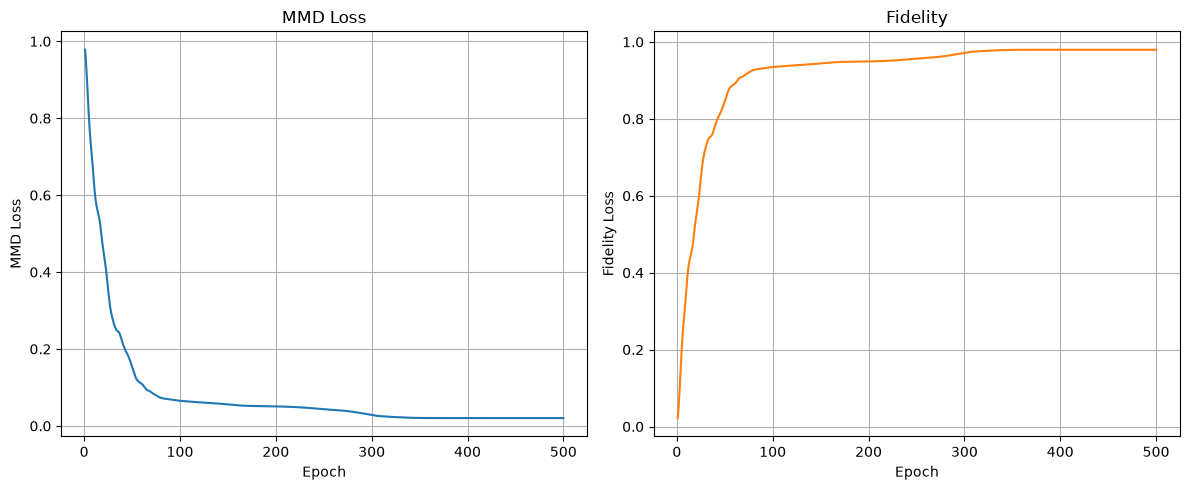


> Training finished.
Number of qubits: 7
Circuit depth (layers): 8
Number of parameters: 56
Best fidelity achieved: 0.97961484


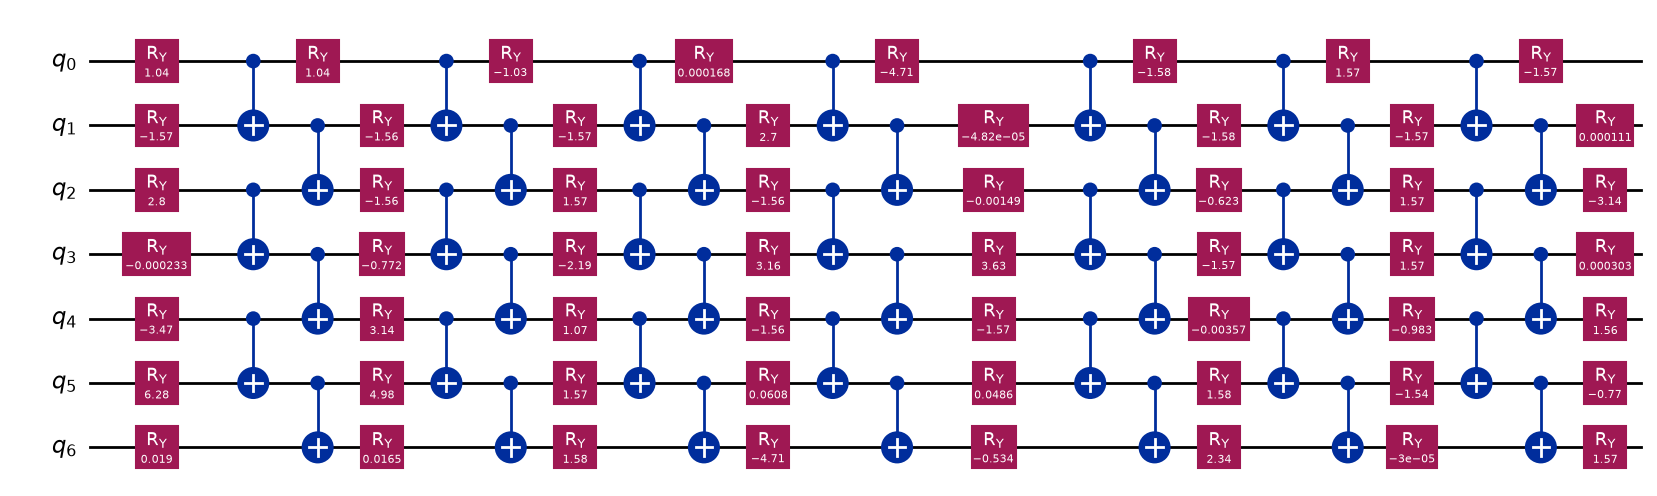


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.97961484


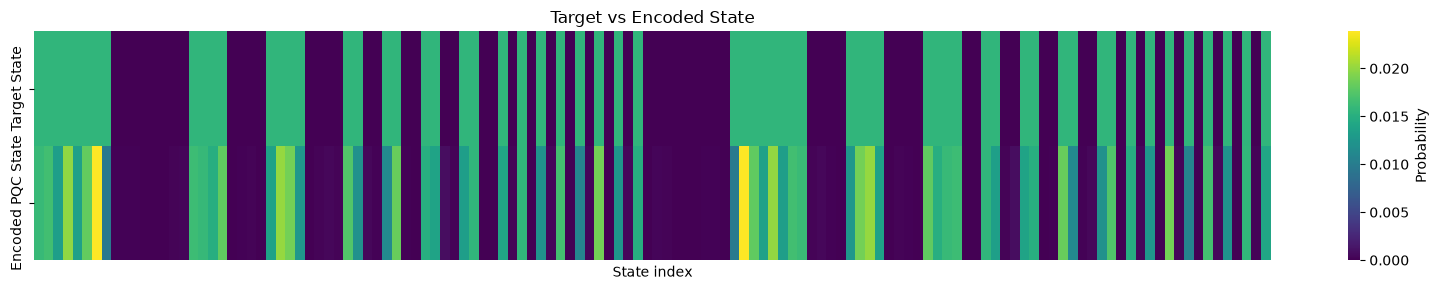

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

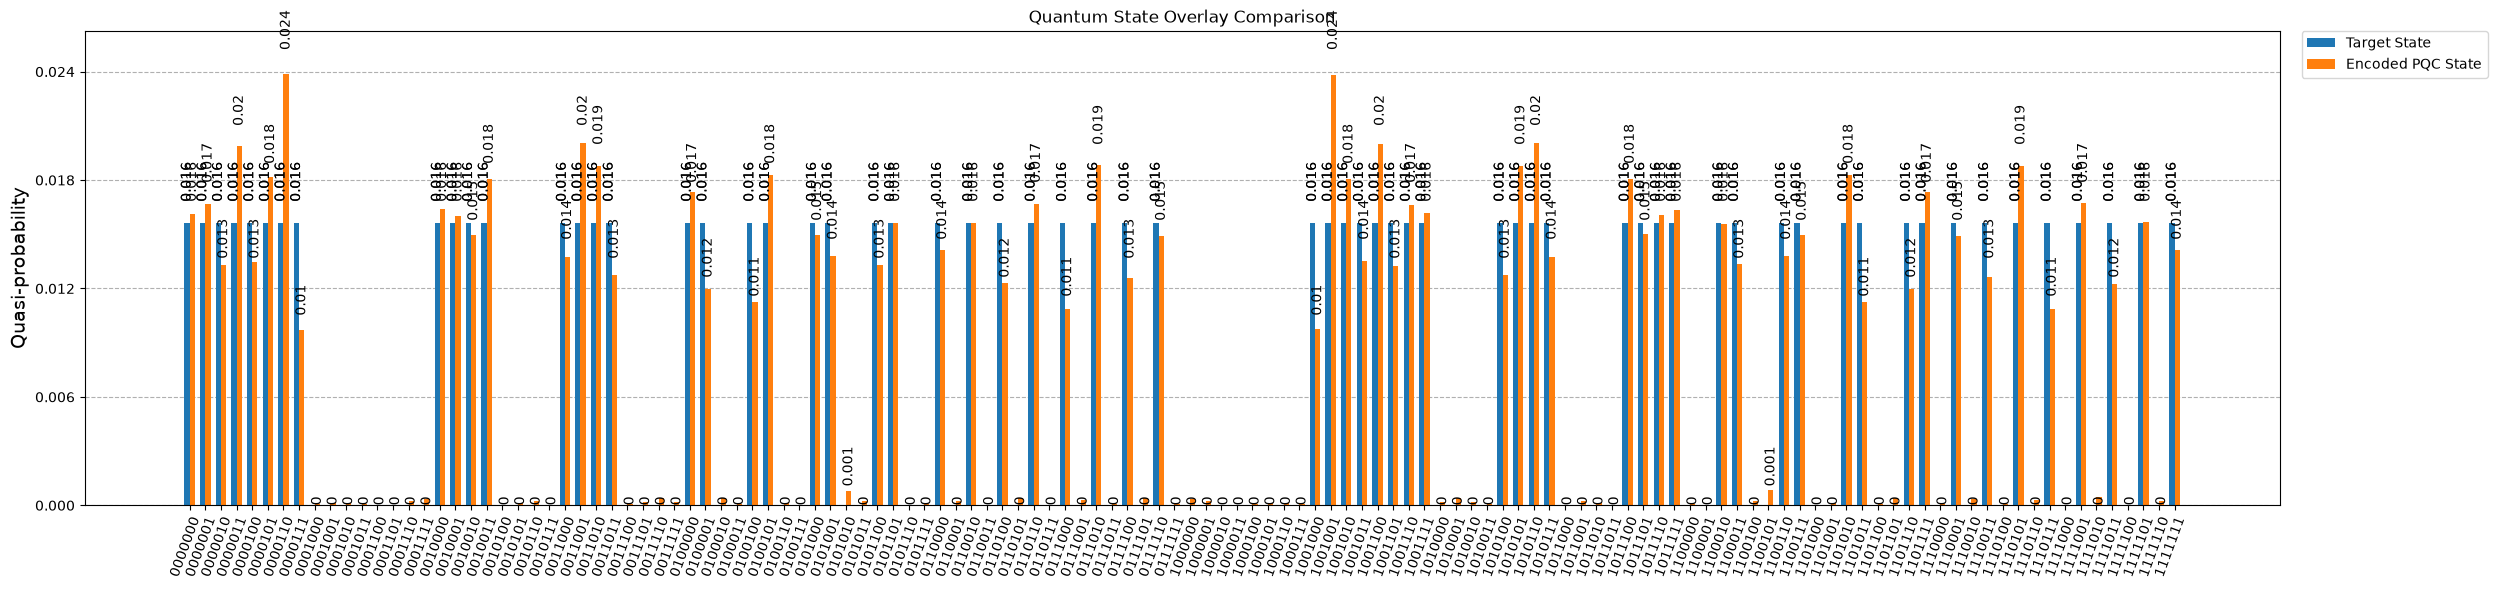


TARGET STATE
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.000                   
0                        1                        +0.125                   +0.000                   
0                        2                        +0.125                   +0.000                   
0                        3                        +0.125                   +0.000                   
1                        0                        +0.125                   +0.000                   
1                        1                        +0.125                   +0.000                   
1                        2                        +0.125                   +0.000                   
1                        3                        +0.000                   +0

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.12688753769503394+0j)
|0000001> : (0.12910716591813487+0j)
|0000010> : (0.11528120112652751+0j)
|0000011> : (0.14109588563967693+0j)
|0000100> : (0.11602439461360423+0j)
|0000101> : (0.1347210076678252+0j)
|0000110> : (0.15449663082823598+0j)
|0000111> : (0.09839472664157058+0j)
|0001000> : (-0.009710271763770892+0j)
|0001001> : (0.010392713917441374+0j)
|0001010> : (-0.010662050020397837+0j)
|0001011> : (0.00811822681969505+0j)
|0001100> : (-0.004421659885483629+0j)
|0001101> : (0.0012737121833642385+0j)
|0001110> : (0.015044403059225586+0j)
|0001111> : (-0.018736290121110905+0j)
|0010000> : (0.12795635923052728+0j)
|0010001> : (0.12659788243349968+0j)
|0010010> : (0.12221328429668762+0j)
|0010011> : (0.13444845904516356+0j)
|0010100> : (-0.005821274124103082+0j)
|0010101> : (0.010987619892194985+0j)
|0010110> : (0.015903601495365773+0j)
|0010111> : (0.0005032516975263072+0j)
|0011000> : (0.11731970671629556+0j)
|0011001> : (0.1416529746982

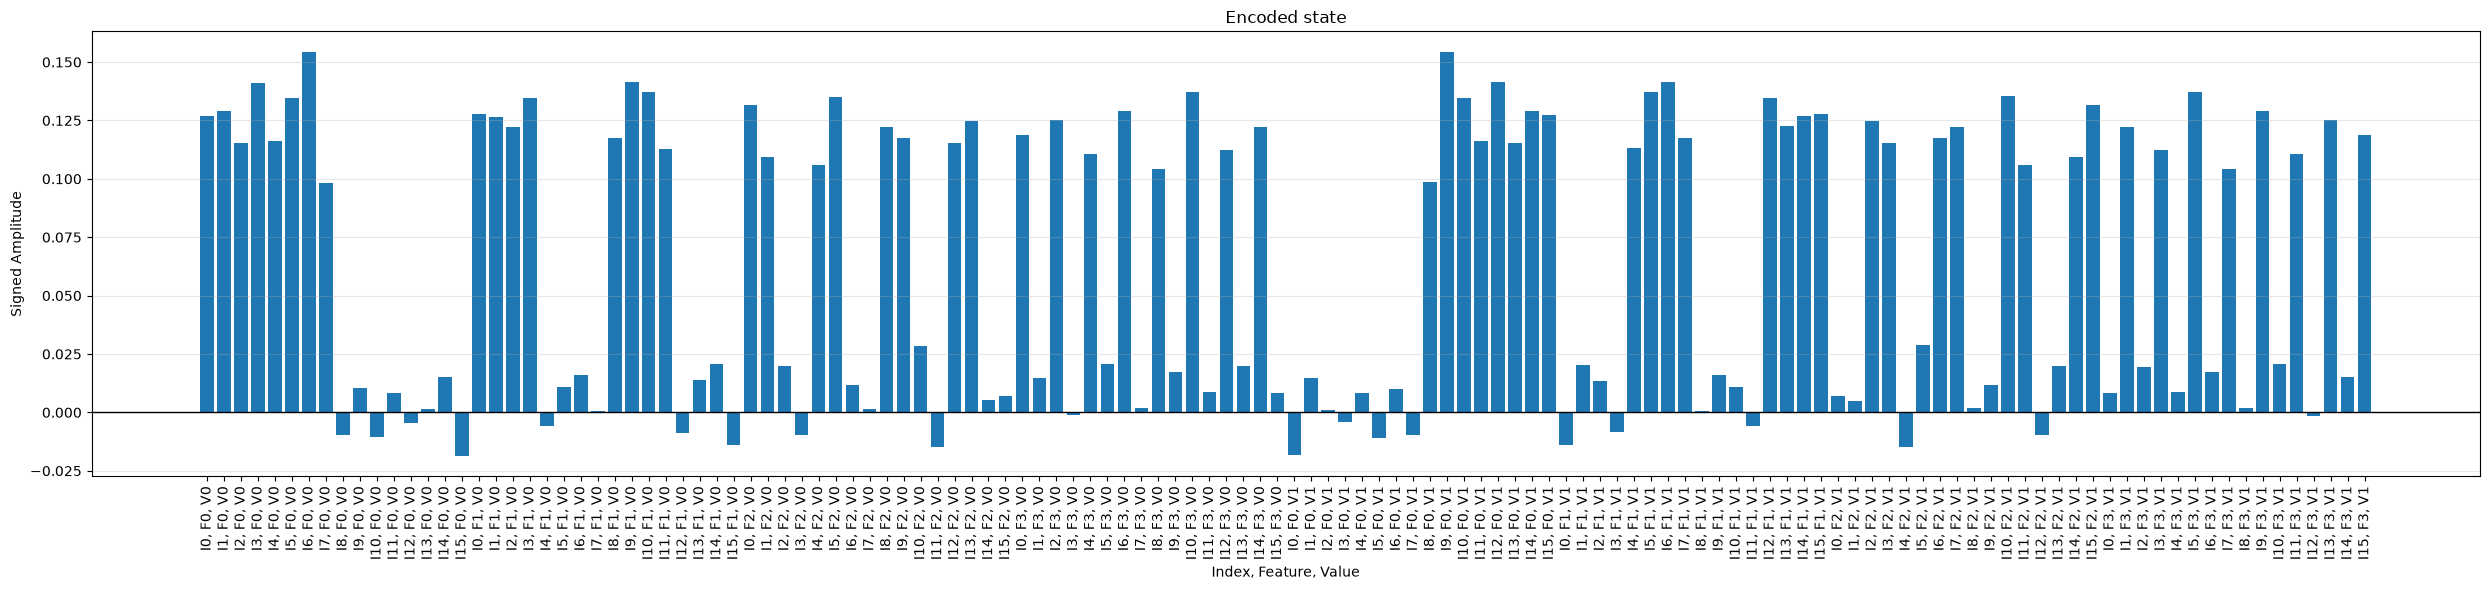


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


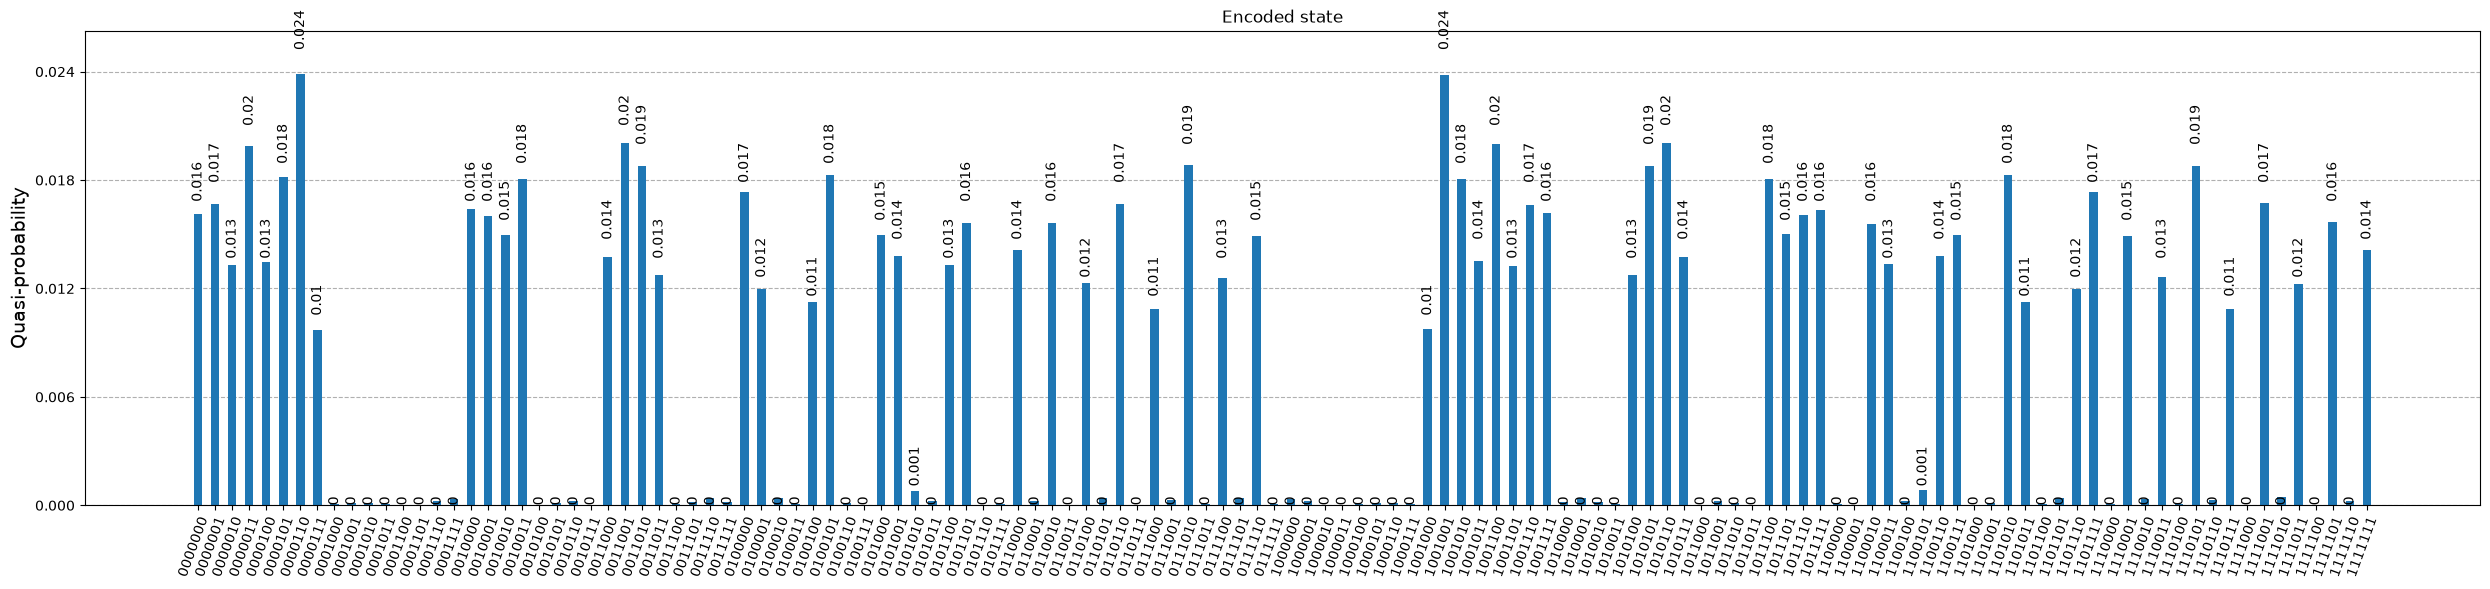

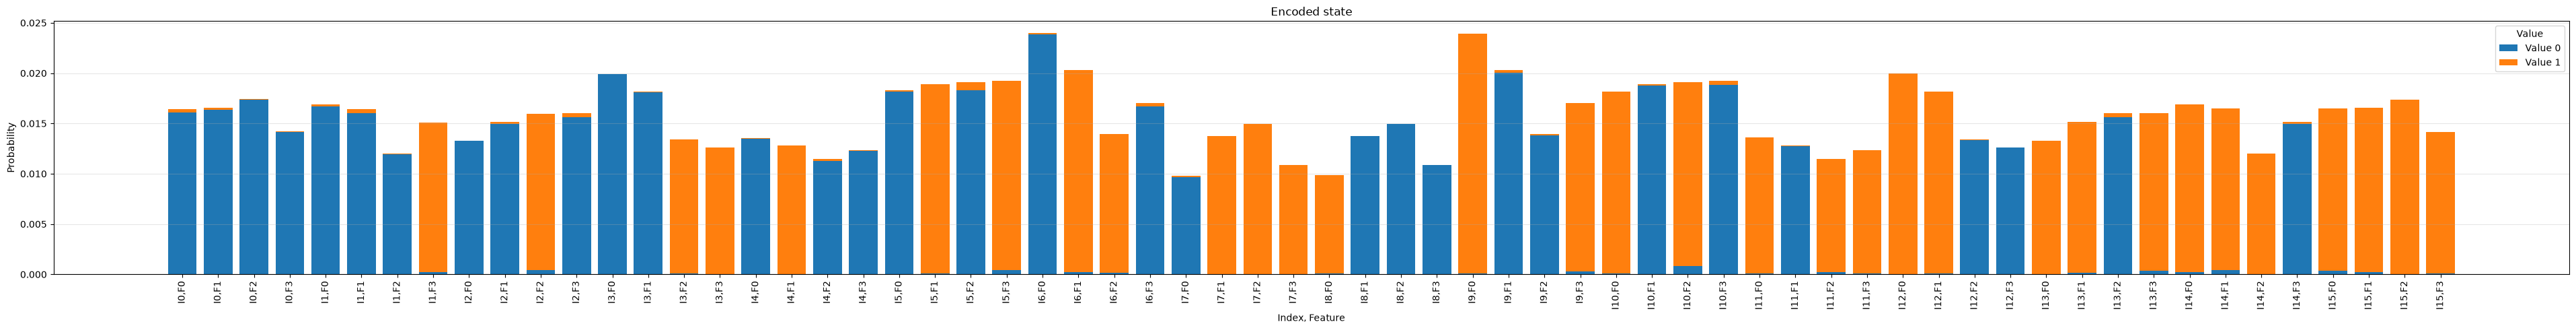


Encoded state
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.127                   -0.018                   
0                        1                        +0.128                   -0.014                   
0                        2                        +0.132                   +0.007                   
0                        3                        +0.119                   +0.008                   
1                        0                        +0.129                   +0.015                   
1                        1                        +0.127                   +0.020                   
1                        2                        +0.109                   +0.005                   
1                        3                        +0.015                   +

In [12]:
A_parameters, A_best_fidelity = encoder.generate_encoding(dataset, scheme="NEQR", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, learning_rate=learning_rate_dataset_encoder, loss_function_type="FIDELITY")

In [13]:
if A_best_fidelity > A_saved_best_fidelity:
    save_parameters(
        A_parameters,
        depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, 
        learning_rate=learning_rate_dataset_encoder, fidelity=A_best_fidelity,
        scheme="NEQR", loss_function_type="FIDELITY"
    )

    print("New dataset encoder has better fidelity. Saved the new parameters.")

else:
    print(f"New dataset encoder did not improve fidelity {A_saved_best_fidelity}. Keeping the previous best parameters.")

print(f"Final best dataset encoder fidelity = {A_best_fidelity:.6f}")

New dataset encoder did not improve fidelity 0.9851574558504578. Keeping the previous best parameters.
Final best dataset encoder fidelity = 0.979615



> Preparing query target state....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 4

> Starting training....

Number of parameters = 9

> Using adam optimization....
Epoch 1 - Loss 0.7536694199031233 - Fidelity 0.24633058009687672
Epoch 2 - Loss 0.6932617651335324 - Fidelity 0.3067382348664676
Epoch 3 - Loss 0.6475102697531232 - Fidelity 0.35248973024687674
Epoch 4 - Loss 0.6141819313074973 - Fidelity 0.3858180686925027
Epoch 5 - Loss 0.5849797508113557 - Fidelity 0.41502024918864433
Epoch 6 - Loss 0.547528900322604 - Fidelity 0.4524710996773959
Epoch 7 - Loss 0.4931303655314633 - Fidelity 0.5068696344685367
Epoch 8 - Loss 0.4227954041206021 - Fidelity 0.5772045958793979
Epoch 9 - Loss 0.3431288590683522 - Fidelity 0.6568711409316478
Epoch 10 - Loss 0.2627841478706394 - Fidelity 0.7372158521293606
Epoch 11 - Loss 0.1897502662187125 - Fidelity 0.8102497337812875
Epoch 12 - Loss 0.13036172488829634 - Fidelity 0.8696382751117037
Epoch 13 - Loss 0.08854555538848108 - Fidelity 0.9114544446115189
Epoch 14 - Loss 0.06504857924290552 - 

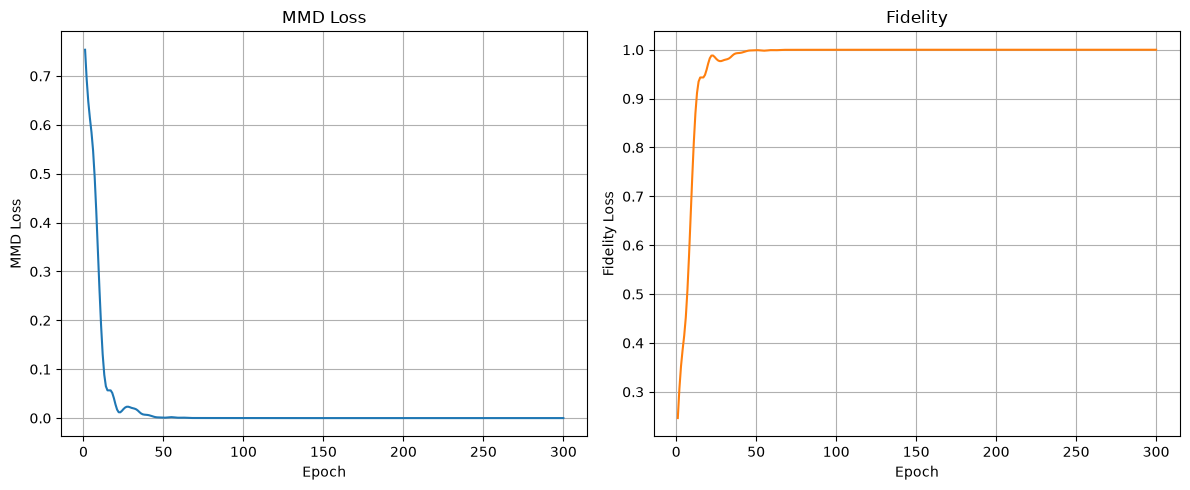


> Training finished.
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Best fidelity achieved: 0.99999951


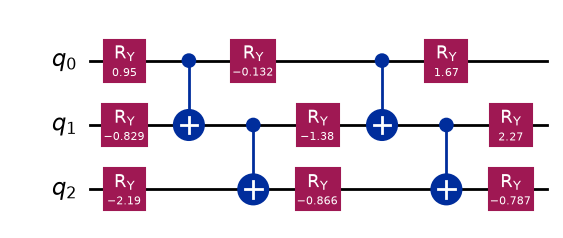


Data =  [1 0 1 1]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99999951


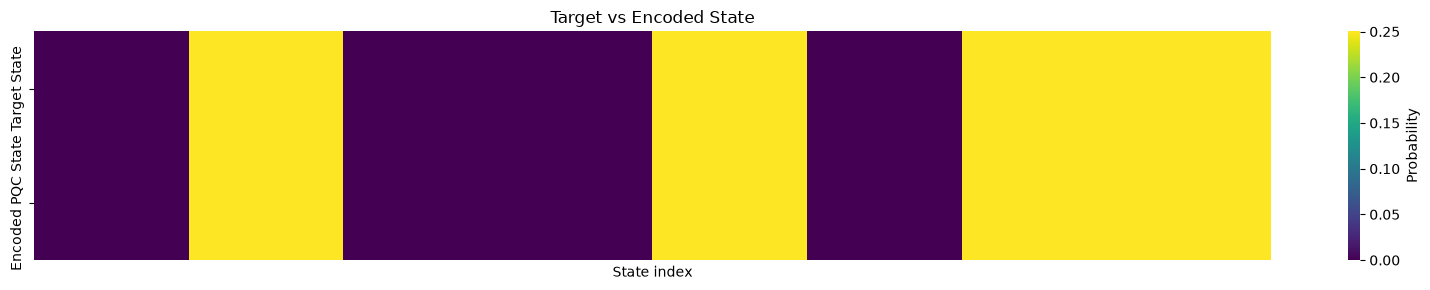

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

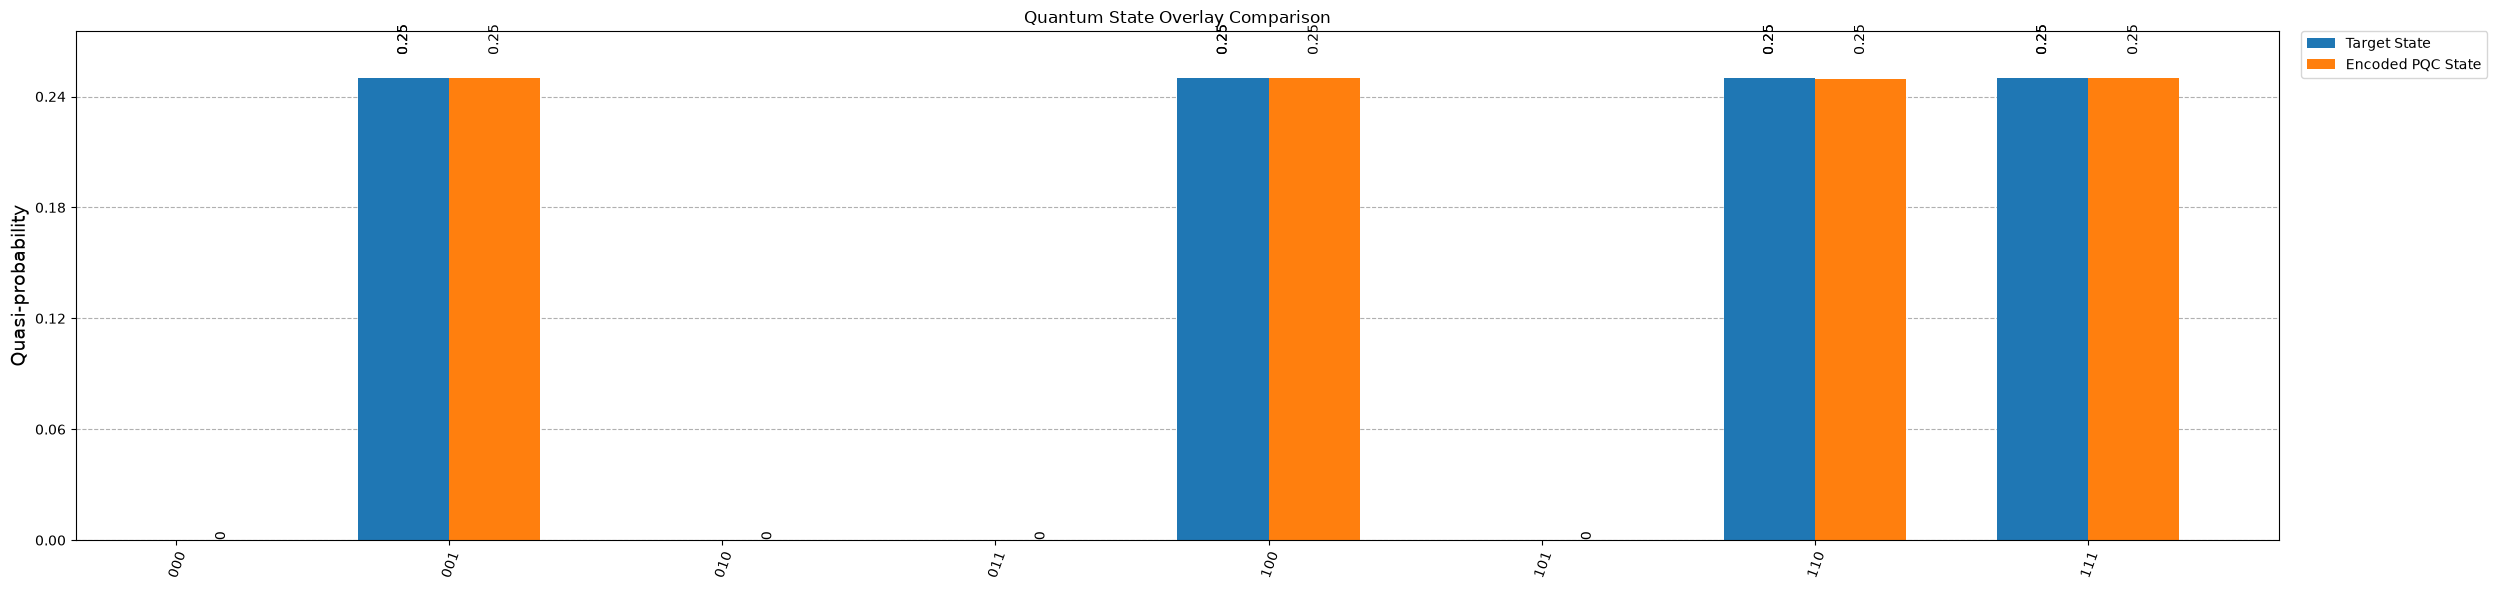


TARGET STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.000                   +0.500                   
1                        +0.500                   +0.000                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   

ENCODED STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        -0.000                   -0.500                   
1                        -0.500                   +0.000                   
2                        +0.000                   -0.500                   
3                        -0.000                   -0.500                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000> : (-0.00027644834340165167+0j)
|001> : (-0.49993797774056126+0j)
|010> : (4.222619267825141e-05+0j)
|011> : (-0.00035465866188577074+0j)
|100> : (-0.5002438257239799+0j)
|110> : (-0.4995882699032875+0j)
|111> : (-0.5002294371767797+0j)


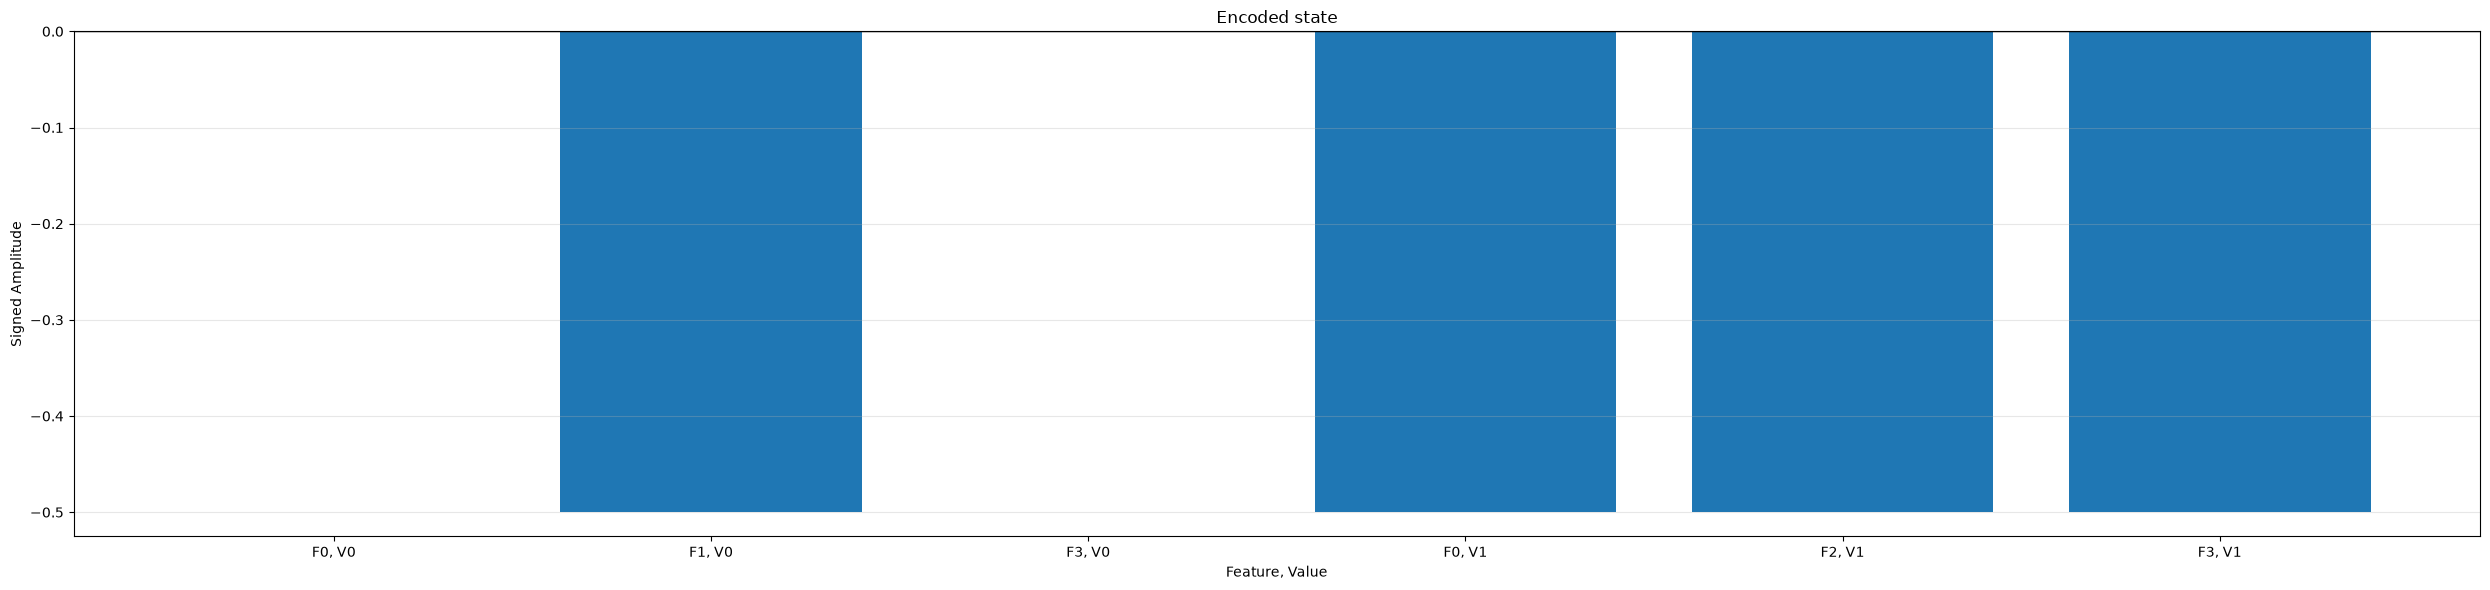


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


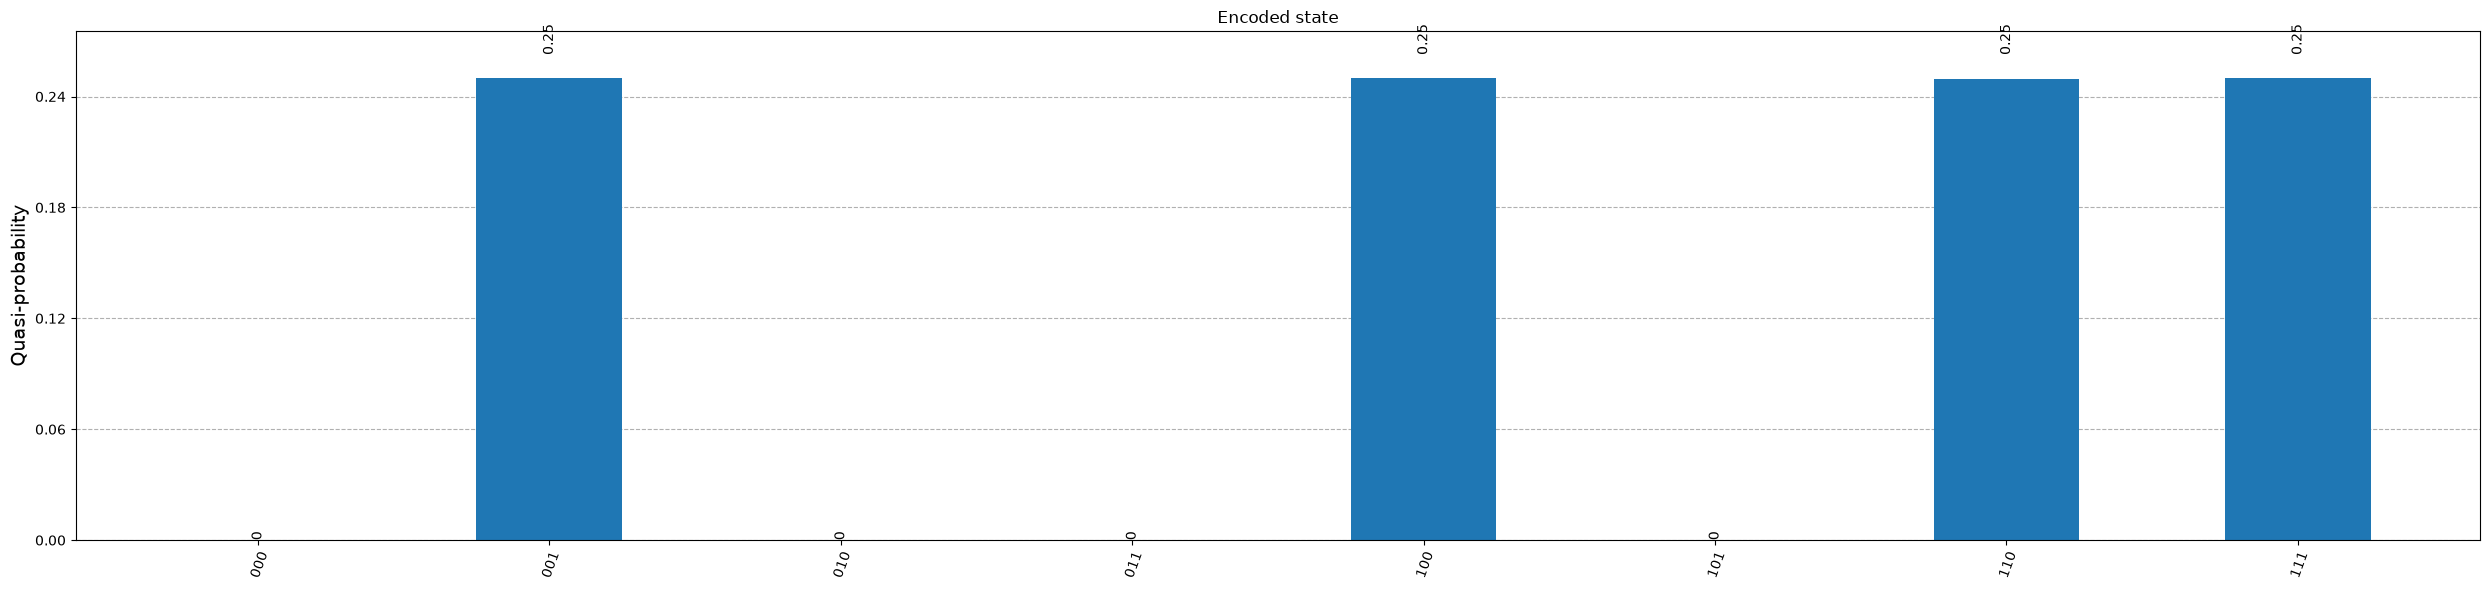

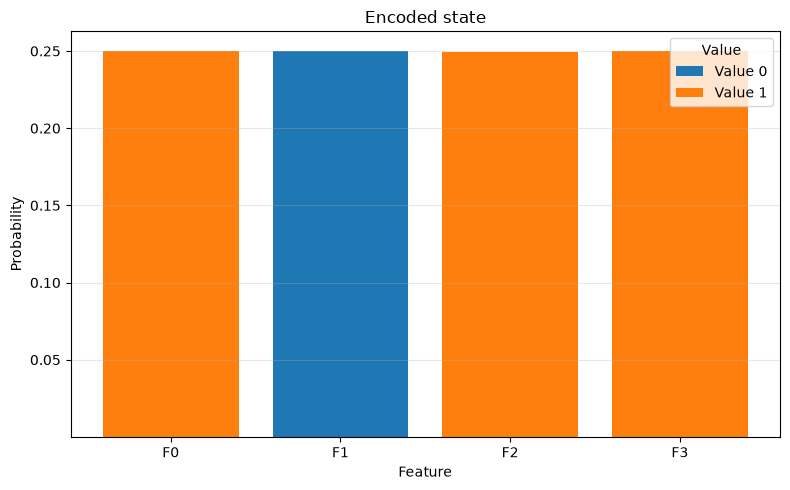


Encoded state
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        -0.000                   -0.500                   
1                        -0.500                   +0.000                   
2                        +0.000                   -0.500                   
3                        -0.000                   -0.500                   


In [14]:
B_parameters_neqr_fidelity, _ = encoder.generate_encoding(query, scheme="NEQR", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY")

## <u>**U operation**</u>

U = (B† ⊗ I_I) A

In [15]:
n_index_q = math.ceil(math.log2(len(dataset)))
n_feature_q = math.ceil(math.log2(len(dataset[0])))

max_value = int(np.max(dataset))
n_value_q = max(1, math.ceil(math.log2(max_value + 1)))
print("Index qubits = ", n_index_q)
print("Feature qubits = ", n_feature_q)
print("Value qubits = ", n_value_q)

Index qubits =  4
Feature qubits =  2
Value qubits =  1


In [16]:
A = encoder.pqc(
    A_parameters, depth=pqc_depth_for_dataset_encoder, n_qubits=(n_index_q + n_feature_q + n_value_q)
)

In [17]:
B = encoder.pqc(
    B_parameters_neqr_fidelity, depth=pqc_depth_for_query_encoder, n_qubits=(n_value_q + n_feature_q)
)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (1+0j)


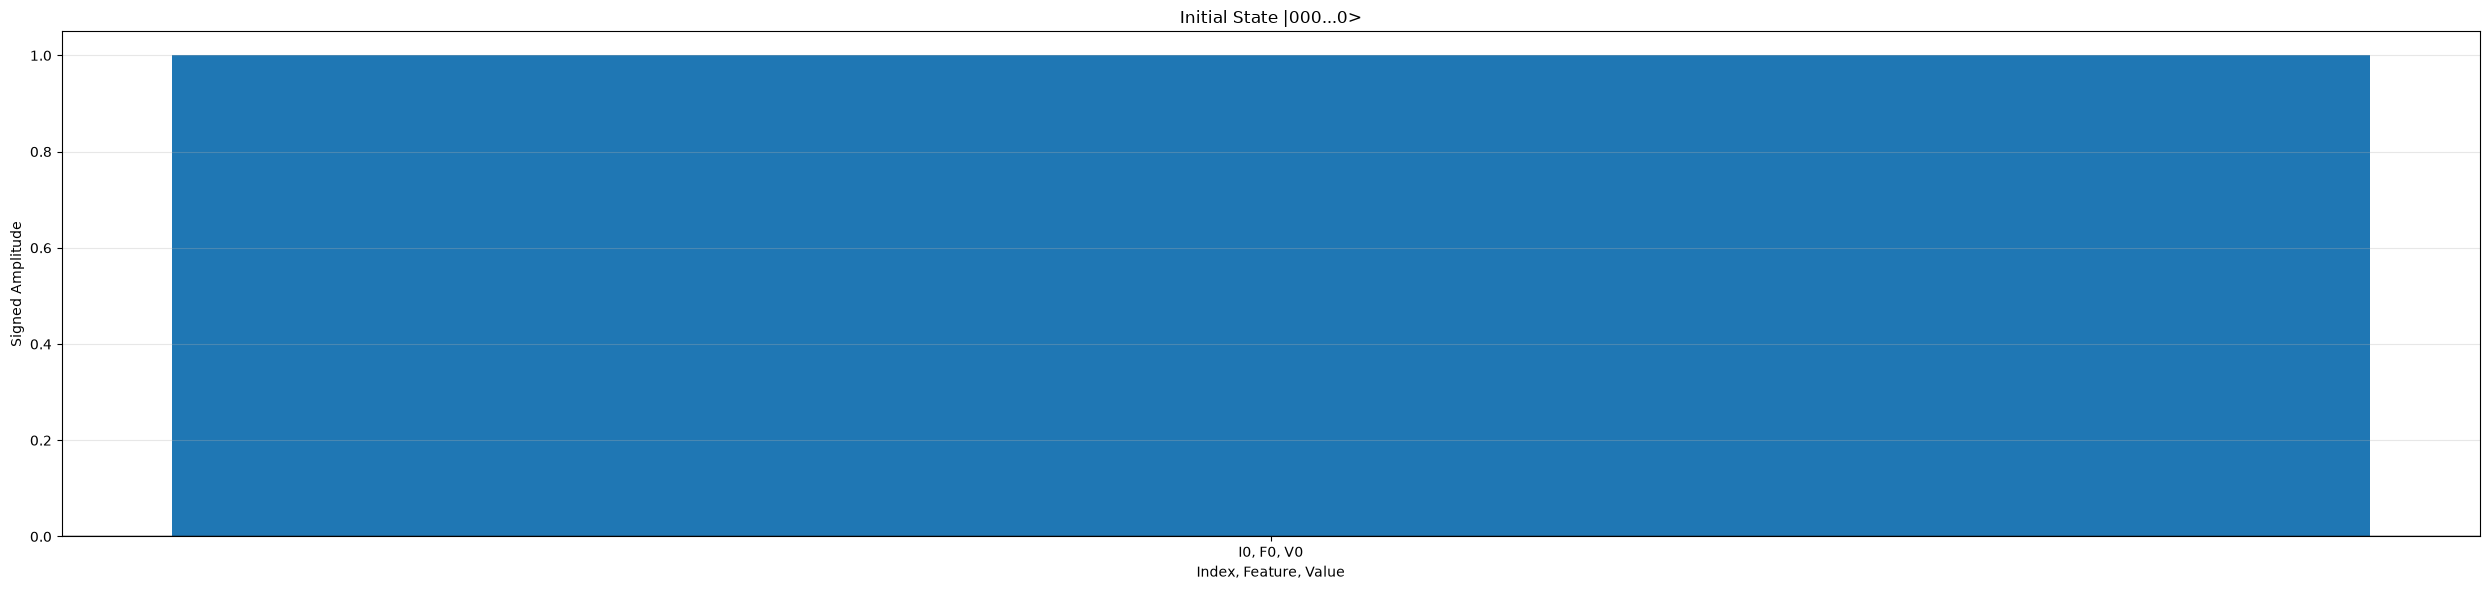


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


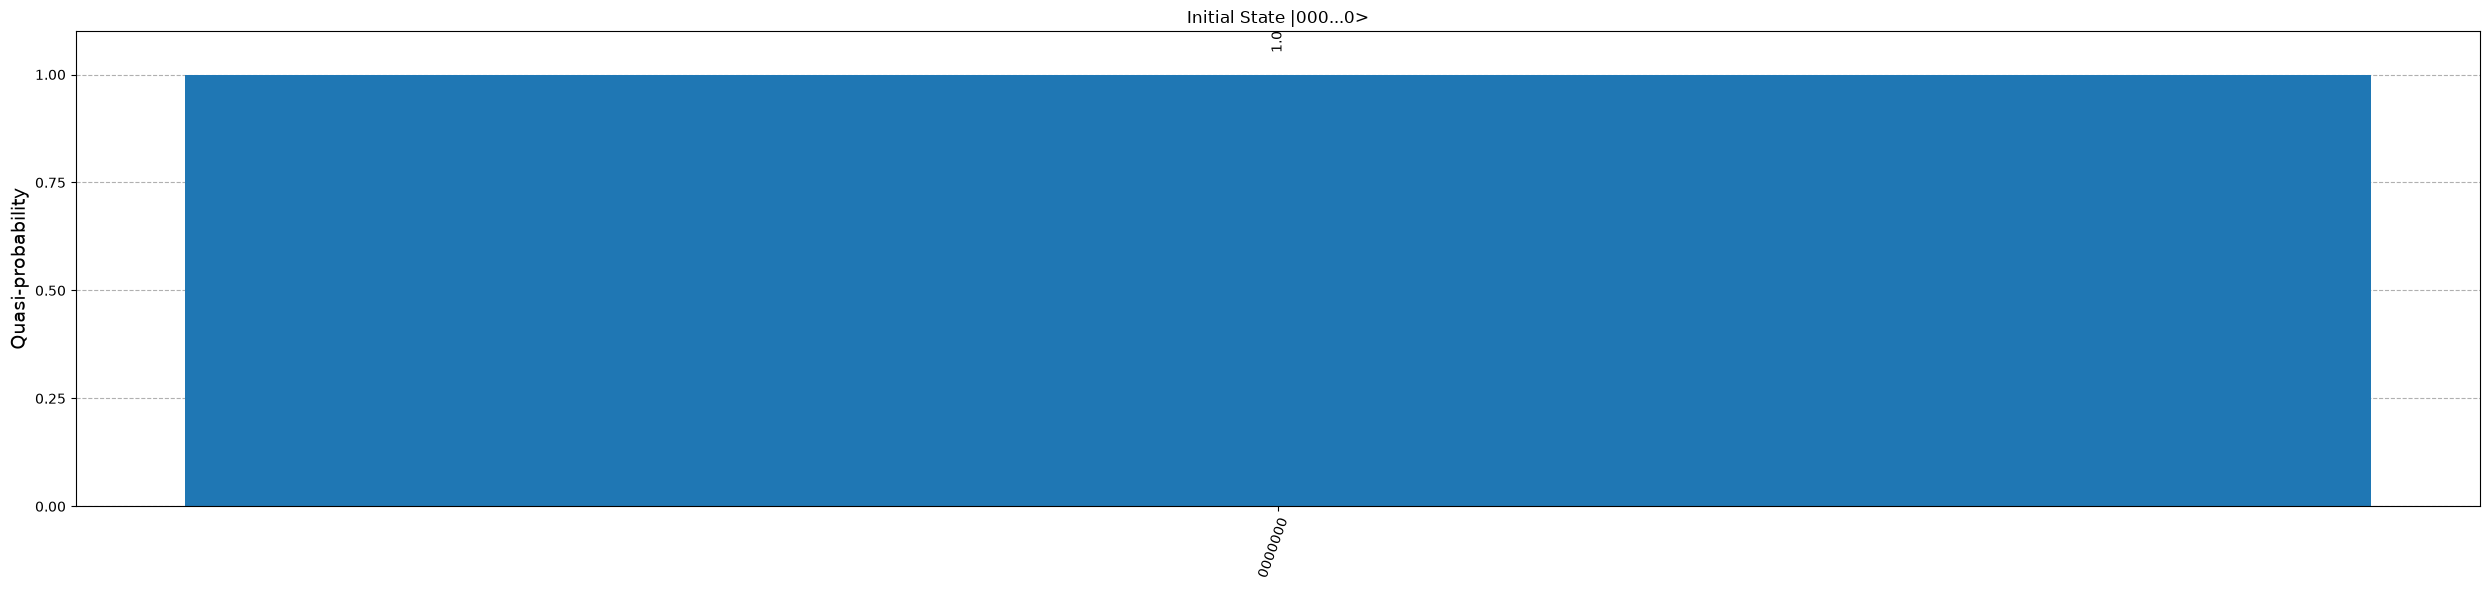

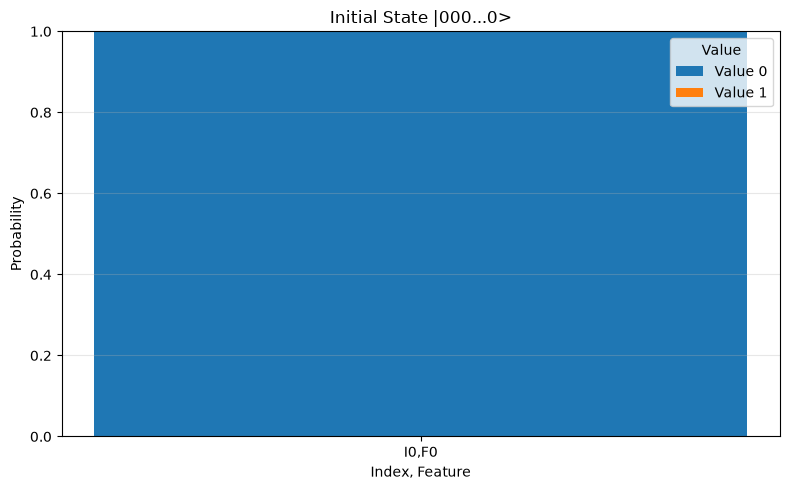


Initial State |000...0>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +1.000                   +0.000                   


In [18]:
value_reg = QuantumRegister(n_value_q)
feature_reg = QuantumRegister(n_feature_q)
index_reg = QuantumRegister(n_index_q)
qc = QuantumCircuit(value_reg, feature_reg, index_reg)

initial_state = Statevector.from_instruction(qc)
state_analysis(initial_state, "Initial State |000...0>", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.12688753769503394+0j)
|0000001> : (0.12910716591813487+0j)
|0000010> : (0.11528120112652751+0j)
|0000011> : (0.14109588563967693+0j)
|0000100> : (0.11602439461360423+0j)
|0000101> : (0.1347210076678252+0j)
|0000110> : (0.15449663082823598+0j)
|0000111> : (0.09839472664157058+0j)
|0001000> : (-0.009710271763770892+0j)
|0001001> : (0.010392713917441374+0j)
|0001010> : (-0.010662050020397837+0j)
|0001011> : (0.00811822681969505+0j)
|0001100> : (-0.004421659885483629+0j)
|0001101> : (0.0012737121833642385+0j)
|0001110> : (0.015044403059225586+0j)
|0001111> : (-0.018736290121110905+0j)
|0010000> : (0.12795635923052728+0j)
|0010001> : (0.12659788243349968+0j)
|0010010> : (0.12221328429668762+0j)
|0010011> : (0.13444845904516356+0j)
|0010100> : (-0.005821274124103082+0j)
|0010101> : (0.010987619892194985+0j)
|0010110> : (0.015903601495365773+0j)
|0010111> : (0.0005032516975263072+0j)
|0011000> : (0.11731970671629556+0j)
|0011001> : (0.1416529746982

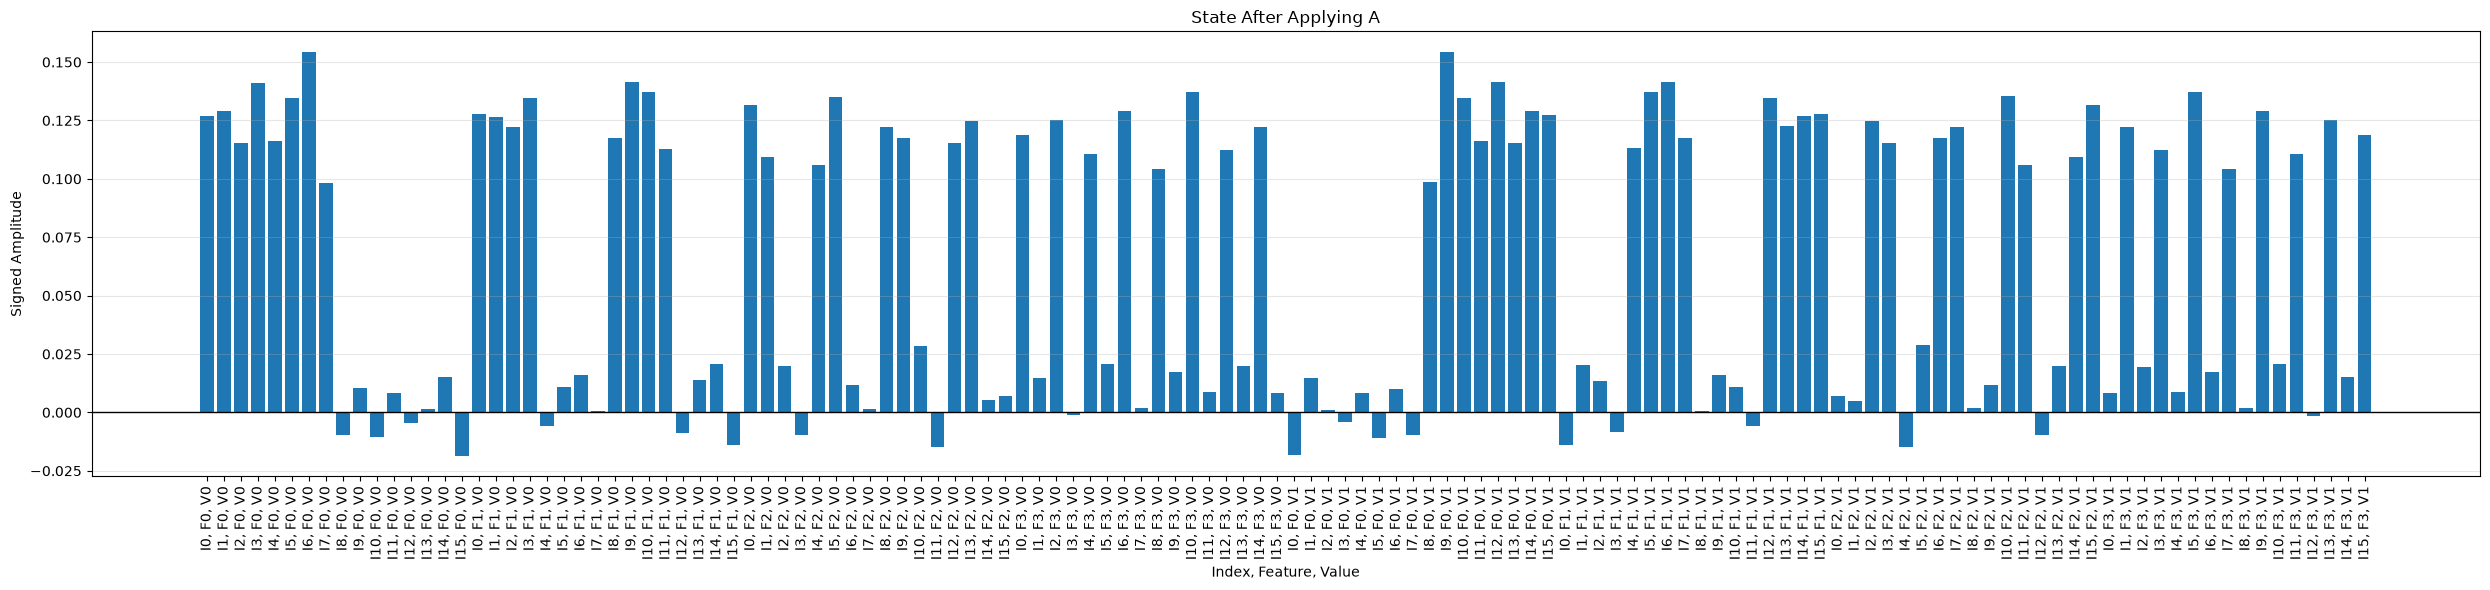


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


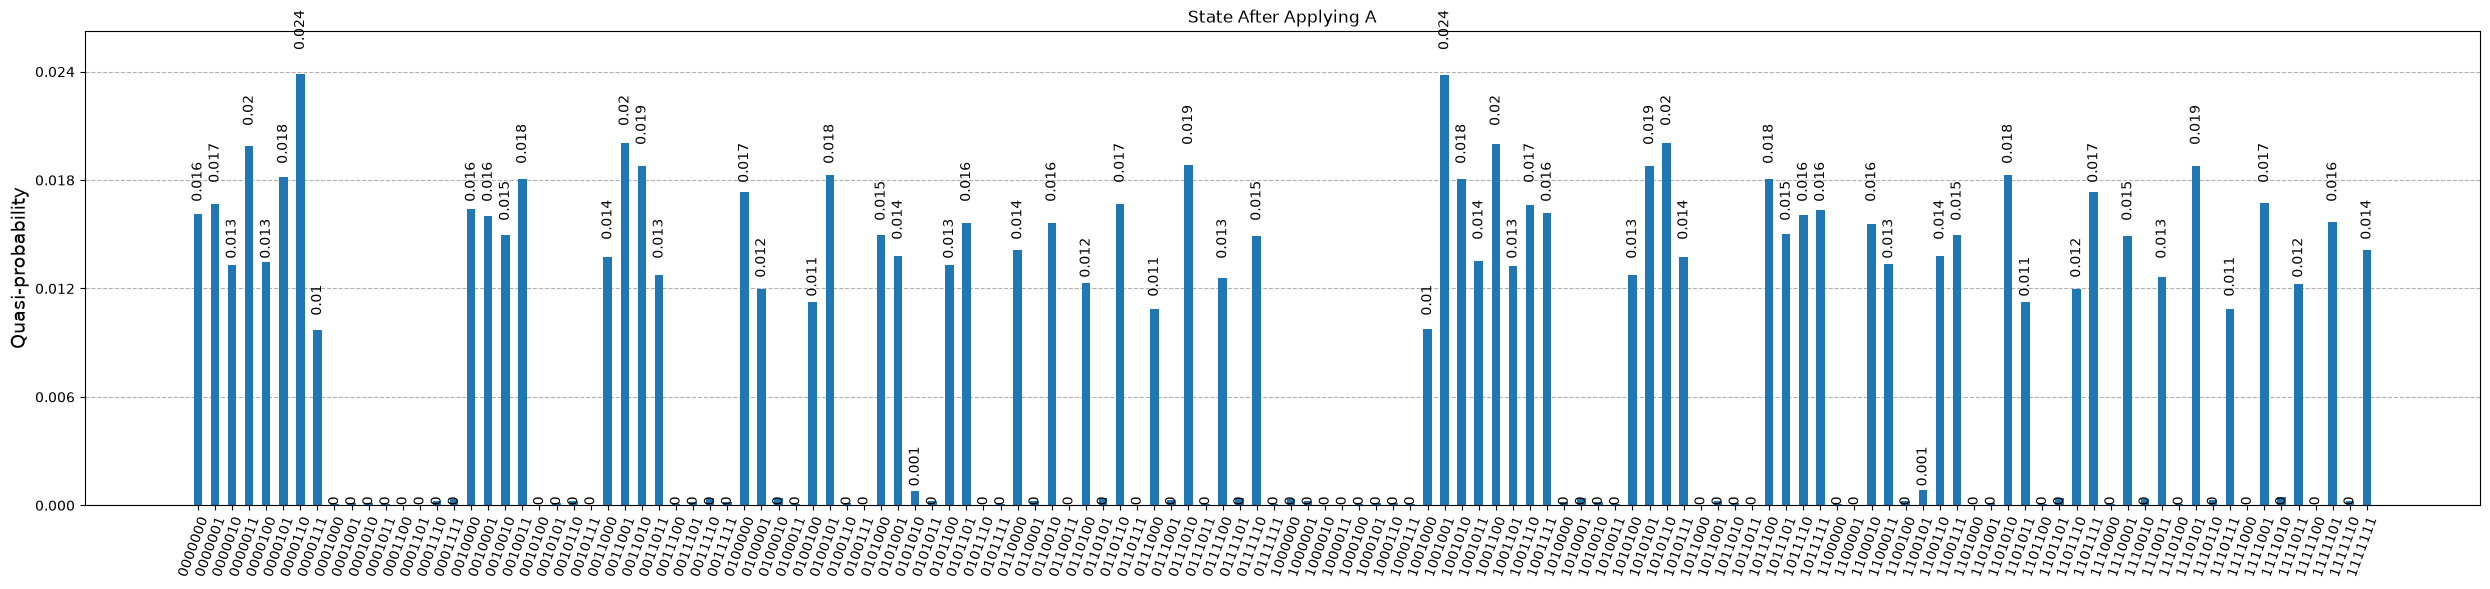

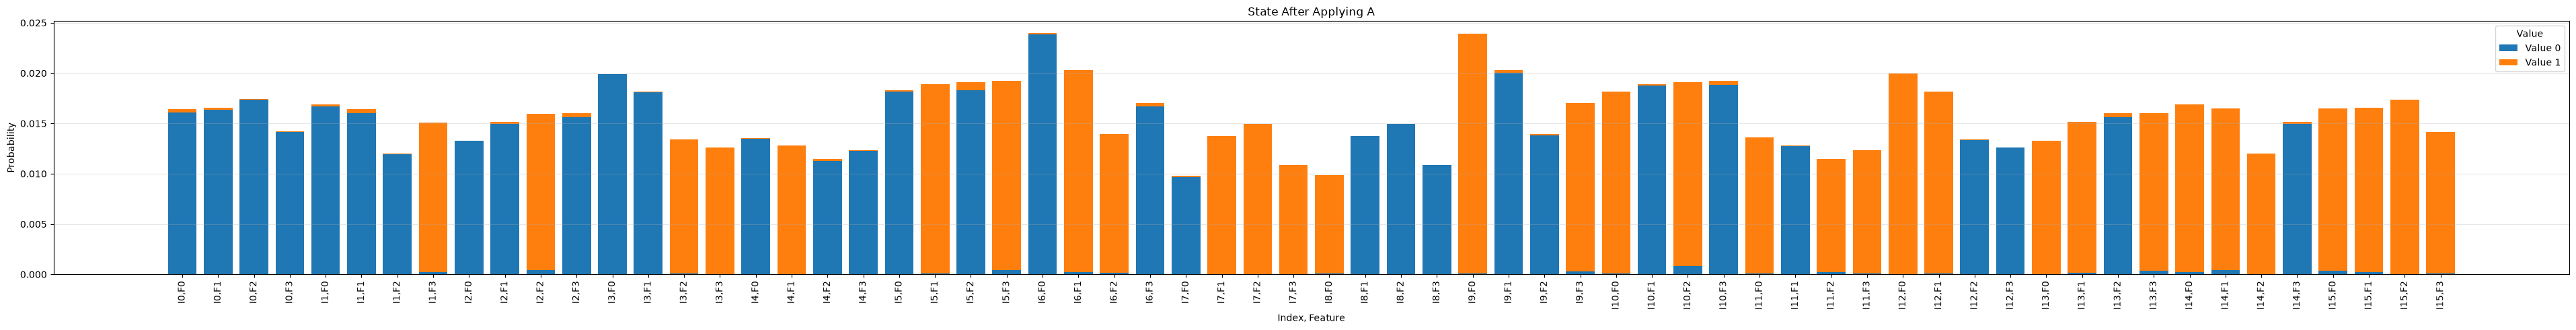


State After Applying A
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.127                   -0.018                   
0                        1                        +0.128                   -0.014                   
0                        2                        +0.132                   +0.007                   
0                        3                        +0.119                   +0.008                   
1                        0                        +0.129                   +0.015                   
1                        1                        +0.127                   +0.020                   
1                        2                        +0.109                   +0.005                   
1                        3                        +0.015           

In [19]:
qc.compose(A, inplace=True)
qc.barrier()

state_after_A = Statevector.from_instruction(qc)

state_analysis(state_after_A, "State After Applying A", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.2490706537337294+0j)
|0000001> : (0.1465396108446532+0j)
|0000010> : (-0.012166684024866651+0j)
|0000011> : (-0.05458297198724071+0j)
|0000100> : (0.12037629131105862+0j)
|0000101> : (-0.05542569834453469+0j)
|0000110> : (0.13964914535283013+0j)
|0000111> : (-0.08618197339608578+0j)
|0001000> : (-0.0011280099217012881+0j)
|0001001> : (-0.009821963724167802+0j)
|0001010> : (-0.006399044985134357+0j)
|0001011> : (-0.010051202364162846+0j)
|0001100> : (0.008377351304609945+0j)
|0001101> : (0.008922462243726736+0j)
|0001110> : (-0.011802592602937381+0j)
|0001111> : (-0.02125157604549425+0j)
|0010000> : (-0.06865389829643267+0j)
|0010001> : (0.04957144800736877+0j)
|0010010> : (-0.10699977623128042+0j)
|0010011> : (0.03275417040712293+0j)
|0010100> : (0.12456592814688379+0j)
|0010101> : (-0.0648675576659945+0j)
|0010110> : (0.14728085389725476+0j)
|0010111> : (-0.06864056460796616+0j)
|0011000> : (-0.06985052046622074+0j)
|0011001> : (0.03887669

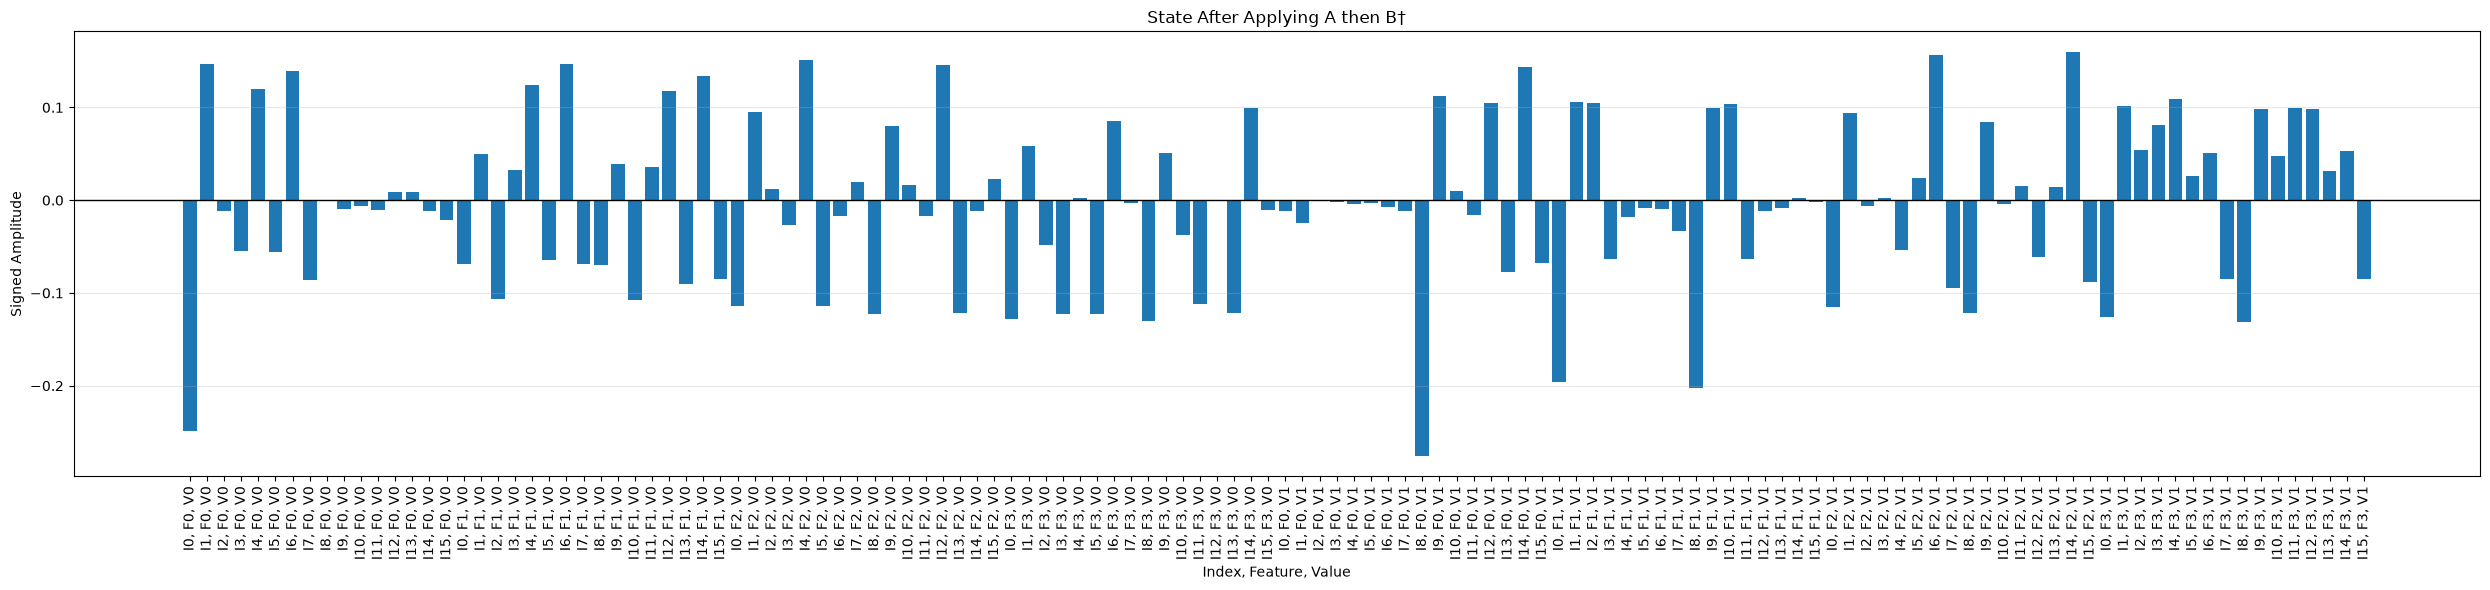


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


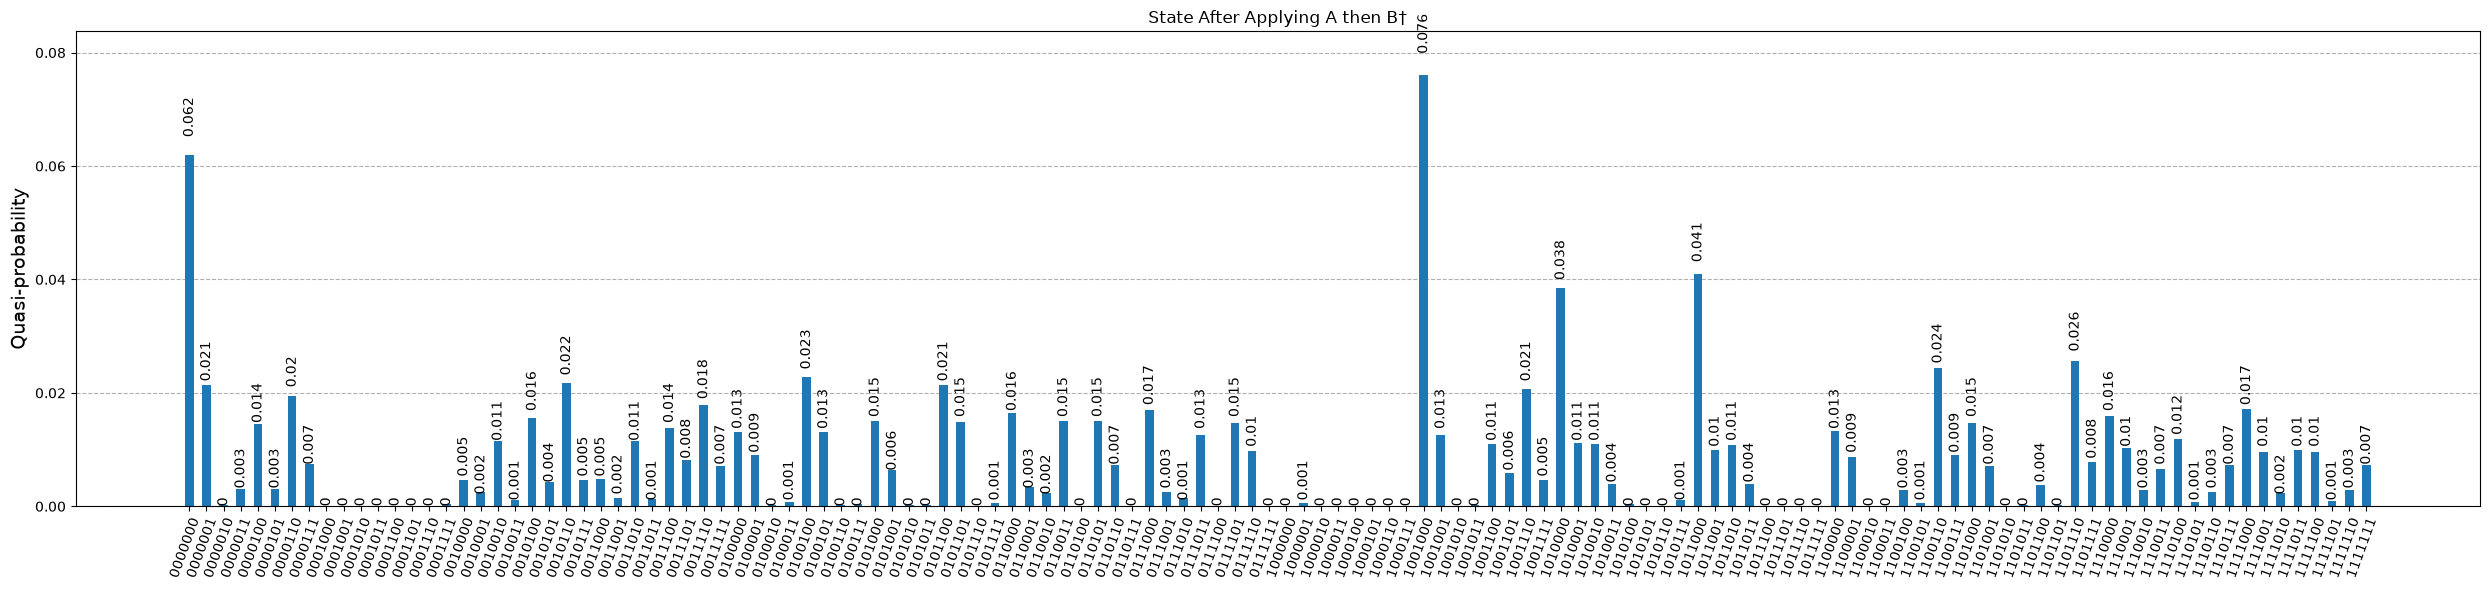

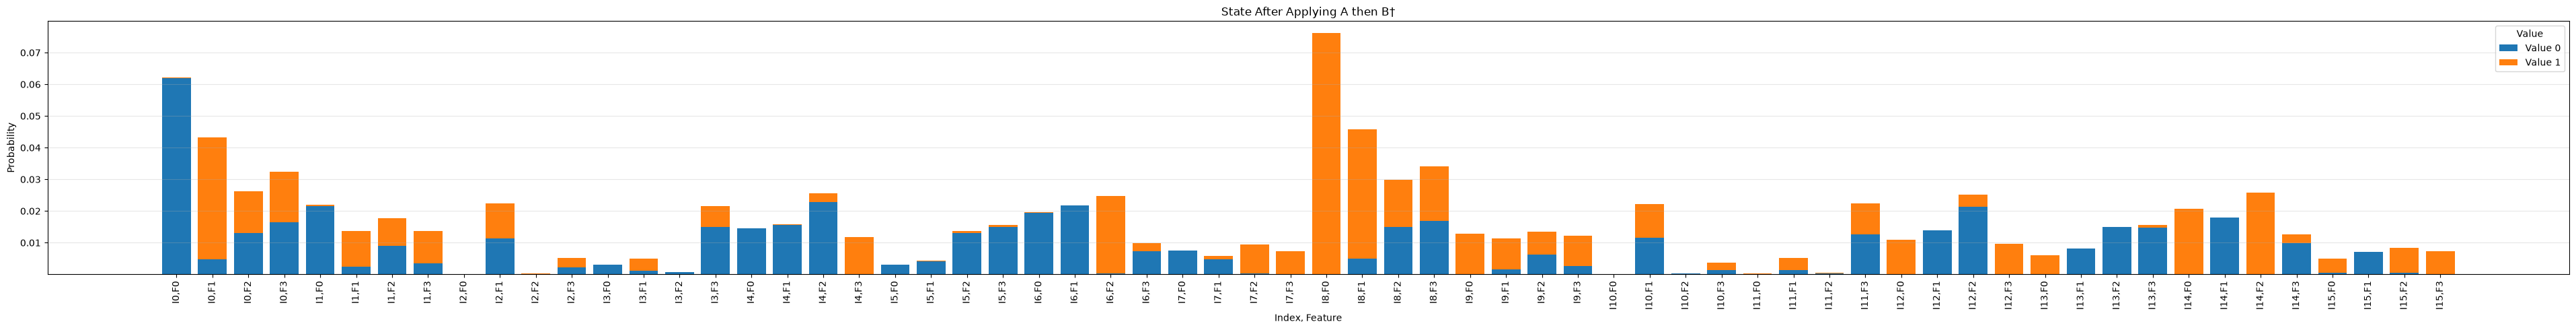


State After Applying A then B†
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.249                   -0.012                   
0                        1                        -0.069                   -0.196                   
0                        2                        -0.114                   -0.115                   
0                        3                        -0.128                   -0.126                   
1                        0                        +0.147                   -0.024                   
1                        1                        +0.050                   +0.106                   
1                        2                        +0.095                   +0.094                   
1                        3                        +0.059   

In [20]:
qc.compose(B.inverse(), qubits=range(n_feature_q + n_value_q), inplace=True)
qc.barrier()

state_after_B_inverse = Statevector.from_instruction(qc)

state_analysis(state_after_B_inverse, "State After Applying A then B†", n_value_q, n_feature_q, n_index_q)

For query index = 0
Total probability for index 0 =  (-0.250)^2+(+0.000)^2+(-0.249)^2+(-0.000)^2+(-0.125)^2+(-0.126)^2+(-0.124)^2+(-0.126)^2

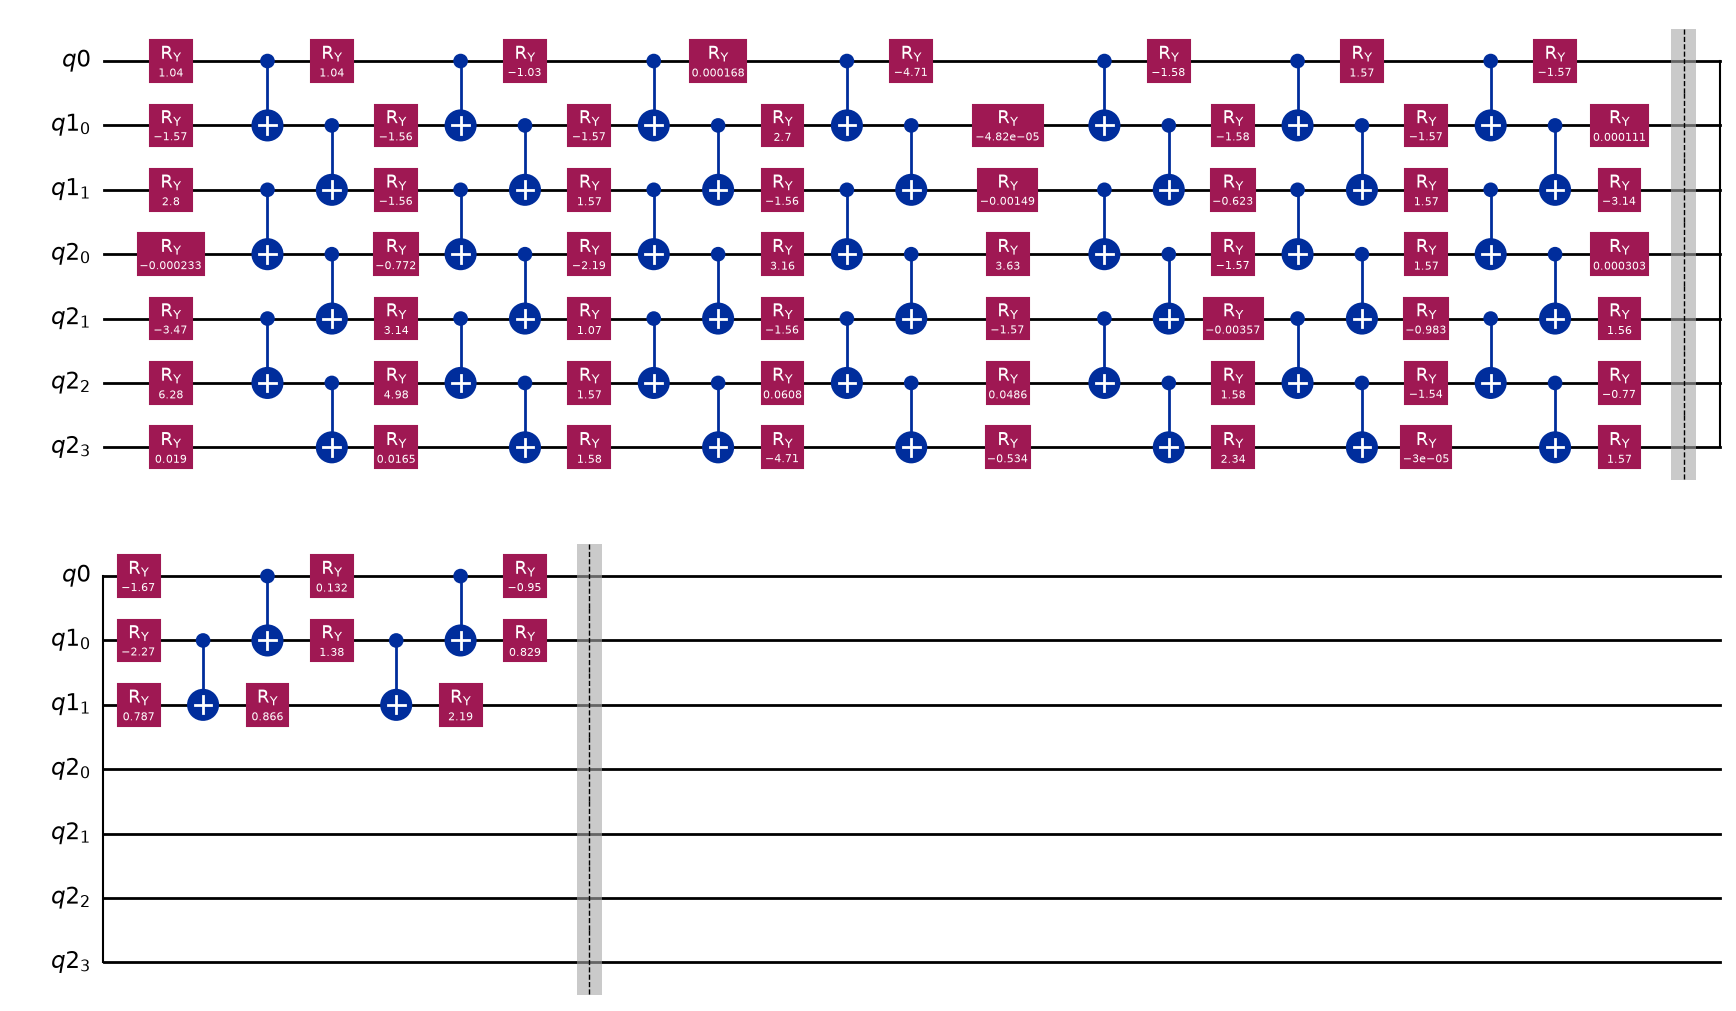

In [21]:
display(qc.draw("mpl"))

# <u>**Part 2: Use Grover Search for Image Matching**</u>

In [22]:
try:
    A_saved = load_parameters(scheme="NEQR", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved A. Fidelity = {A_saved_best_fidelity:.6f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset enocder. Train again.")

Loaded saved A. Fidelity = 0.985157


In [23]:
A_parameters

array([ 1.03786904e+00, -1.57089429e+00,  2.80475287e+00, -2.33217490e-04,
       -3.46996361e+00,  6.28232153e+00,  1.89674212e-02,  1.03792650e+00,
       -1.56094127e+00, -1.55843620e+00, -7.71850822e-01,  3.14010477e+00,
        4.98131869e+00,  1.65475799e-02, -1.03163522e+00, -1.57117041e+00,
        1.57081155e+00, -2.19161338e+00,  1.06915585e+00,  1.56605164e+00,
        1.57656020e+00,  1.68381524e-04,  2.70448480e+00, -1.56455855e+00,
        3.15887134e+00, -1.55985025e+00,  6.08248084e-02, -4.70776498e+00,
       -4.71284146e+00, -4.81568571e-05, -1.48665971e-03,  3.63082814e+00,
       -1.57256533e+00,  4.85558927e-02, -5.33833238e-01, -1.57894734e+00,
       -1.57795078e+00, -6.23465305e-01, -1.57429590e+00, -3.56523569e-03,
        1.57855378e+00,  2.34308182e+00,  1.57075334e+00, -1.57085388e+00,
        1.57139807e+00,  1.57080304e+00, -9.82754367e-01, -1.54064299e+00,
       -3.00450786e-05, -1.57078809e+00,  1.10881847e-04, -3.14106903e+00,
        3.03375805e-04,  

In [24]:
GS = GroverSearch()

## <u>**GS with NEQR scheme and MMD cost function**</u>

In [25]:
# GS.run(dataset=dataset, query=query,
#     A_parameters=A_parameters_neqr_mmd, B_parameters=B_parameters_neqr_mmd,
#     depth_A=6, depth_B=3,
#     num_of_iter=5
# )

In [26]:
query_index

11

In [27]:
# GS.draw_circuit()

In [28]:
# GS.analysis()

## <u>**GS with NEQR scheme and FIDELITY cost function**</u>

Number of data elements =  16
Number of features =  4
Index qubits =  4
Data qubits =  2
Value qubits =  1
Total no of qubits =  7
Range of value qubits =  [0]
Range of feature qubits =  [1, 2]
Range of index qubits =  [3, 4, 5, 6]

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.2490706537337294+0j)
|0000001> : (0.1465396108446532+0j)
|0000010> : (-0.012166684024866651+0j)
|0000011> : (-0.05458297198724071+0j)
|0000100> : (0.12037629131105862+0j)
|0000101> : (-0.05542569834453469+0j)
|0000110> : (0.13964914535283013+0j)
|0000111> : (-0.08618197339608578+0j)
|0001000> : (-0.0011280099217012881+0j)
|0001001> : (-0.009821963724167802+0j)
|0001010> : (-0.006399044985134357+0j)
|0001011> : (-0.010051202364162846+0j)
|0001100> : (0.008377351304609945+0j)
|0001101> : (0.008922462243726736+0j)
|0001110> : (-0.011802592602937381+0j)
|0001111> : (-0.02125157604549425+0j)
|0010000> : (-0.06865389829643267+0j)
|0010001> : (0.04957144800736877+0j)
|0010010> : (-0.10699977623128042+0j)
|0010011> : (0.03275417040712293+0j)
|0010100> : (0.12456592814688379+0j)
|0010101> : (-0.0648675576659945+0j)
|0010110> : (0.14728085389725476+0j)
|0010111> : (-0.06864056460796616+0j)
|0011000> : (-0.06985052046622074+0j)
|0011001> : (0.03887669

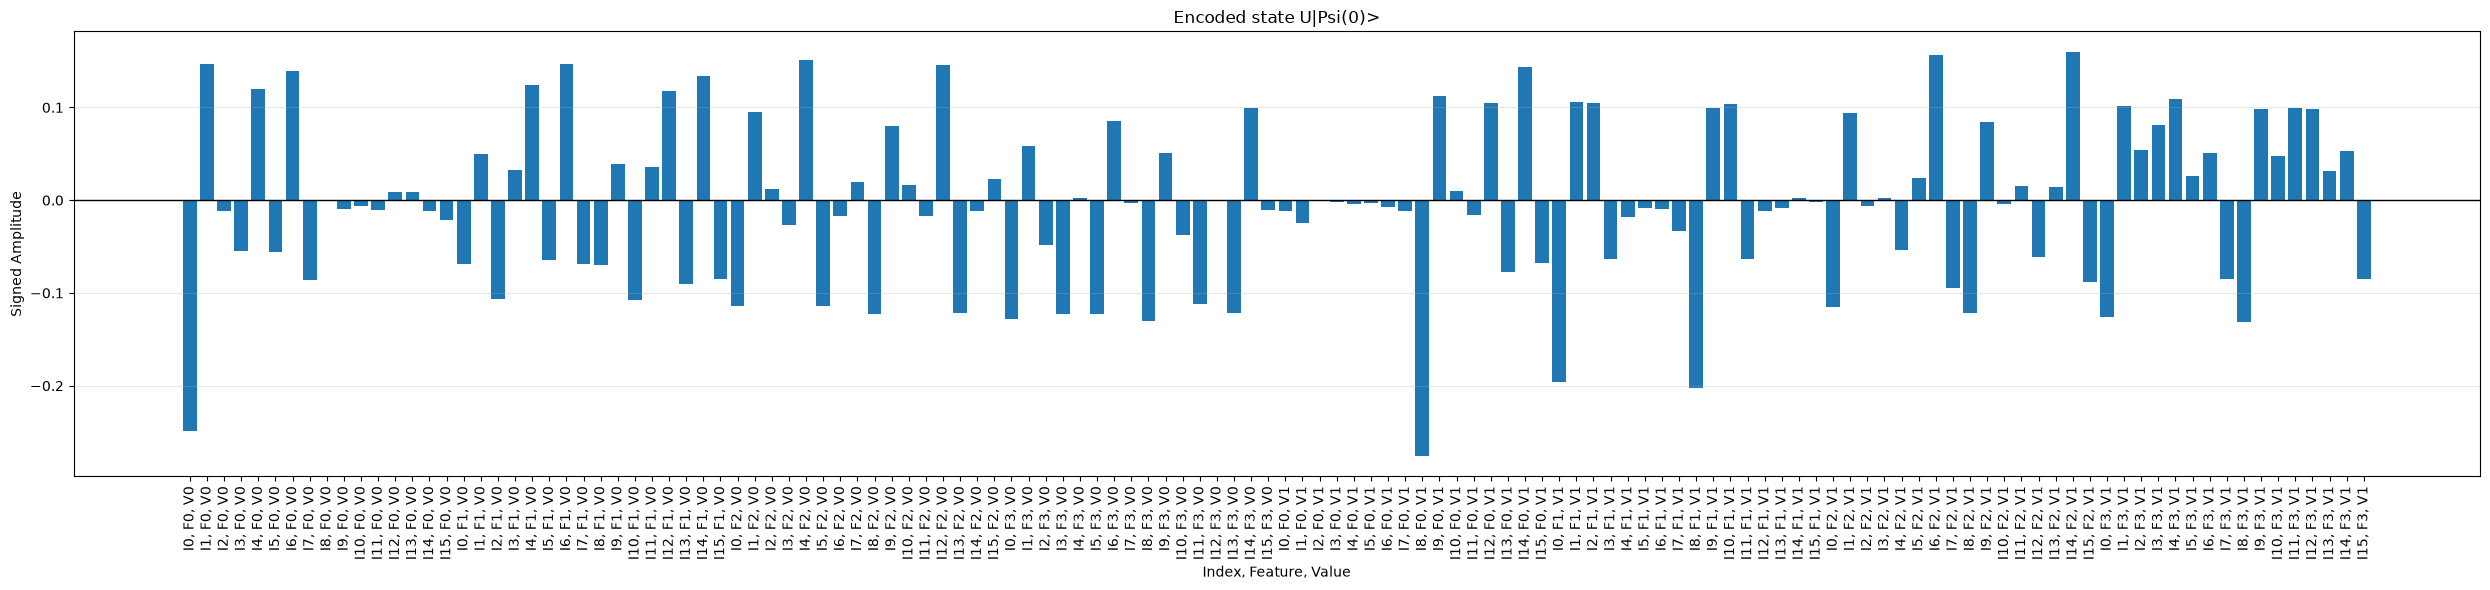


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


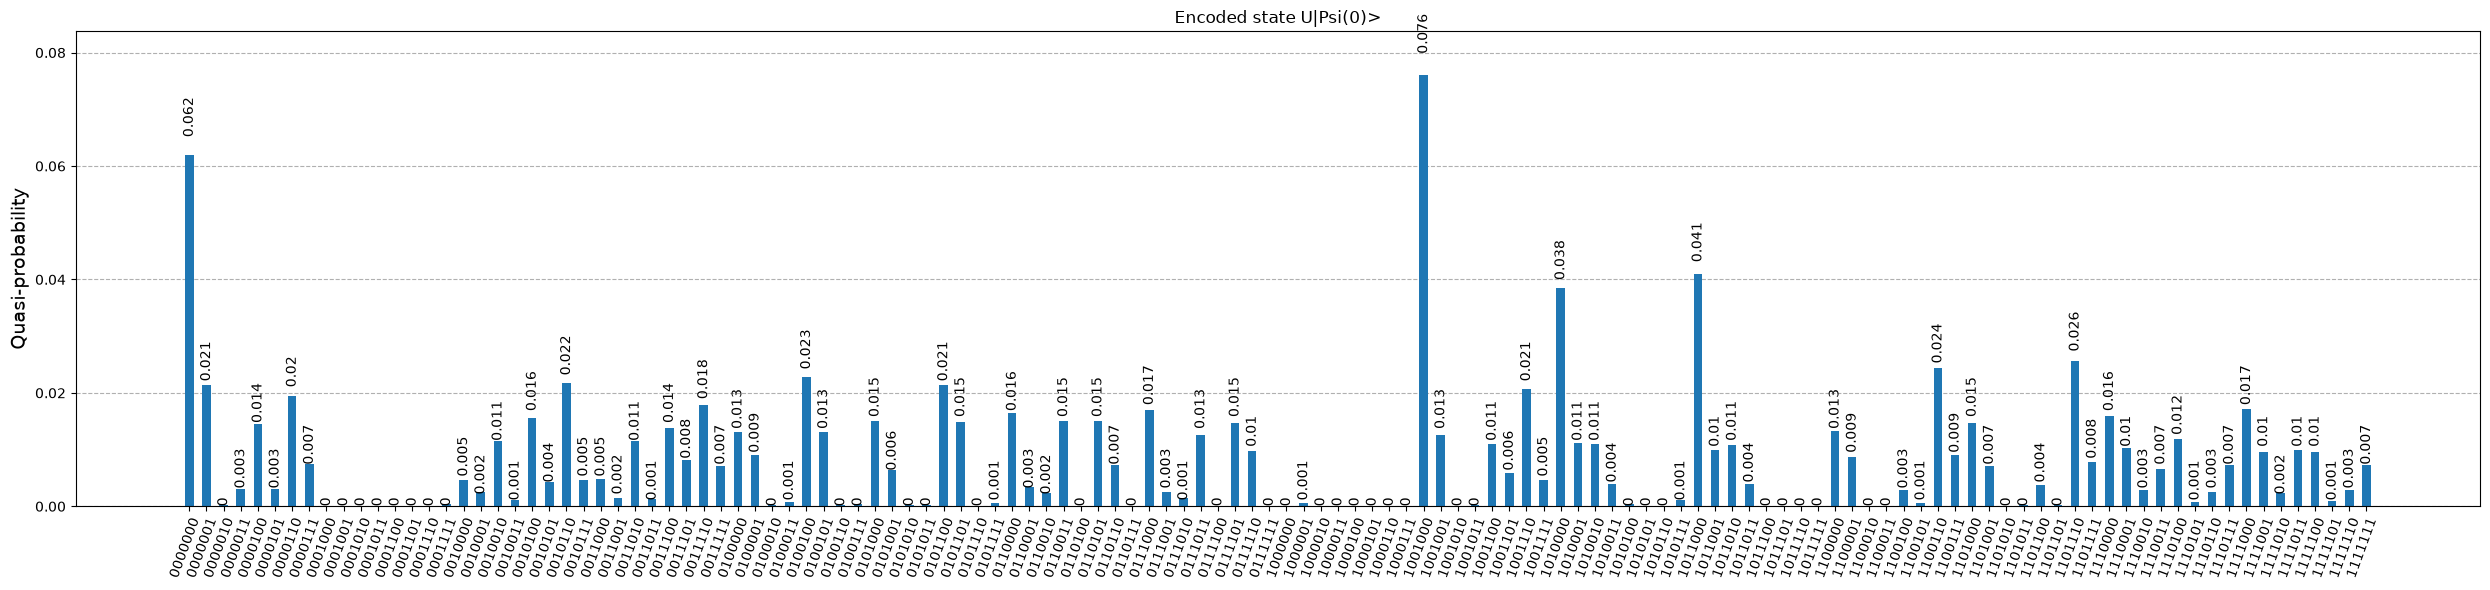

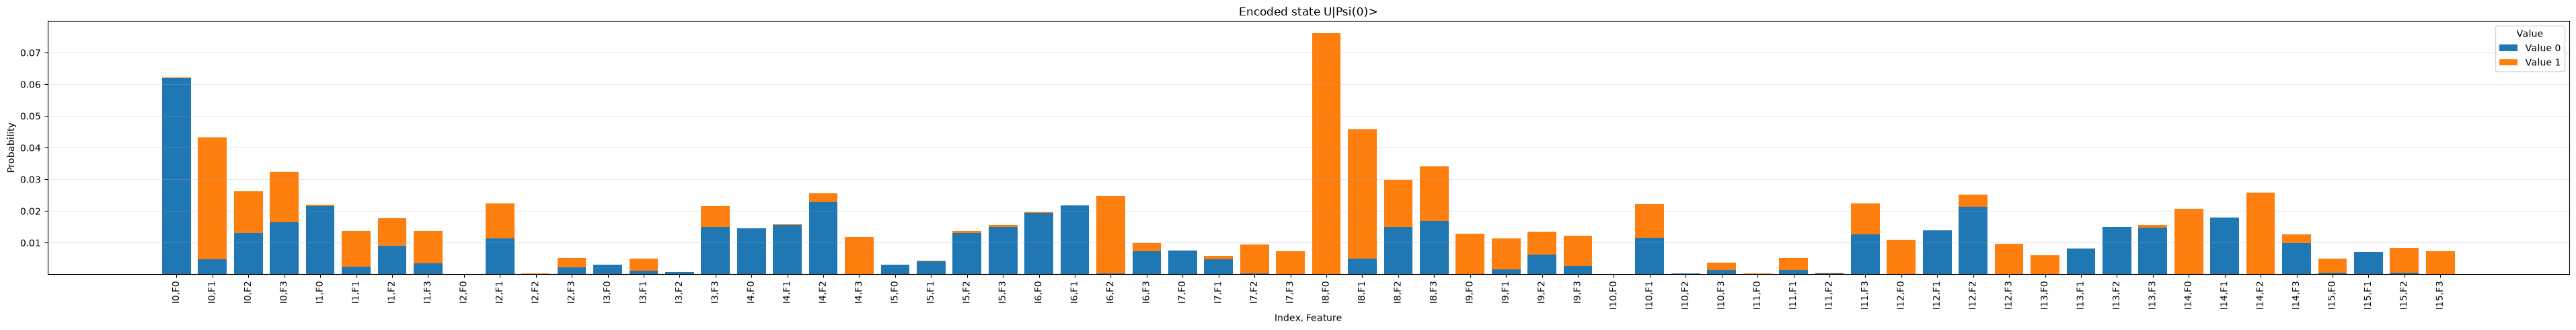


Encoded state U|Psi(0)>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.249                   -0.012                   
0                        1                        -0.069                   -0.196                   
0                        2                        -0.114                   -0.115                   
0                        3                        -0.128                   -0.126                   
1                        0                        +0.147                   -0.024                   
1                        1                        +0.050                   +0.106                   
1                        2                        +0.095                   +0.094                   
1                        3                        +0.059          

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.24907065373372933+0j)
|0000001> : (0.14653961084465317+0j)
|0000010> : (-0.012166684024866647+0j)
|0000011> : (-0.05458297198724069+0j)
|0000100> : (0.12037629131105858+0j)
|0000101> : (-0.055425698344534674+0j)
|0000110> : (0.1396491453528301+0j)
|0000111> : (-0.08618197339608577+0j)
|0001000> : (0.0011280099217012886+0j)
|0001001> : (-0.0098219637241678+0j)
|0001010> : (-0.006399044985134356+0j)
|0001011> : (-0.010051202364162844+0j)
|0001100> : (0.008377351304609943+0j)
|0001101> : (0.008922462243726734+0j)
|0001110> : (-0.011802592602937378+0j)
|0001111> : (-0.021251576045494245+0j)
|0010000> : (0.06865389829643266+0j)
|0010001> : (0.049571448007368756+0j)
|0010010> : (-0.1069997762312804+0j)
|0010011> : (0.032754170407122925+0j)
|0010100> : (0.12456592814688379+0j)
|0010101> : (-0.06486755766599449+0j)
|0010110> : (0.14728085389725473+0j)
|0010111> : (-0.06864056460796615+0j)
|0011000> : (0.06985052046622073+0j)
|0011001> : (0.038876694

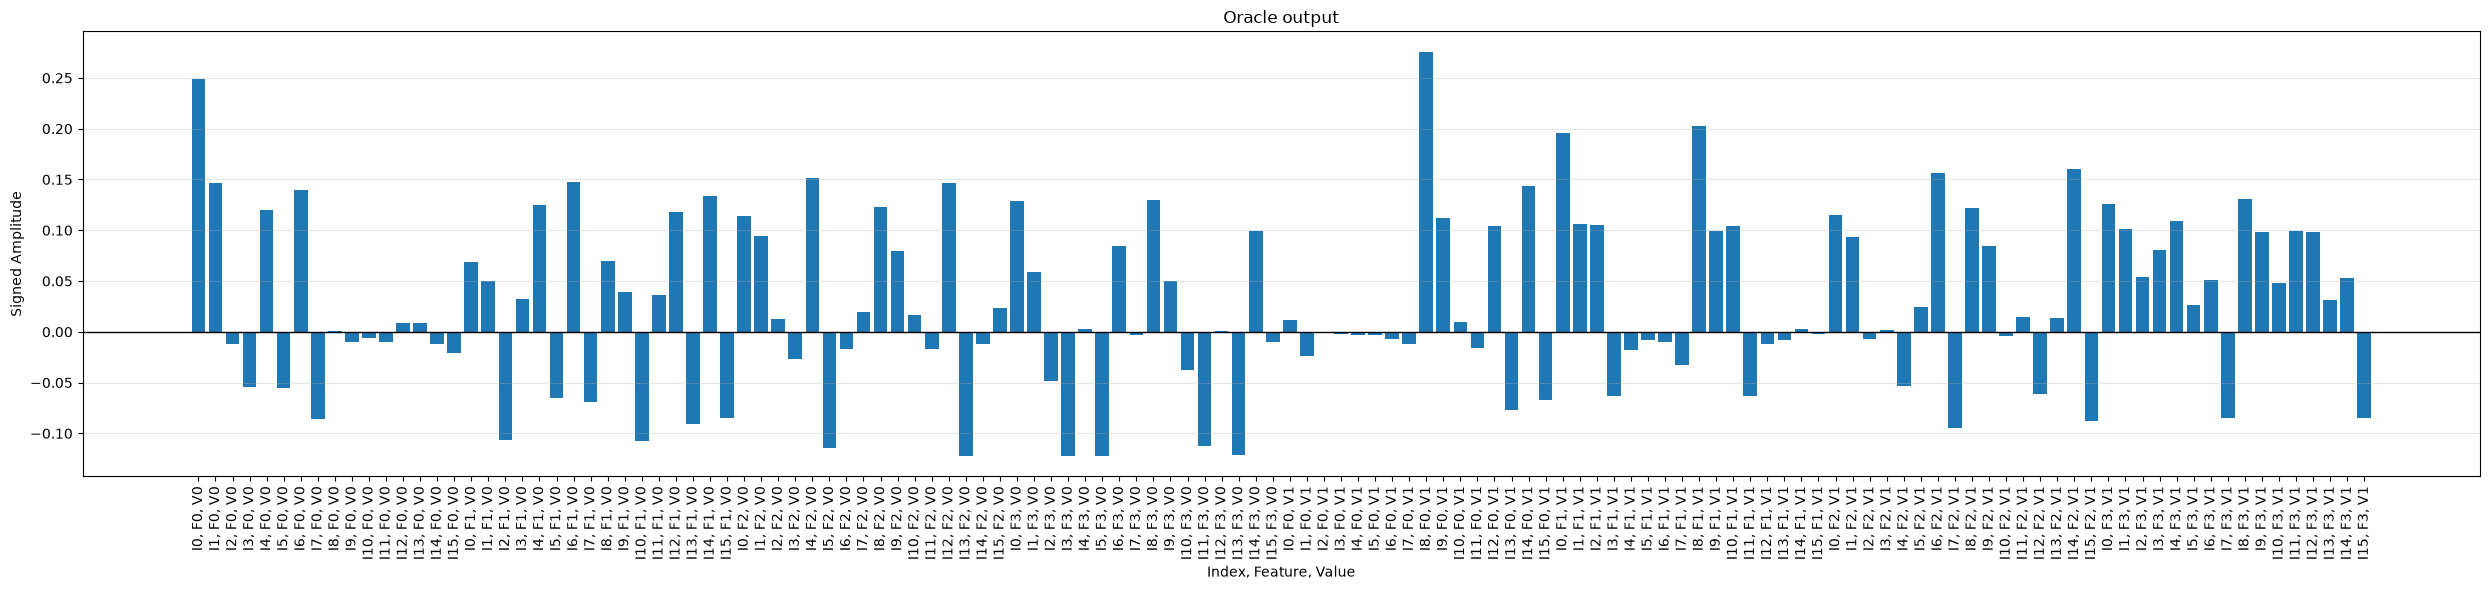


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


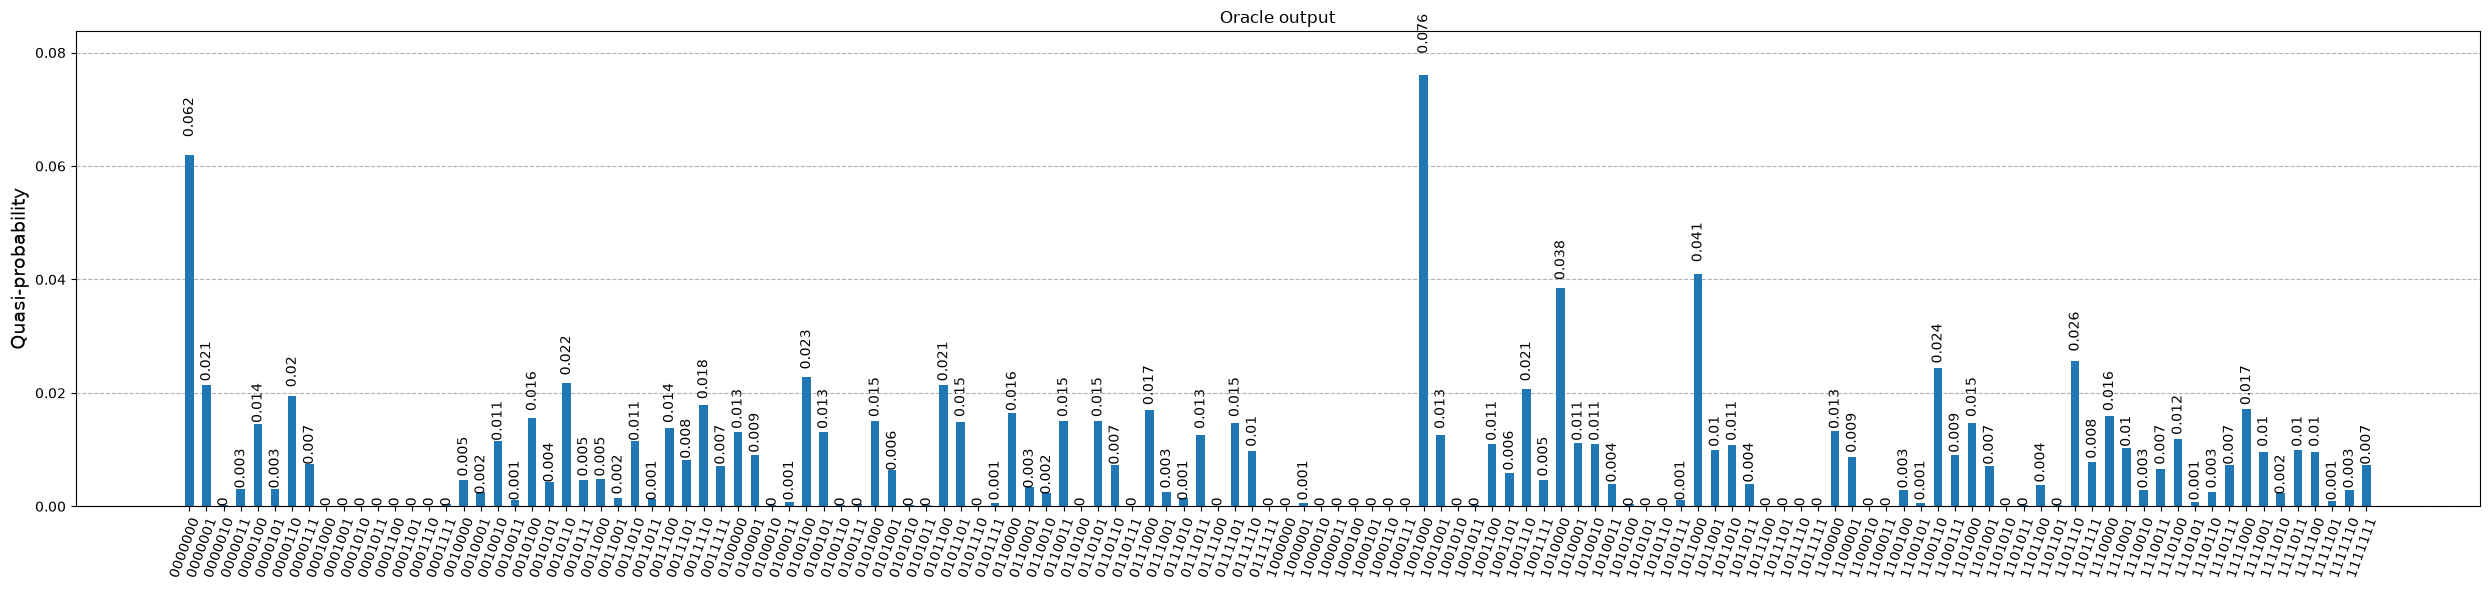

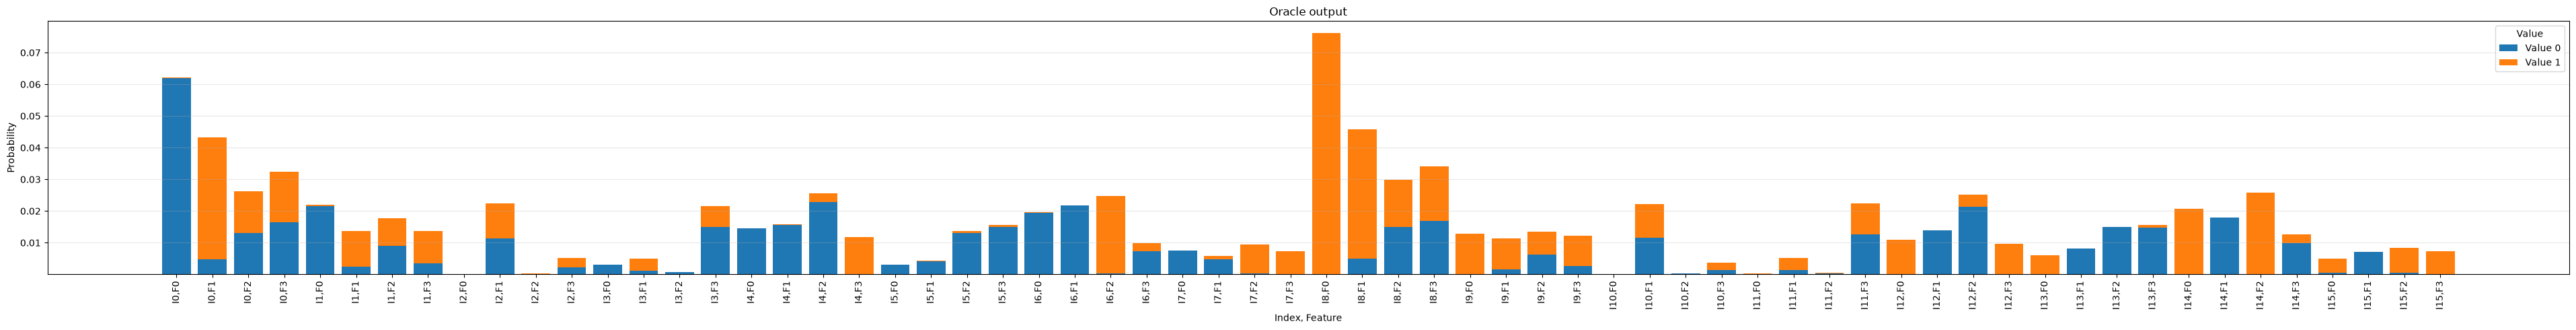


Oracle output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.249                   +0.012                   
0                        1                        +0.069                   +0.196                   
0                        2                        +0.114                   +0.115                   
0                        3                        +0.128                   +0.126                   
1                        0                        +0.147                   -0.024                   
1                        1                        +0.050                   +0.106                   
1                        2                        +0.095                   +0.094                   
1                        3                        +0.059                   +

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.39853246572952694+5.636152557810698e-17j)
|0000001> : (0.05860441881108721+3.649579595189171e-17j)
|0000010> : (-0.004865724987432465-1.774354485987627e-17j)
|0000011> : (-0.021828933022656403-3.204323948620146e-17j)
|0000100> : (0.048141130921913494+1.586249481161823e-17j)
|0000101> : (-0.022165957859158623+6.658290505904465e-17j)
|0000110> : (0.05584876985611473-1.7462818187435064e-17j)
|0000111> : (-0.03446606984799761+3.203019154102521e-17j)
|0001000> : (0.0018049038243724016+5.941733860387097e-17j)
|0001001> : (-0.003928019682327484-7.310469354941138e-18j)
|0001010> : (-0.0025591190677949384-2.7649887209713413e-17j)
|0001011> : (-0.004019697264849728+2.3956465026250986e-17j)
|0001100> : (0.0033502873492916394+1.1885228143494362e-17j)
|0001101> : (0.003568289223258634-8.620712790283273e-18j)
|0001110> : (-0.004720116806454761-1.5727384980982016e-17j)
|0001111> : (-0.00849897345698642-2.597612760283244e-18j)
|0010000> : (0.109851590140650

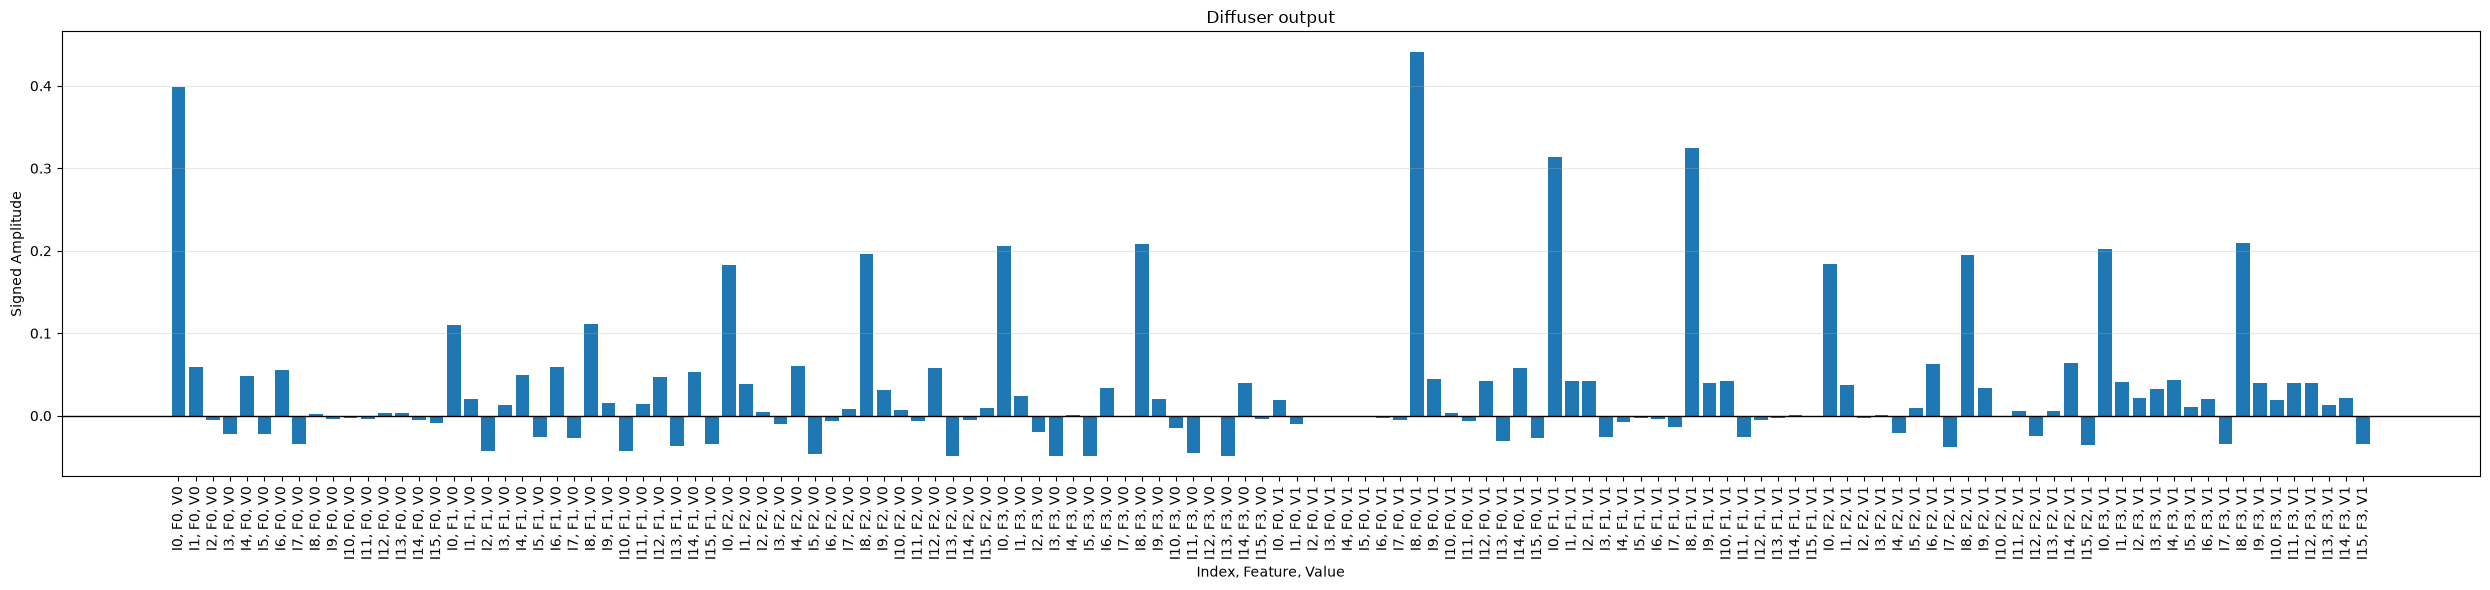


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


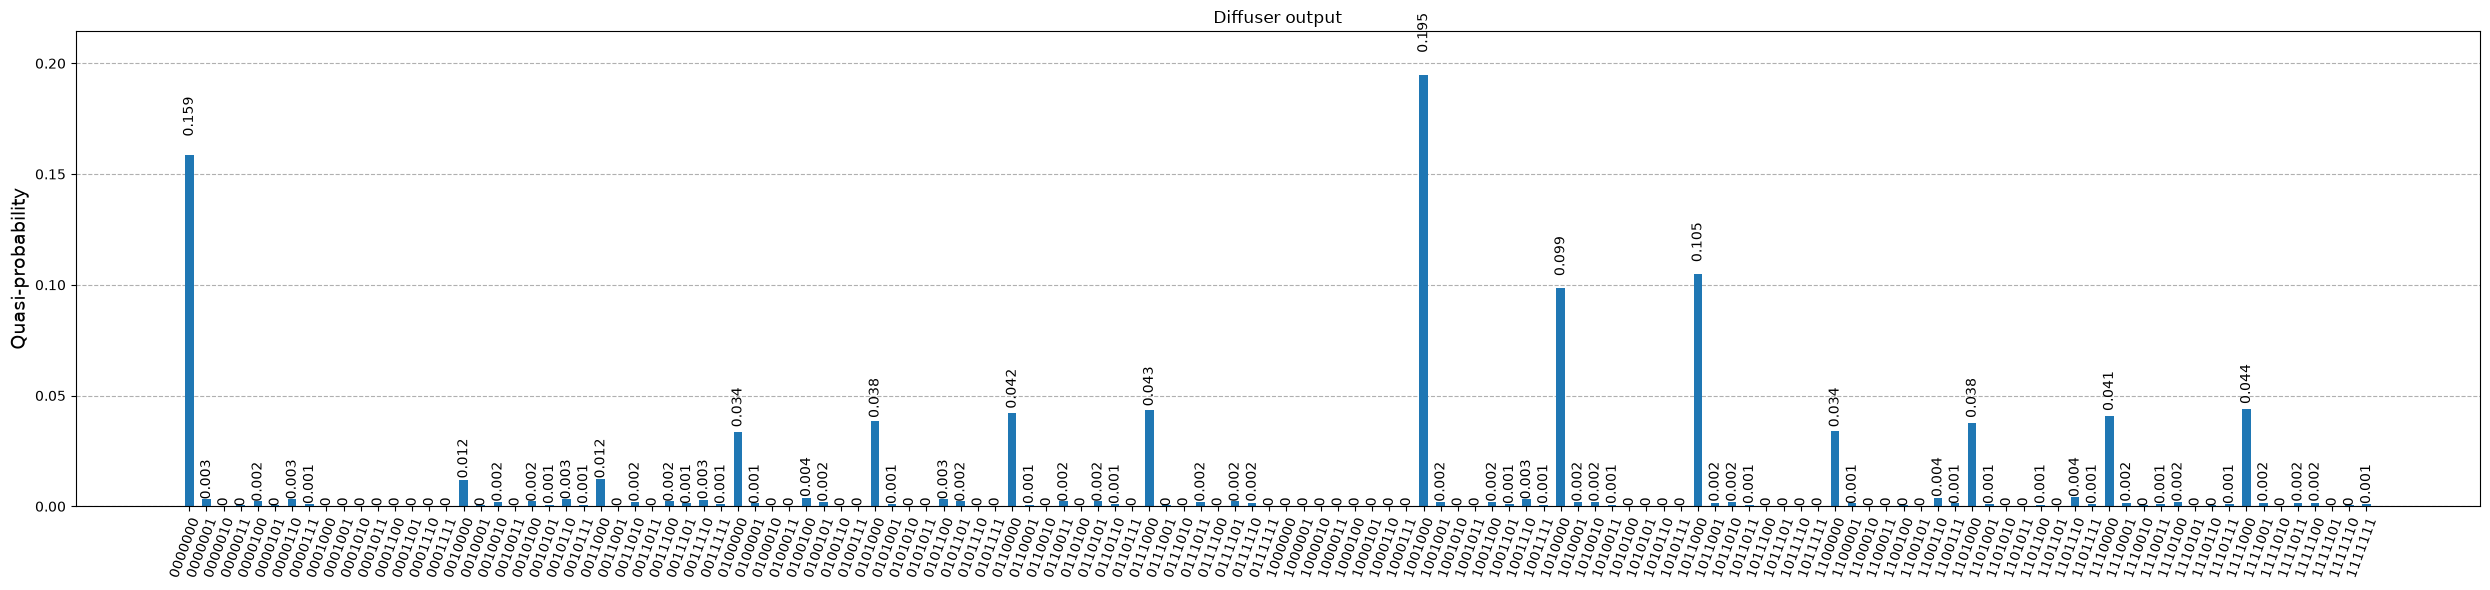

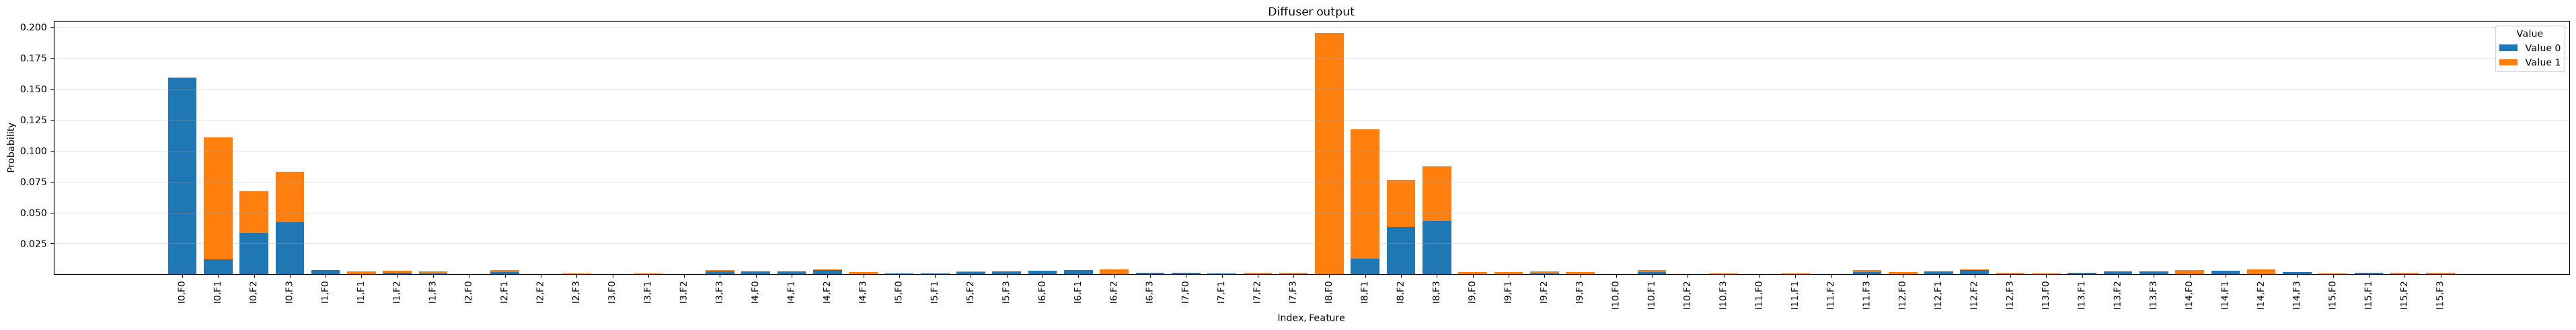


Diffuser output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.399                   +0.019                   
0                        1                        +0.110                   +0.314                   
0                        2                        +0.183                   +0.184                   
0                        3                        +0.205                   +0.202                   
1                        0                        +0.059                   -0.010                   
1                        1                        +0.020                   +0.042                   
1                        2                        +0.038                   +0.037                   
1                        3                        +0.023                  

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.3985324657295269-5.636152557810697e-17j)
|0000001> : (0.0586044188110872+3.64957959518917e-17j)
|0000010> : (-0.004865724987432464-1.7743544859876267e-17j)
|0000011> : (-0.0218289330226564-3.204323948620145e-17j)
|0000100> : (0.04814113092191349+1.586249481161823e-17j)
|0000101> : (-0.022165957859158616+6.658290505904463e-17j)
|0000110> : (0.05584876985611472-1.7462818187435058e-17j)
|0000111> : (-0.03446606984799761+3.2030191541025206e-17j)
|0001000> : (-0.0018049038243724014-5.941733860387096e-17j)
|0001001> : (-0.003928019682327483-7.310469354941137e-18j)
|0001010> : (-0.002559119067794938-2.7649887209713407e-17j)
|0001011> : (-0.004019697264849727+2.3956465026250983e-17j)
|0001100> : (0.003350287349291639+1.1885228143494362e-17j)
|0001101> : (0.003568289223258633-8.620712790283272e-18j)
|0001110> : (-0.0047201168064547605-1.572738498098201e-17j)
|0001111> : (-0.008498973456986417-2.597612760283243e-18j)
|0010000> : (-0.10985159014065032

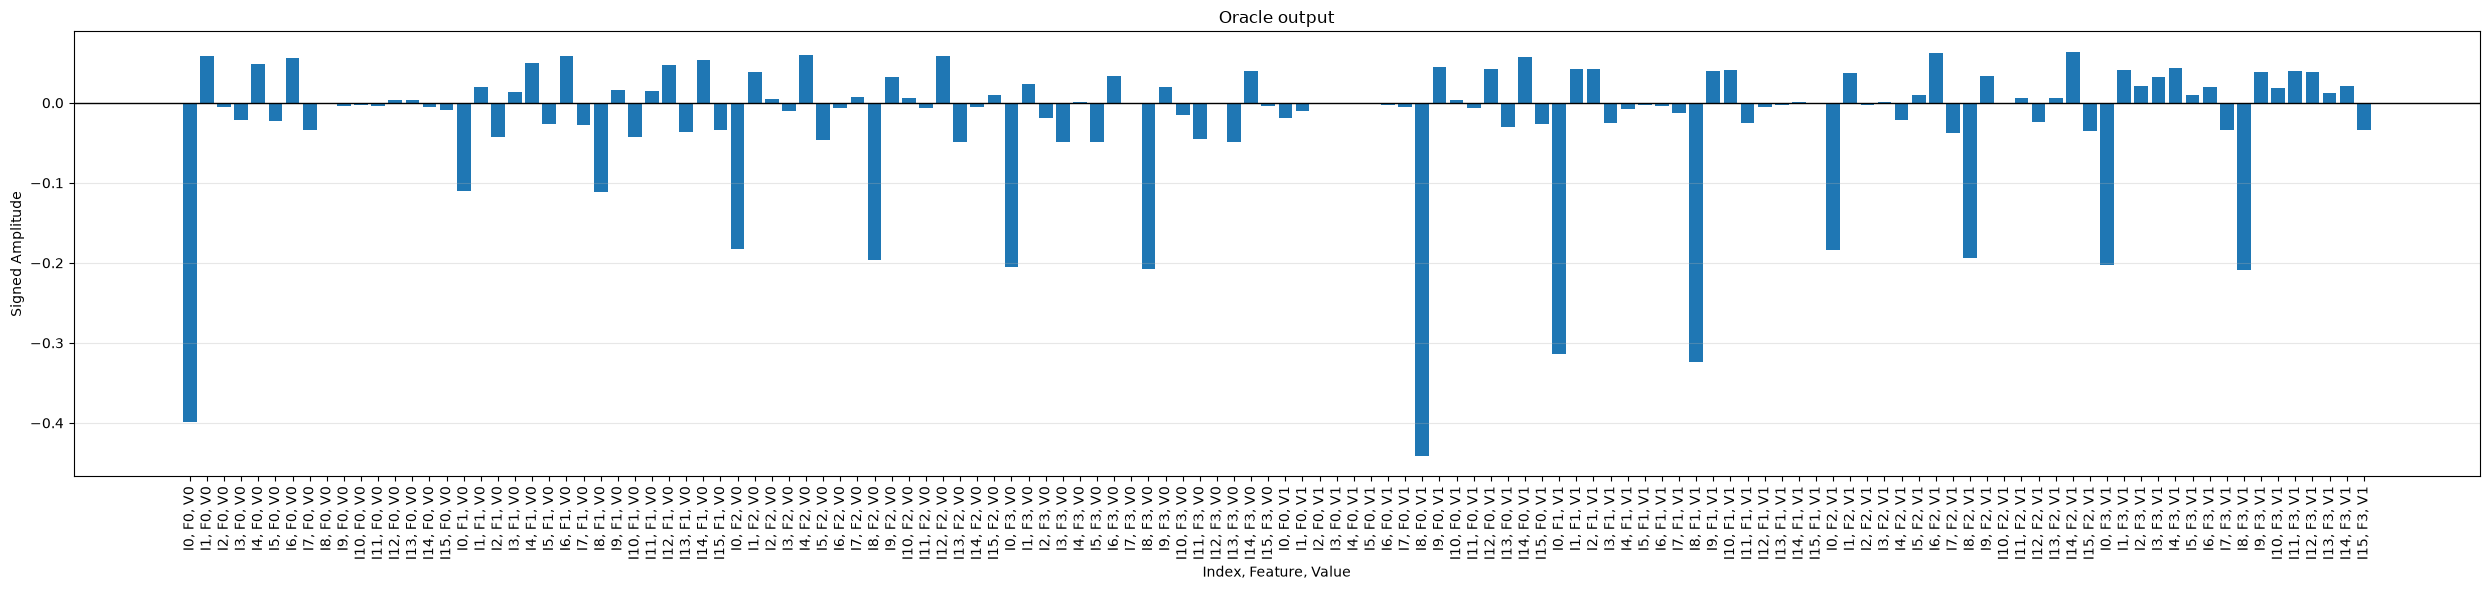


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


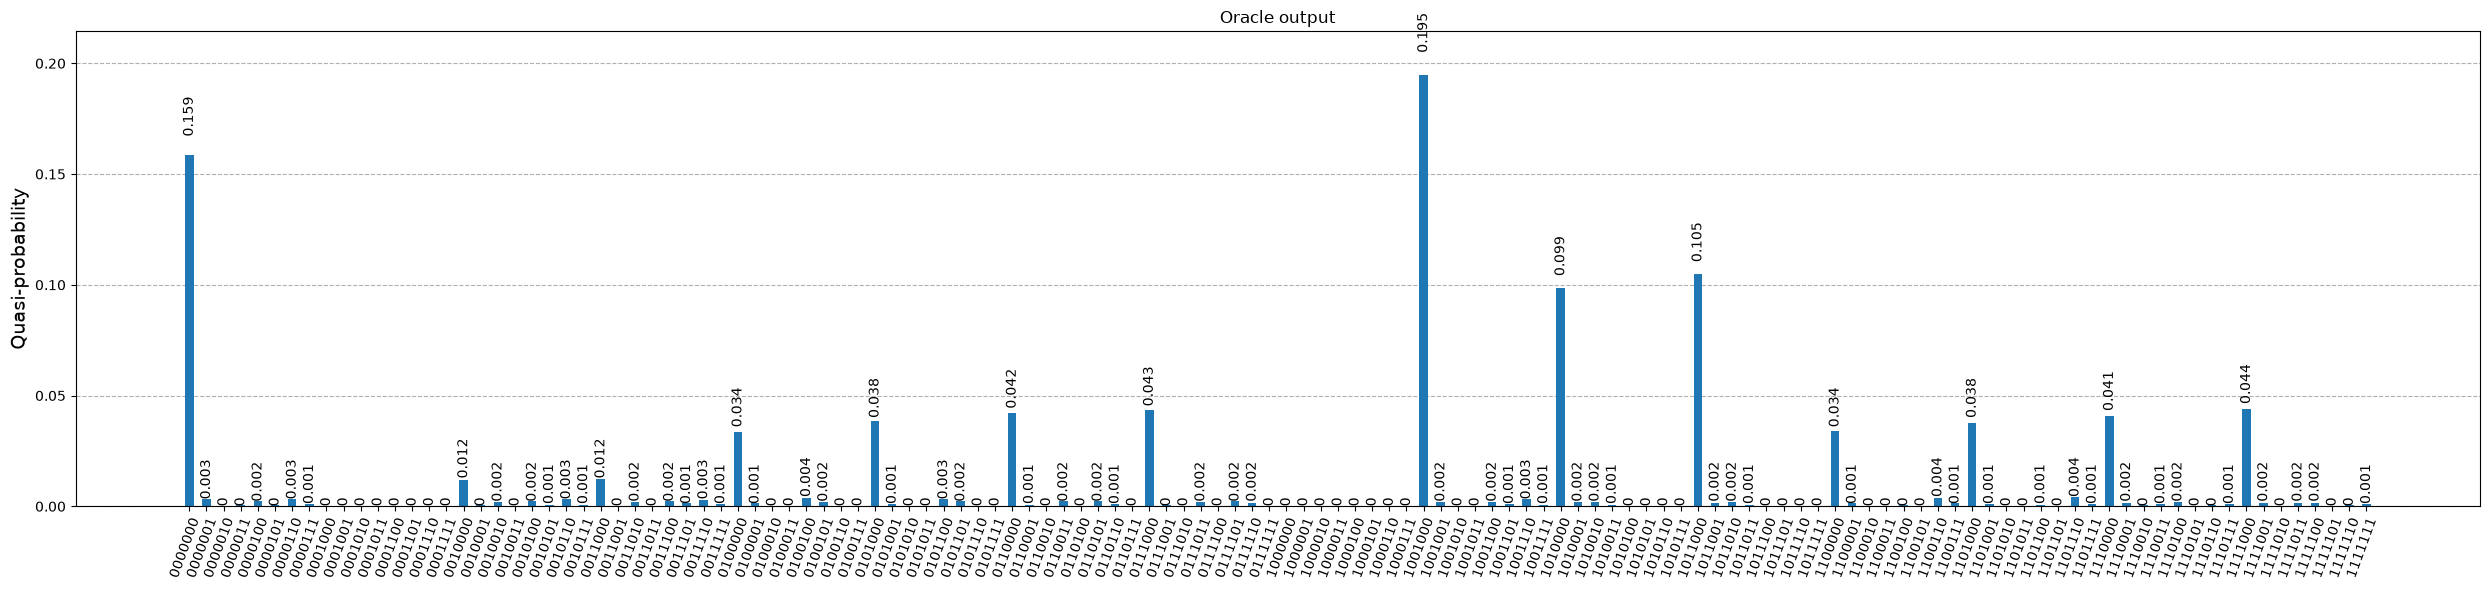

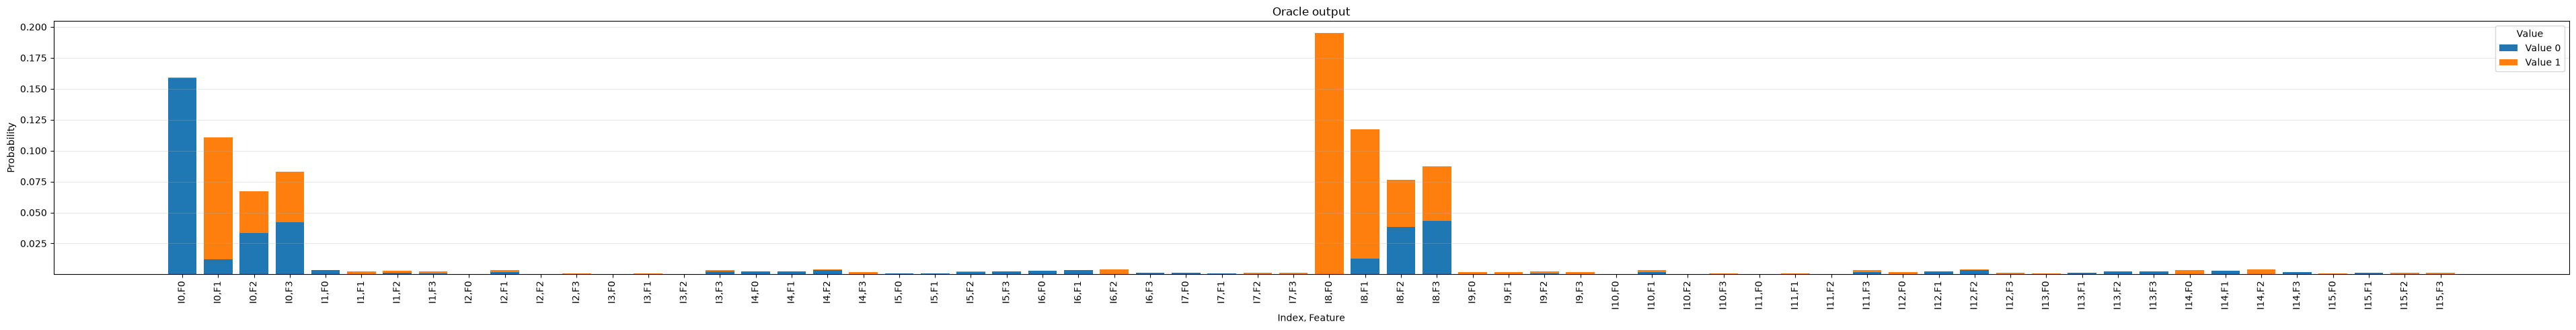


Oracle output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.399                   -0.019                   
0                        1                        -0.110                   -0.314                   
0                        2                        -0.183                   -0.184                   
0                        3                        -0.205                   -0.202                   
1                        0                        +0.059                   -0.010                   
1                        1                        +0.020                   +0.042                   
1                        2                        +0.038                   +0.037                   
1                        3                        +0.023                   +

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.009920101172975876+1.2709938999569415e-16j)
|0000001> : (-0.18170683145117766-5.651497454352895e-17j)
|0000010> : (0.015086498392368362+8.211708718300032e-18j)
|0000011> : (0.06768203377791206+1.8699783576465382e-17j)
|0000100> : (-0.14926472337342409-3.45799873093439e-17j)
|0000101> : (0.06872700131455022+9.897519421964582e-17j)
|0000110> : (-0.17316276173155637-9.992082089839862e-17j)
|0000111> : (0.1068643025851449+9.979682911982735e-17j)
|0001000> : (4.492690077972616e-05-3.4224241908313897e-17j)
|0001001> : (0.01217908179679114+3.525295647049258e-17j)
|0001010> : (0.007934715957413959-1.8931874198416043e-17j)
|0001011> : (0.012463334134295909+5.4331663101100075e-17j)
|0001100> : (-0.010387784932278736-3.124547109273054e-19j)
|0001101> : (-0.011063713993133564-2.150589440597105e-17j)
|0001110> : (0.014635030708948397-3.6227178894980686e-17j)
|0001111> : (0.02635162277497884+1.5265143404348446e-17j)
|0010000> : (0.002734379208510981+1.049

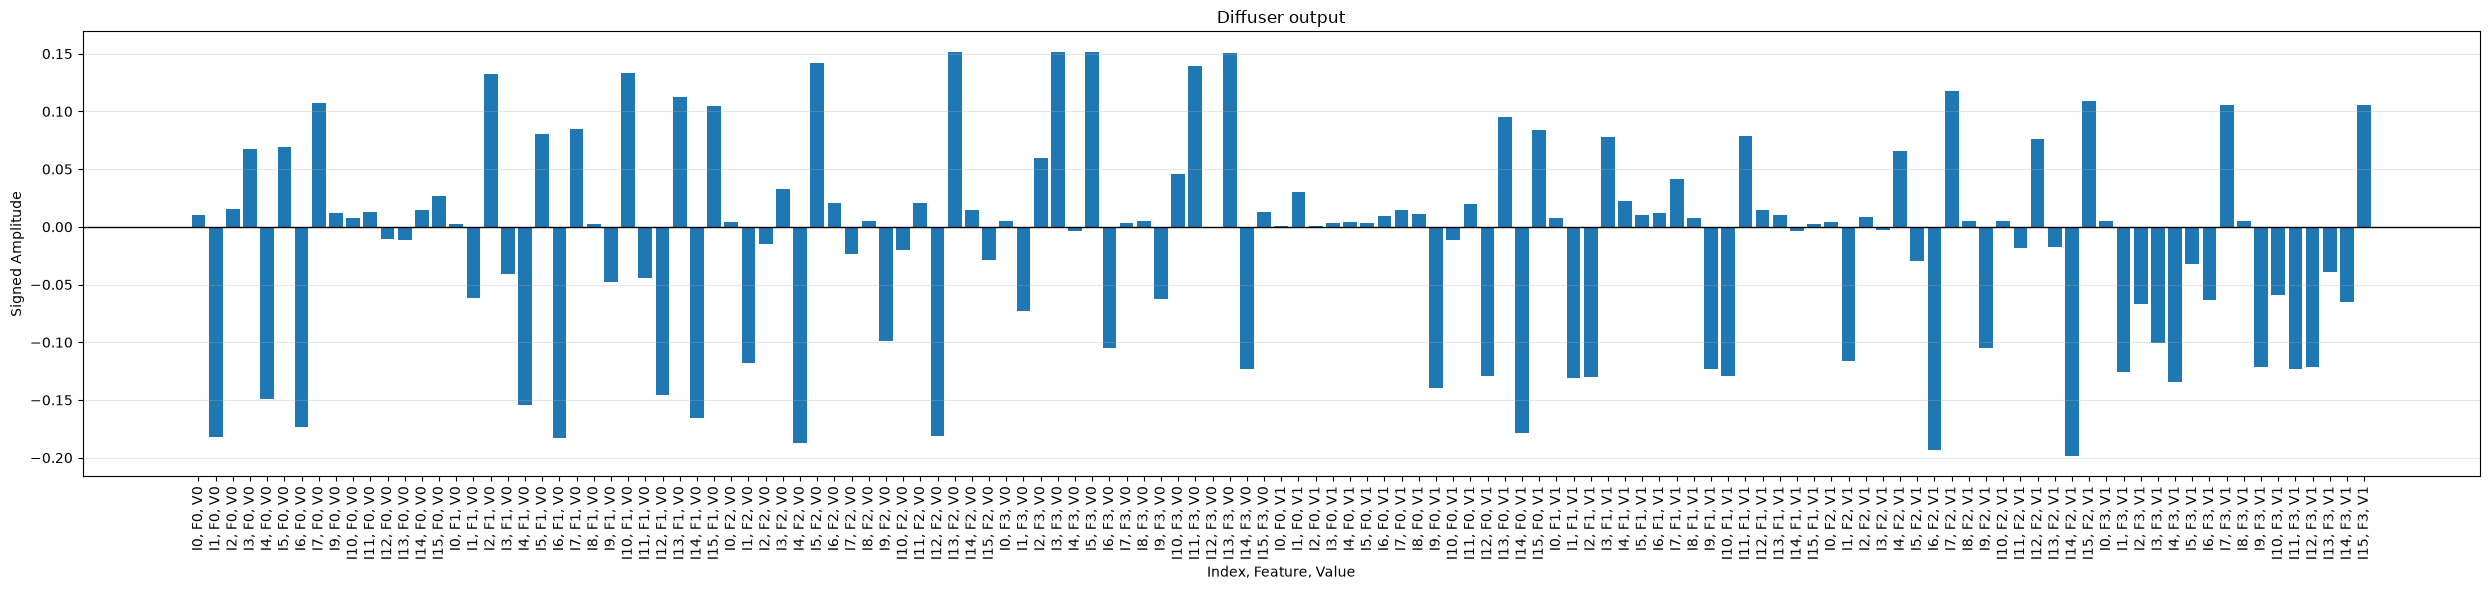


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


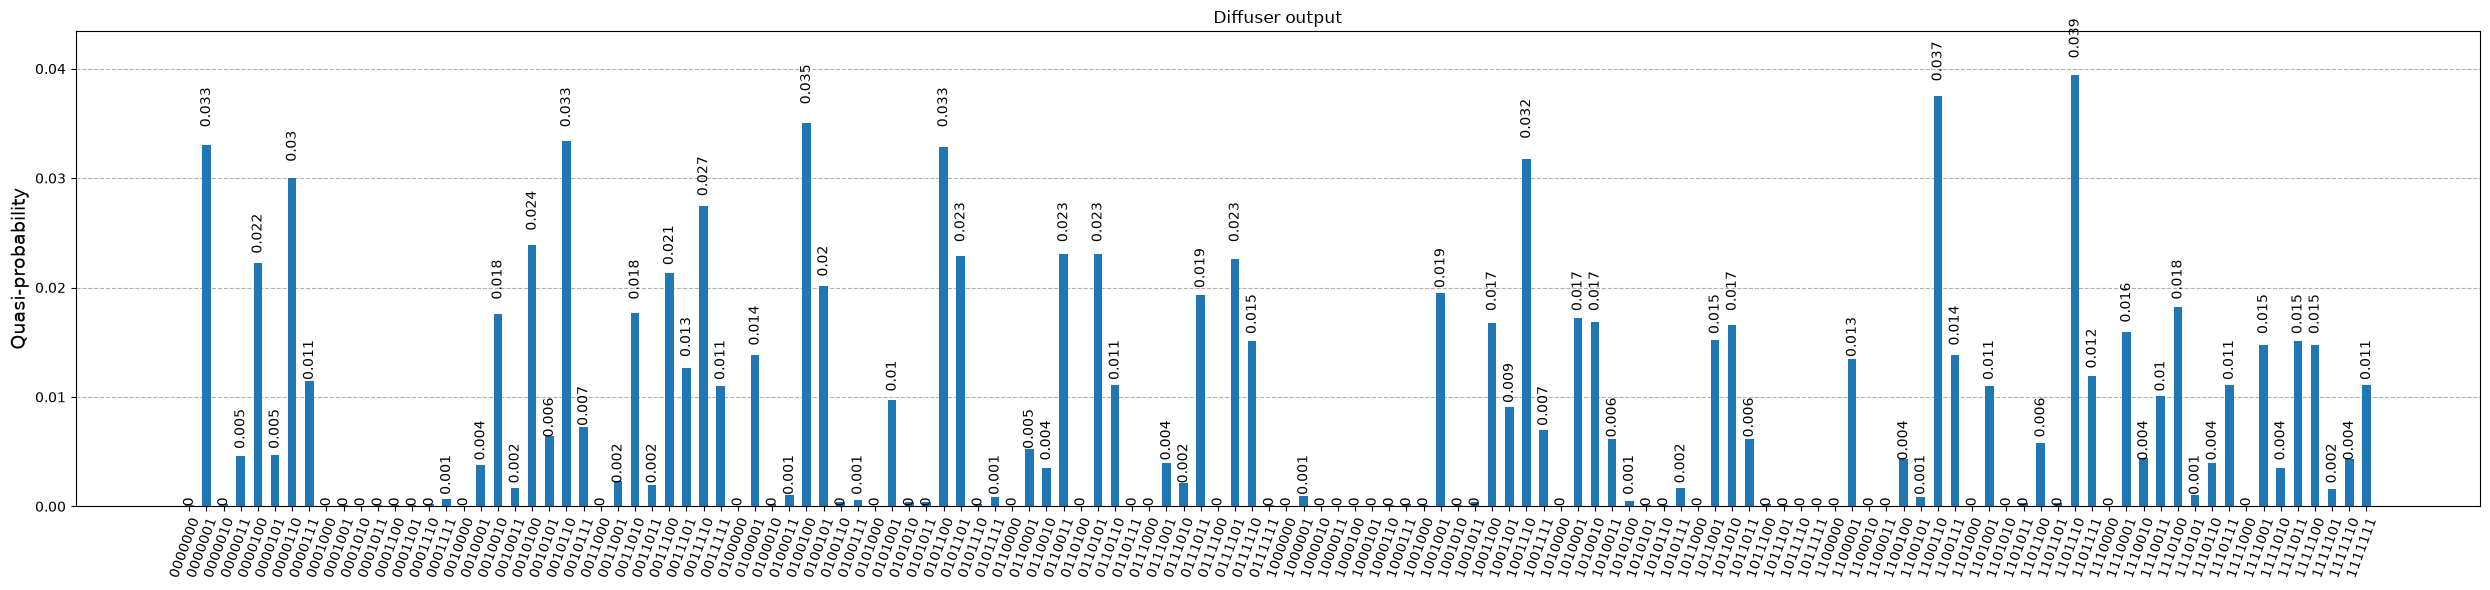

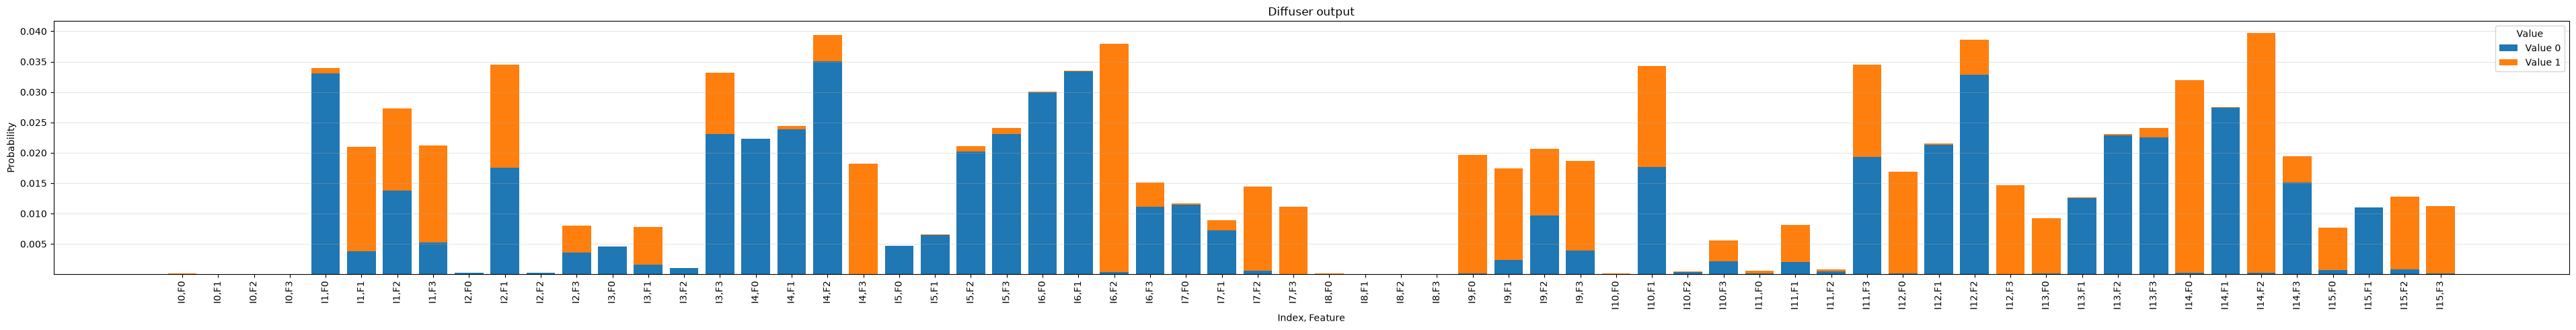


Diffuser output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.010                   +0.000                   
0                        1                        +0.003                   +0.008                   
0                        2                        +0.005                   +0.005                   
0                        3                        +0.005                   +0.005                   
1                        0                        -0.182                   +0.030                   
1                        1                        -0.061                   -0.131                   
1                        2                        -0.118                   -0.116                   
1                        3                        -0.073                  

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.00992010117297587-1.2709938999569412e-16j)
|0000001> : (-0.18170683145117764-5.651497454352894e-17j)
|0000010> : (0.015086498392368365+8.211708718300034e-18j)
|0000011> : (0.06768203377791204+1.8699783576465382e-17j)
|0000100> : (-0.14926472337342406-3.4579987309343895e-17j)
|0000101> : (0.06872700131455022+9.897519421964581e-17j)
|0000110> : (-0.17316276173155634-9.992082089839861e-17j)
|0000111> : (0.10686430258514487+9.979682911982734e-17j)
|0001000> : (-4.4926900779726725e-05+3.422424190831389e-17j)
|0001001> : (0.012179081796791138+3.5252956470492574e-17j)
|0001010> : (0.007934715957413957-1.893187419841604e-17j)
|0001011> : (0.012463334134295907+5.433166310110006e-17j)
|0001100> : (-0.010387784932278734-3.1245471092730665e-19j)
|0001101> : (-0.011063713993133563-2.1505894405971046e-17j)
|0001110> : (0.014635030708948395-3.622717889498068e-17j)
|0001111> : (0.026351622774978836+1.526514340434844e-17j)
|0010000> : (-0.002734379208510972

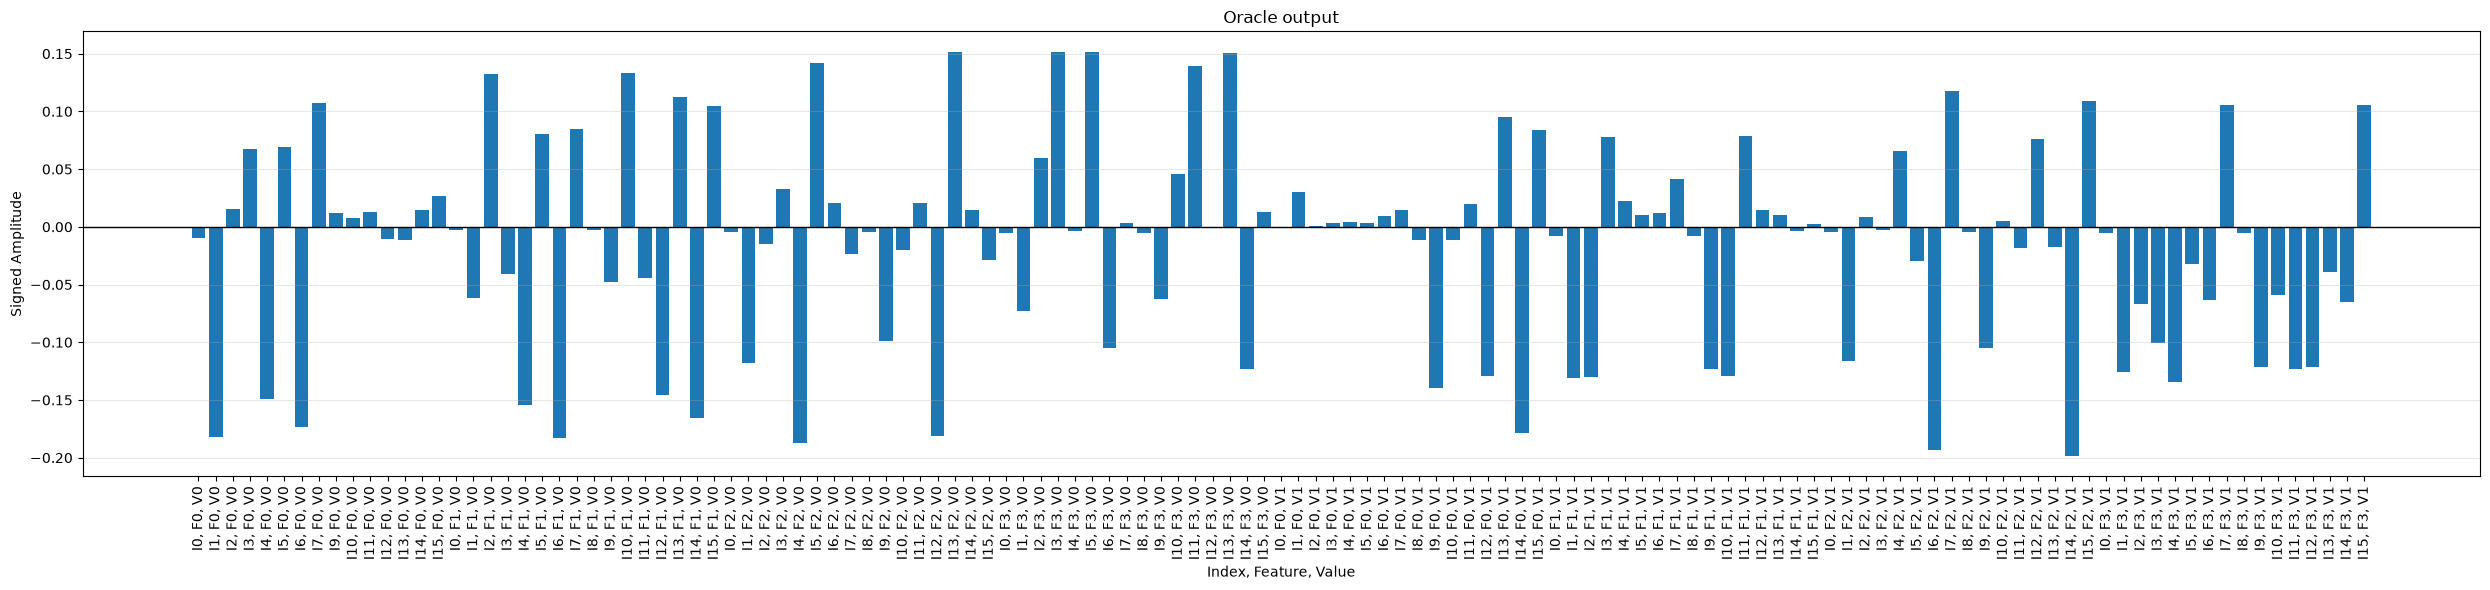


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


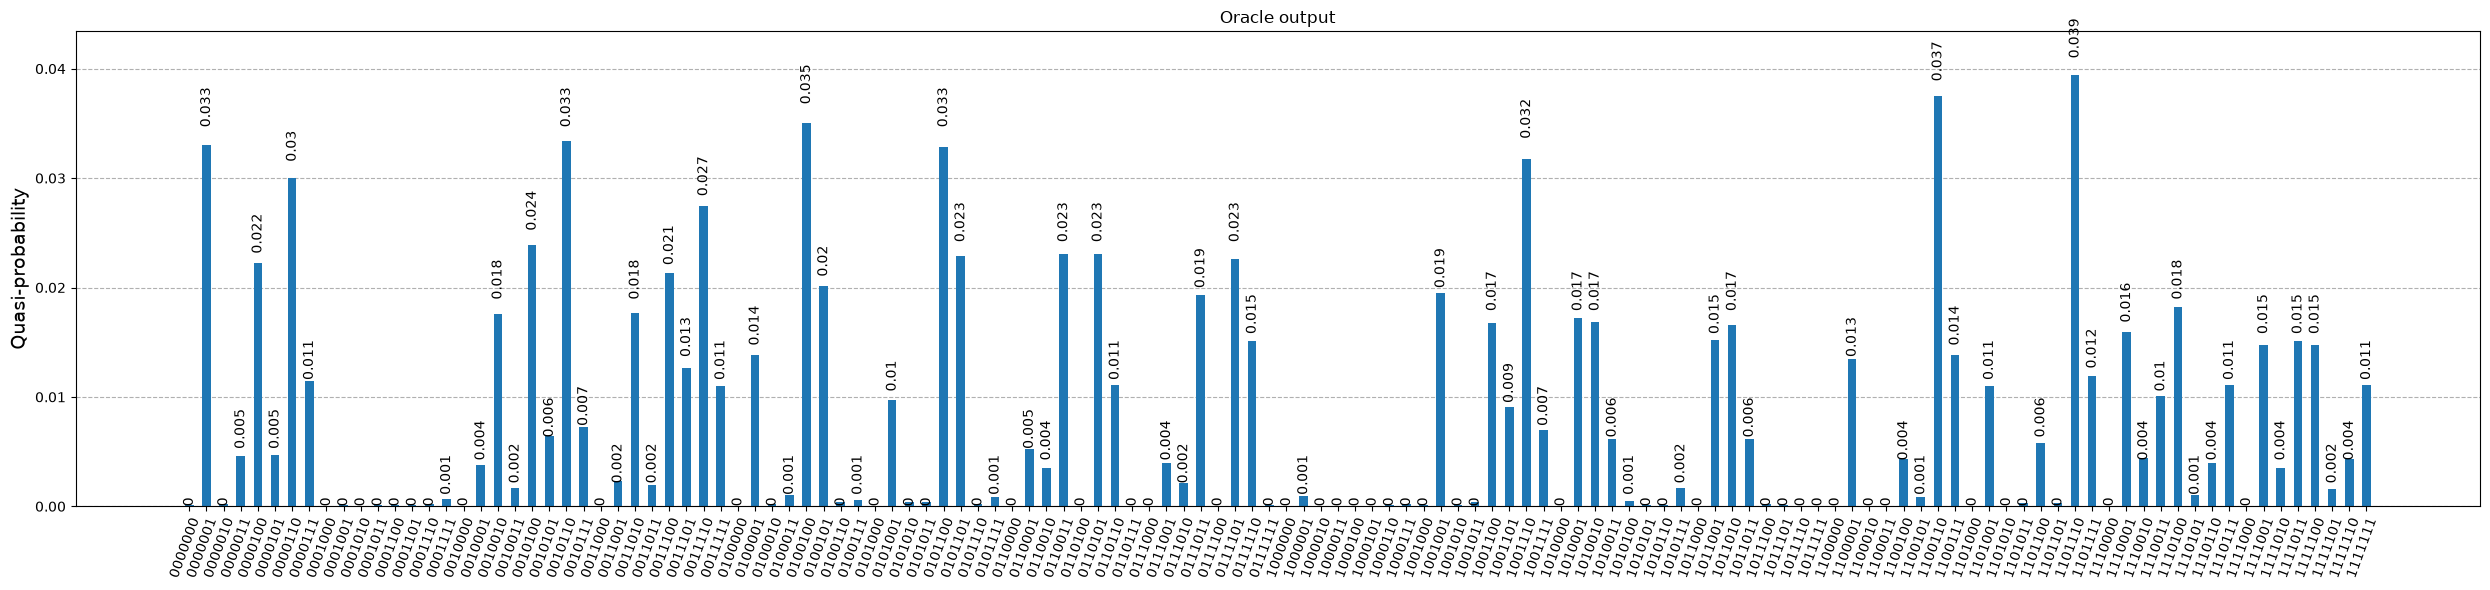

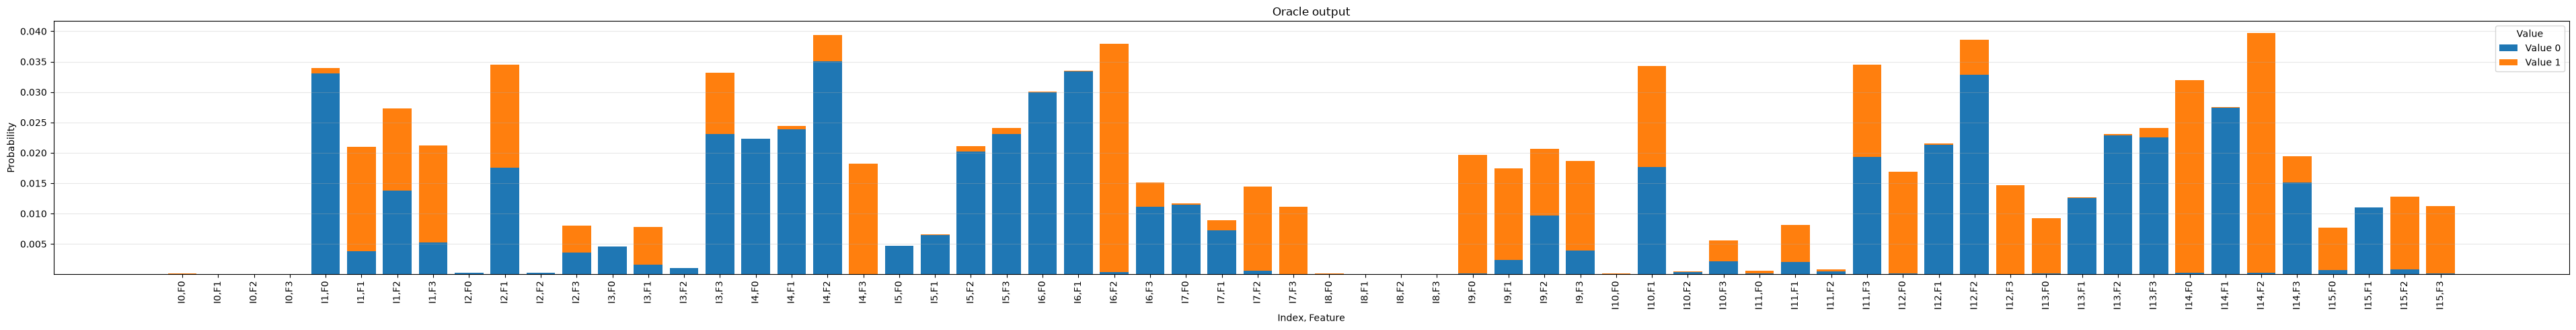


Oracle output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.010                   -0.000                   
0                        1                        -0.003                   -0.008                   
0                        2                        -0.005                   -0.005                   
0                        3                        -0.005                   -0.005                   
1                        0                        -0.182                   +0.030                   
1                        1                        -0.061                   -0.131                   
1                        2                        -0.118                   -0.116                   
1                        3                        -0.073                   -

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.4044852998923118-4.3180647902368183e-16j)
|0000001> : (0.05043384753458204+1.0747973454906998e-16j)
|0000010> : (-0.00418735032510839+1.8086446303312188e-17j)
|0000011> : (-0.01878556433527813-1.9009395818241282e-18j)
|0000100> : (0.041429341102838815+1.153210799198434e-16j)
|0000101> : (-0.019075601495689702-9.356470059382811e-18j)
|0000110> : (0.048062388486384694+9.40818294641039e-17j)
|0000111> : (-0.029660843791207793-5.618577314722536e-18j)
|0001000> : (-0.0018318634677397967+4.400314968215048e-17j)
|0001001> : (-0.0033803789849010755+5.118302251910484e-17j)
|0001010> : (-0.0022023291674312133-9.989657088056788e-18j)
|0001011> : (-0.0034592749677138605+4.5648341367126206e-17j)
|0001100> : (0.0028831935338508026-5.3049240371444255e-18j)
|0001101> : (0.003070801797817058-1.0212039483691084e-17j)
|0001110> : (-0.004062042695611999-7.074618380600465e-17j)
|0001111> : (-0.007314054814054764-1.6210038071710213e-17j)
|0010000> : (-0.11149243

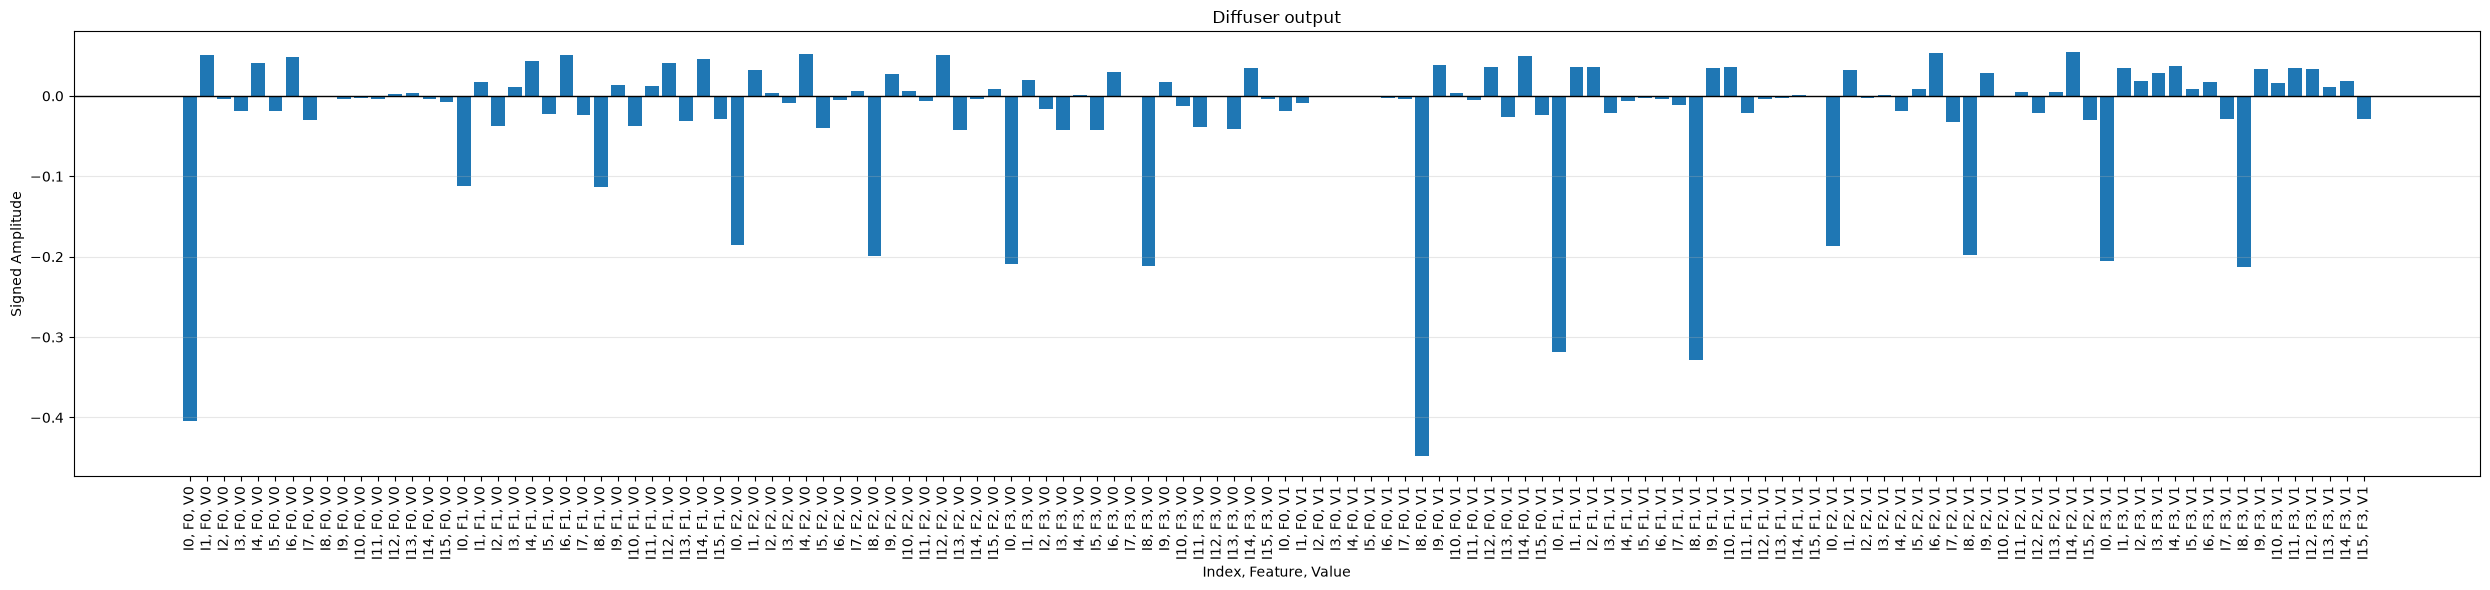


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


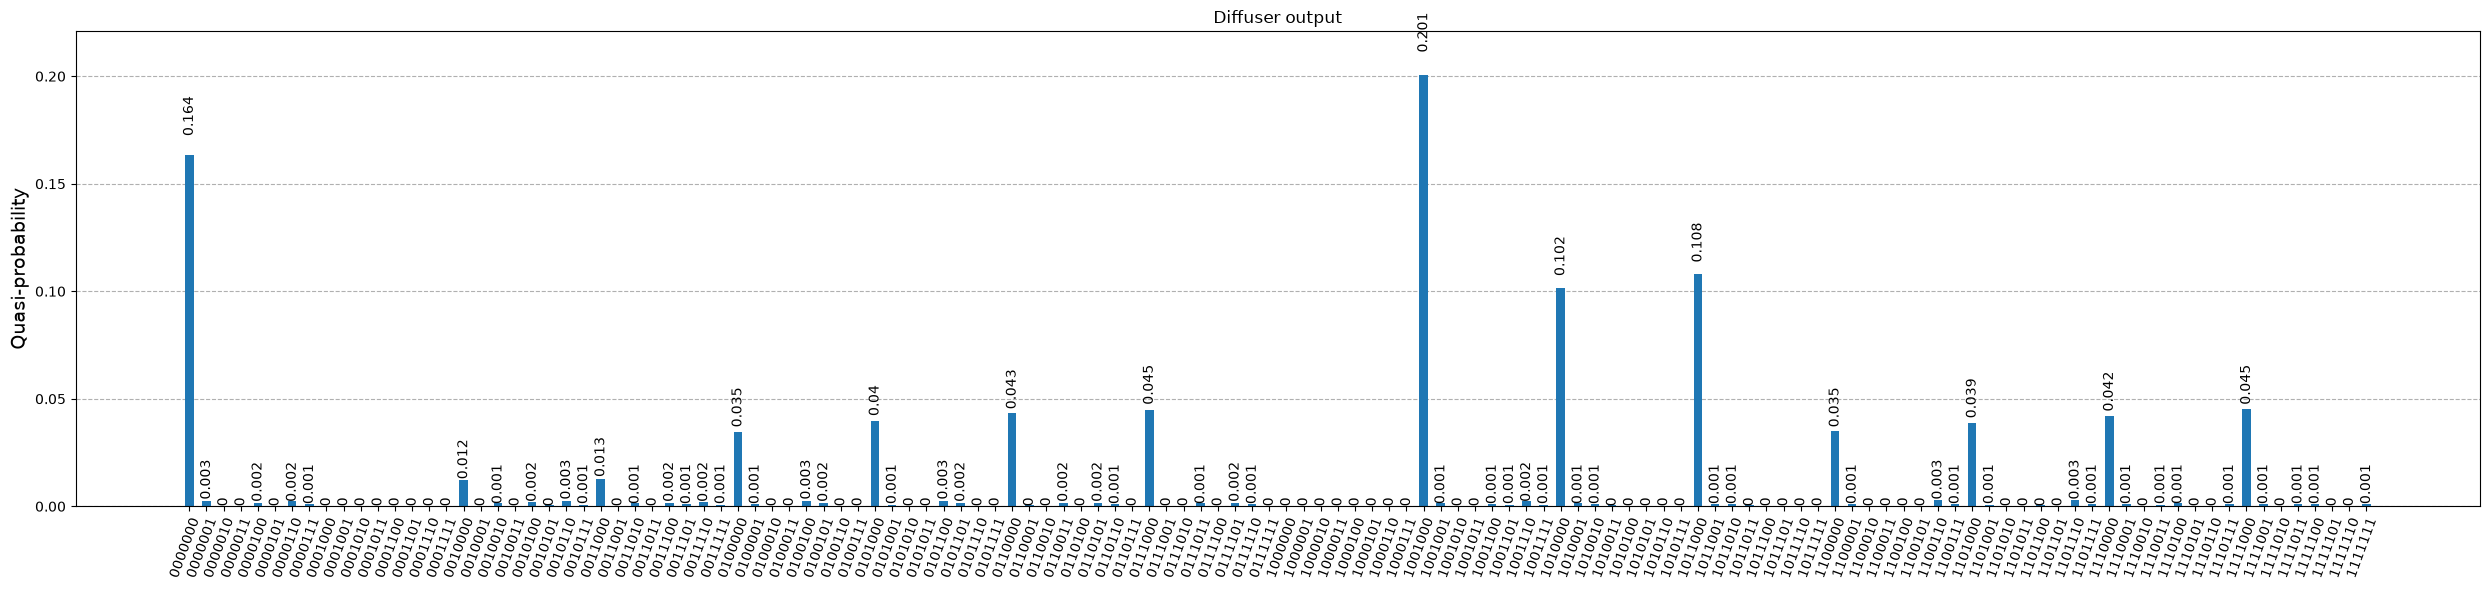

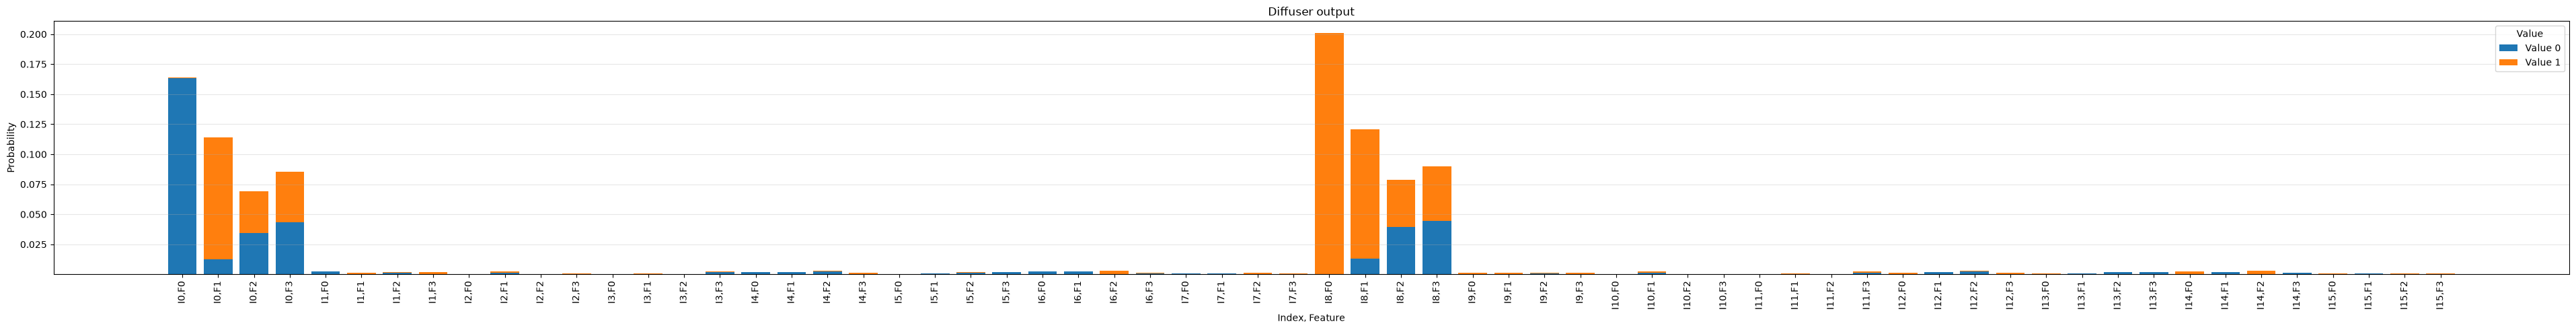


Diffuser output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.404                   -0.019                   
0                        1                        -0.111                   -0.319                   
0                        2                        -0.186                   -0.187                   
0                        3                        -0.209                   -0.205                   
1                        0                        +0.050                   -0.008                   
1                        1                        +0.017                   +0.036                   
1                        2                        +0.033                   +0.032                   
1                        3                        +0.020                  

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.4044852998923117+4.318064790236818e-16j)
|0000001> : (0.050433847534582035+1.0747973454906996e-16j)
|0000010> : (-0.004187350325108391+1.8086446303312182e-17j)
|0000011> : (-0.018785564335278126-1.9009395818241275e-18j)
|0000100> : (0.0414293411028388+1.153210799198434e-16j)
|0000101> : (-0.019075601495689695-9.356470059382816e-18j)
|0000110> : (0.04806238848638468+9.408182946410388e-17j)
|0000111> : (-0.02966084379120779-5.6185773147225346e-18j)
|0001000> : (0.0018318634677397963-4.4003149682150475e-17j)
|0001001> : (-0.003380378984901075+5.118302251910483e-17j)
|0001010> : (-0.0022023291674312133-9.989657088056781e-18j)
|0001011> : (-0.0034592749677138605+4.56483413671262e-17j)
|0001100> : (0.002883193533850802-5.304924037144424e-18j)
|0001101> : (0.0030708017978170574-1.0212039483691083e-17j)
|0001110> : (-0.004062042695611998-7.074618380600464e-17j)
|0001111> : (-0.007314054814054763-1.621003807171021e-17j)
|0010000> : (0.111492430862192

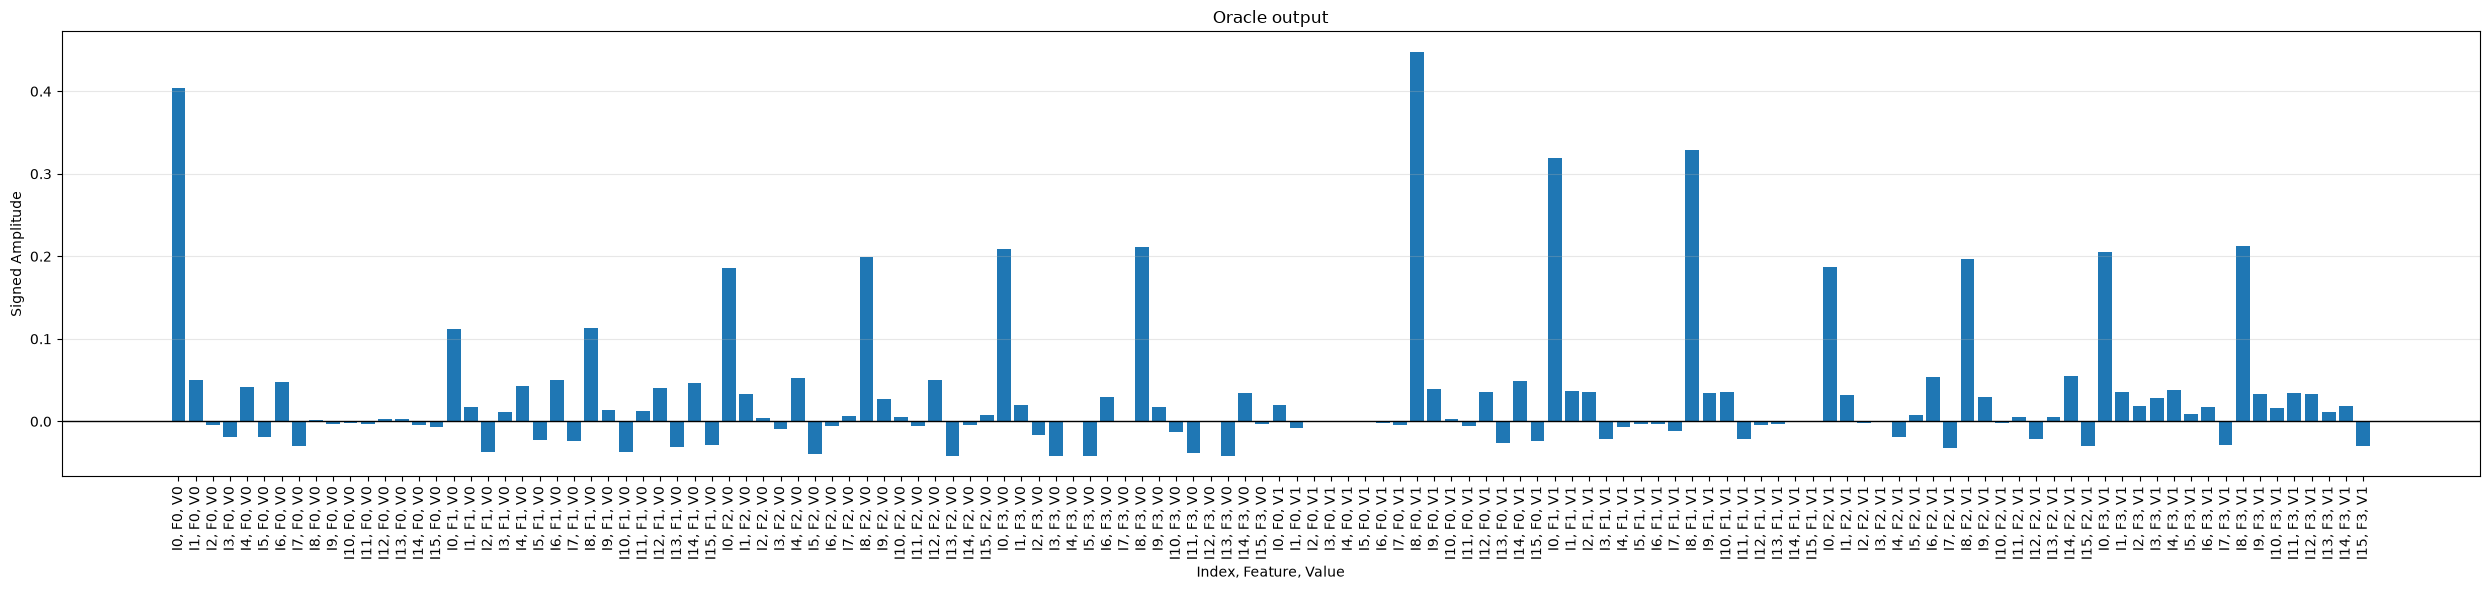


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


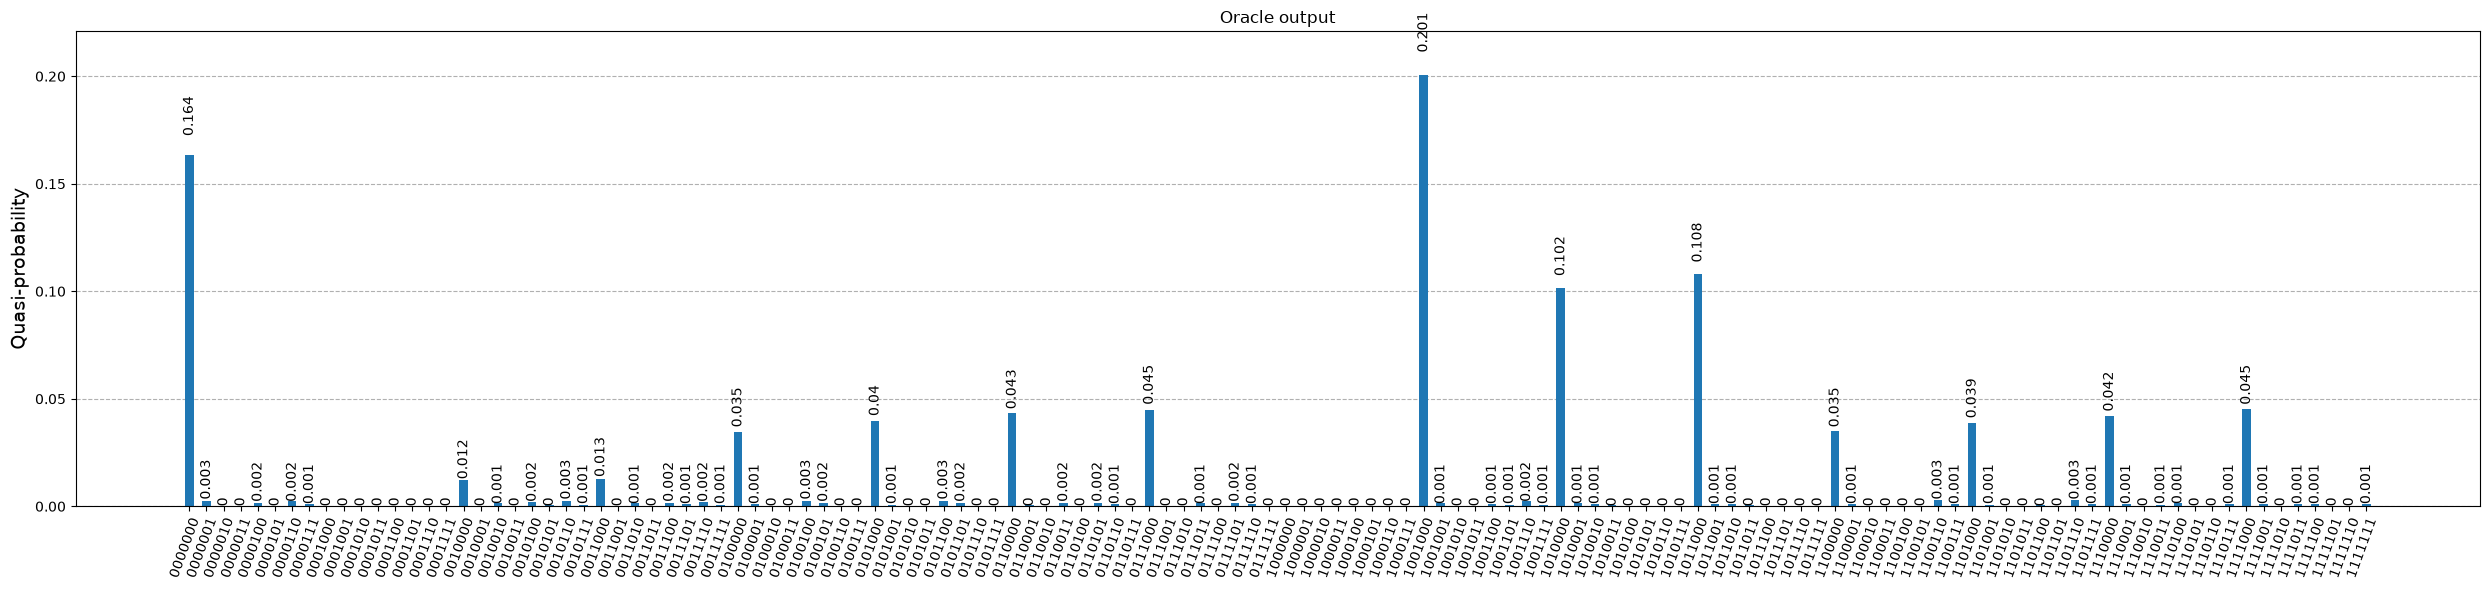

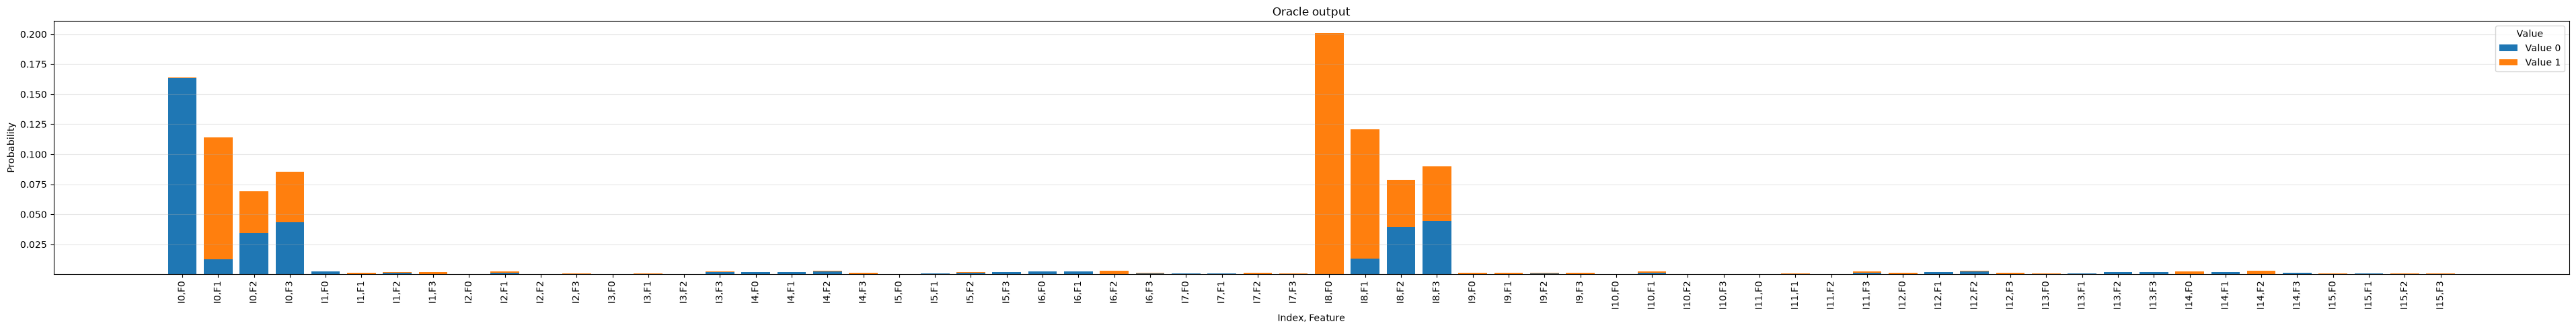


Oracle output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.404                   +0.019                   
0                        1                        +0.111                   +0.319                   
0                        2                        +0.186                   +0.187                   
0                        3                        +0.209                   +0.205                   
1                        0                        +0.050                   -0.008                   
1                        1                        +0.017                   +0.036                   
1                        2                        +0.033                   +0.032                   
1                        3                        +0.020                   +

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.23280261602115426+1.7811127577849958e-16j)
|0000001> : (0.15144259066070032+3.0361090582655756e-16j)
|0000010> : (-0.01257376171436195+3.150563682344609e-17j)
|0000011> : (-0.05640923048766054-1.4023246456051052e-16j)
|0000100> : (0.1244038885131176+2.265915482264798e-16j)
|0000101> : (-0.05728015311418531-7.87265927847412e-17j)
|0000110> : (0.1443215812699624+2.550456461464414e-16j)
|0000111> : (-0.08906548368816698-9.09993932674367e-17j)
|0001000> : (0.0010543340081752624-7.432555289987974e-17j)
|0001001> : (-0.010150590841545482+5.84529536329269e-17j)
|0001010> : (-0.006613146743855055-3.2696782366709717e-17j)
|0001011> : (-0.010387499437933288+5.745939774038099e-17j)
|0001100> : (0.008657644012647734-3.30646658391218e-18j)
|0001101> : (0.009220993487519962-1.979386100617627e-17j)
|0001110> : (-0.012197488378732635-1.0164647656063308e-16j)
|0001111> : (-0.021962619618011558-2.2184768096886087e-17j)
|0010000> : (0.06416977224681904+3.58102

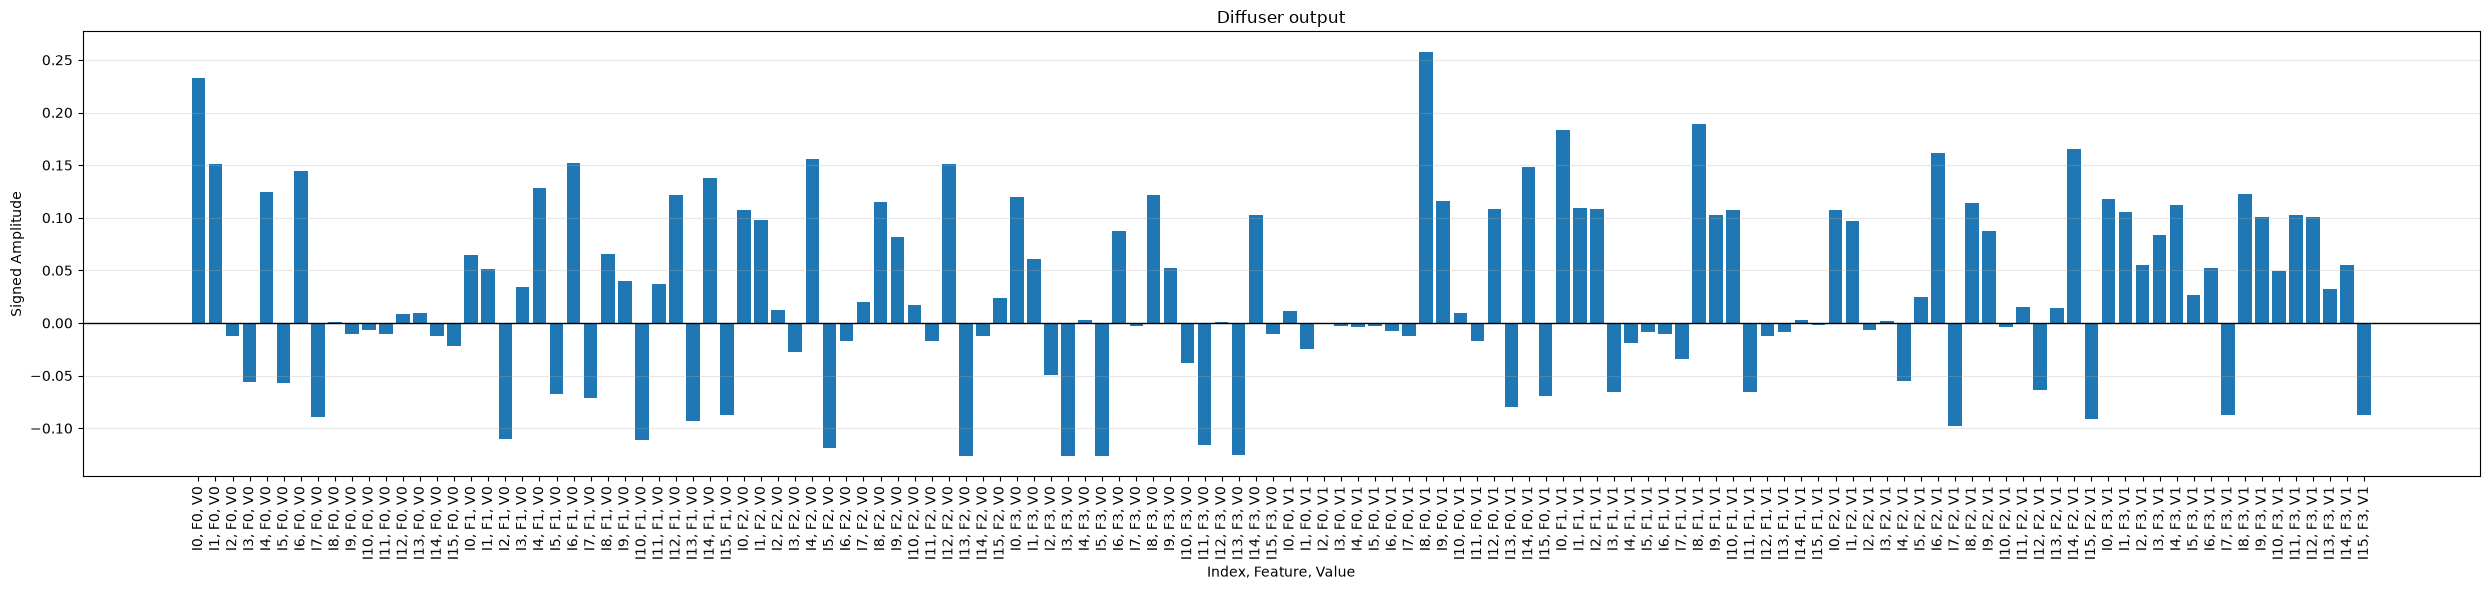


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


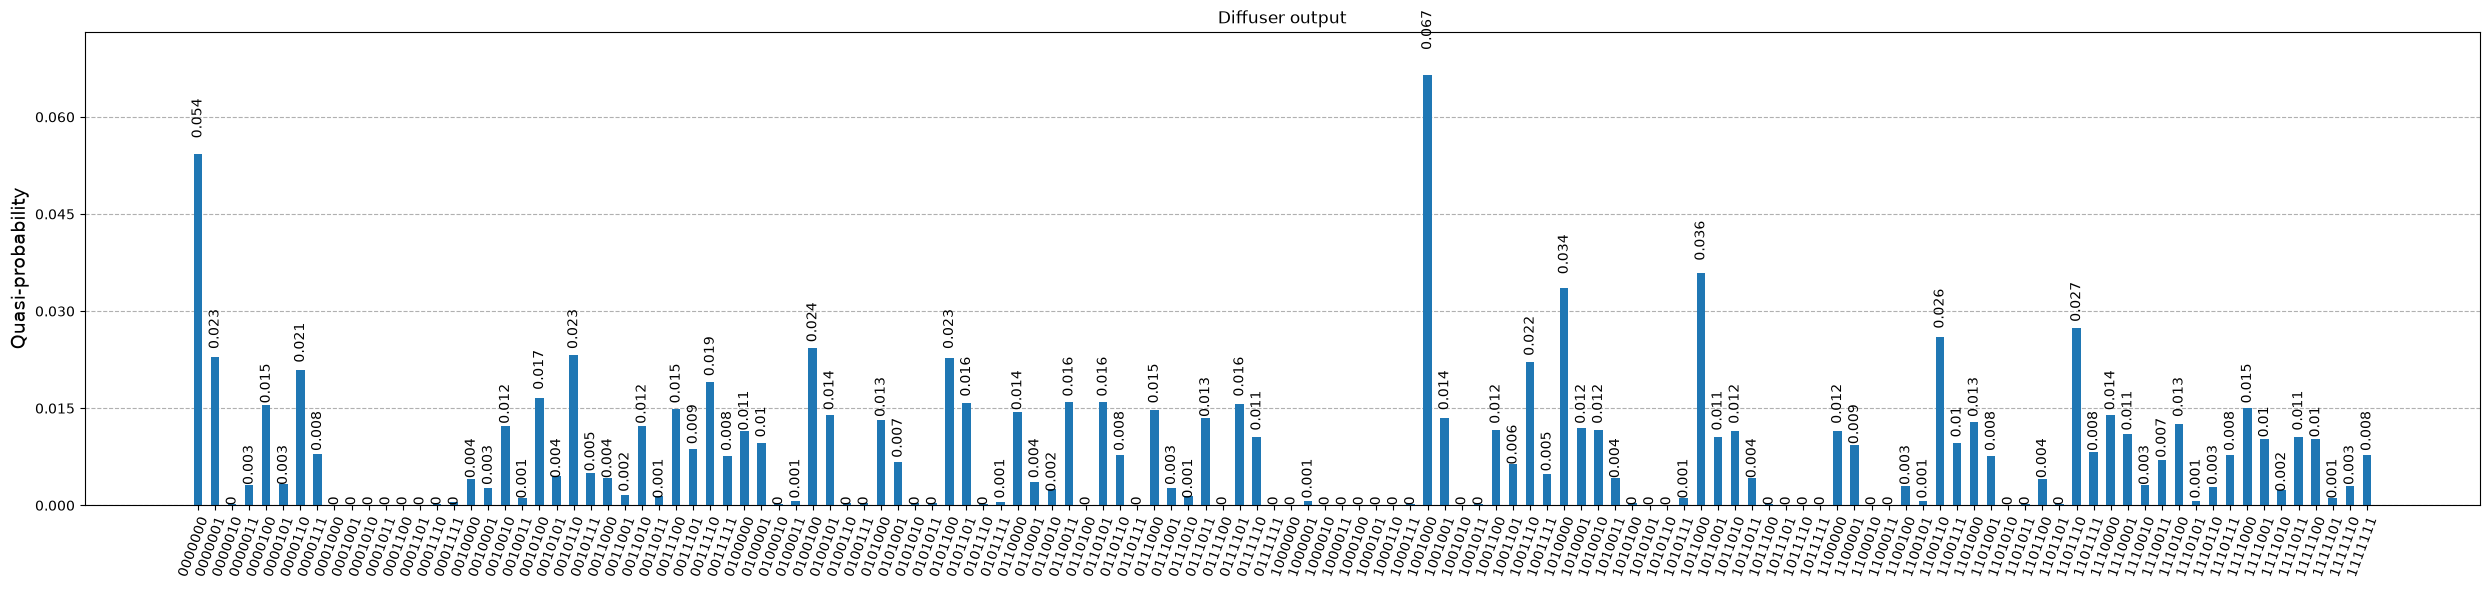

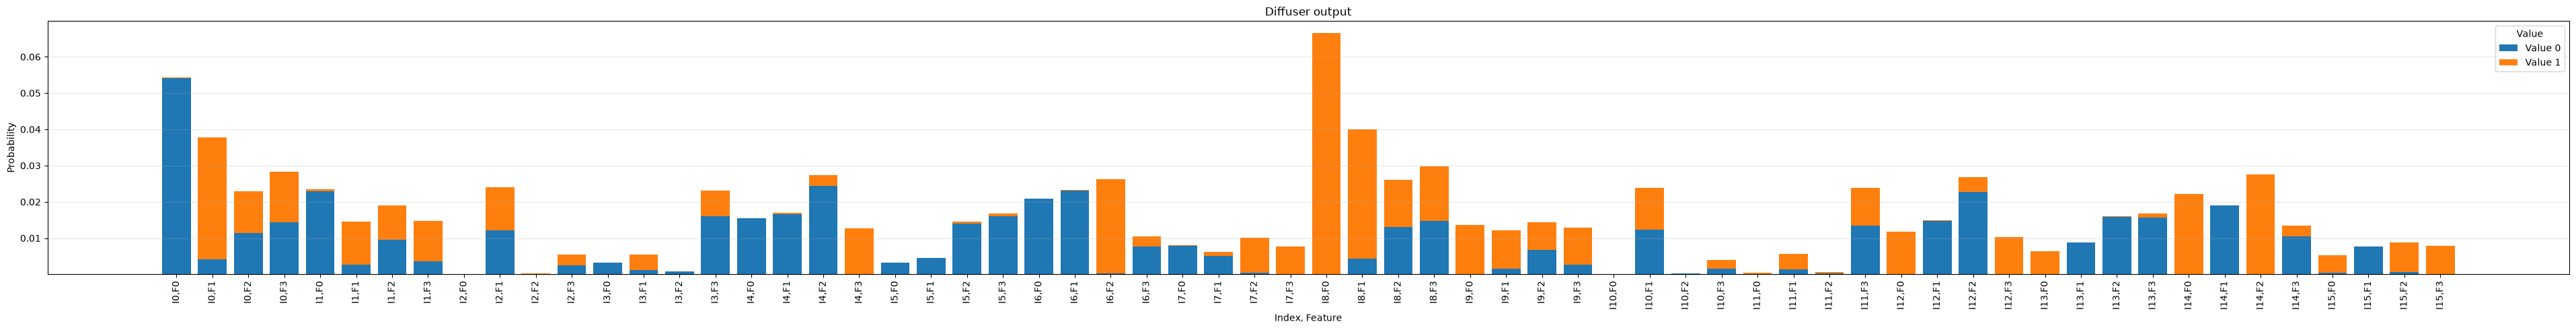


Diffuser output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.233                   +0.011                   
0                        1                        +0.064                   +0.183                   
0                        2                        +0.107                   +0.107                   
0                        3                        +0.120                   +0.118                   
1                        0                        +0.151                   -0.025                   
1                        1                        +0.051                   +0.109                   
1                        2                        +0.098                   +0.097                   
1                        3                        +0.061                  

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.23280261602115424-1.7811127577849953e-16j)
|0000001> : (0.1514425906607003+3.036109058265575e-16j)
|0000010> : (-0.01257376171436195+3.1505636823446093e-17j)
|0000011> : (-0.056409230487660535-1.402324645605105e-16j)
|0000100> : (0.12440388851311758+2.2659154822647977e-16j)
|0000101> : (-0.057280153114185293-7.872659278474119e-17j)
|0000110> : (0.14432158126996236+2.5504564614644137e-16j)
|0000111> : (-0.08906548368816697-9.099939326743667e-17j)
|0001000> : (-0.0010543340081752618+7.432555289987972e-17j)
|0001001> : (-0.01015059084154548+5.845295363292688e-17j)
|0001010> : (-0.006613146743855053-3.2696782366709717e-17j)
|0001011> : (-0.010387499437933288+5.745939774038098e-17j)
|0001100> : (0.008657644012647733-3.3064665839121794e-18j)
|0001101> : (0.00922099348751996-1.9793861006176266e-17j)
|0001110> : (-0.012197488378732631-1.0164647656063308e-16j)
|0001111> : (-0.021962619618011554-2.218476809688608e-17j)
|0010000> : (-0.064169772246819

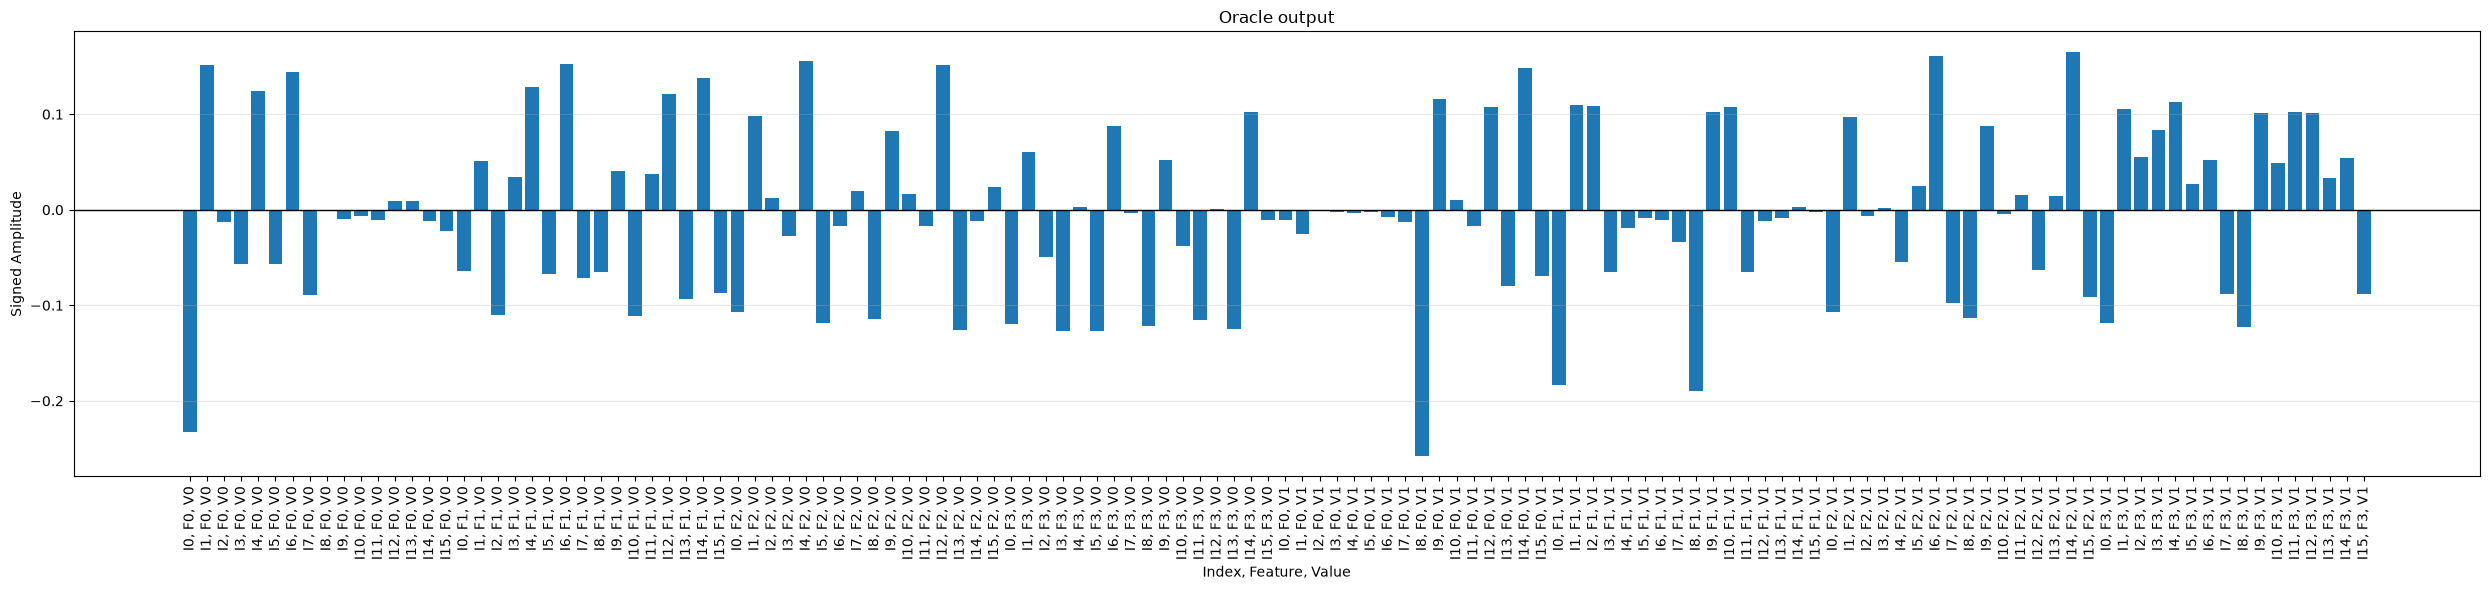


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


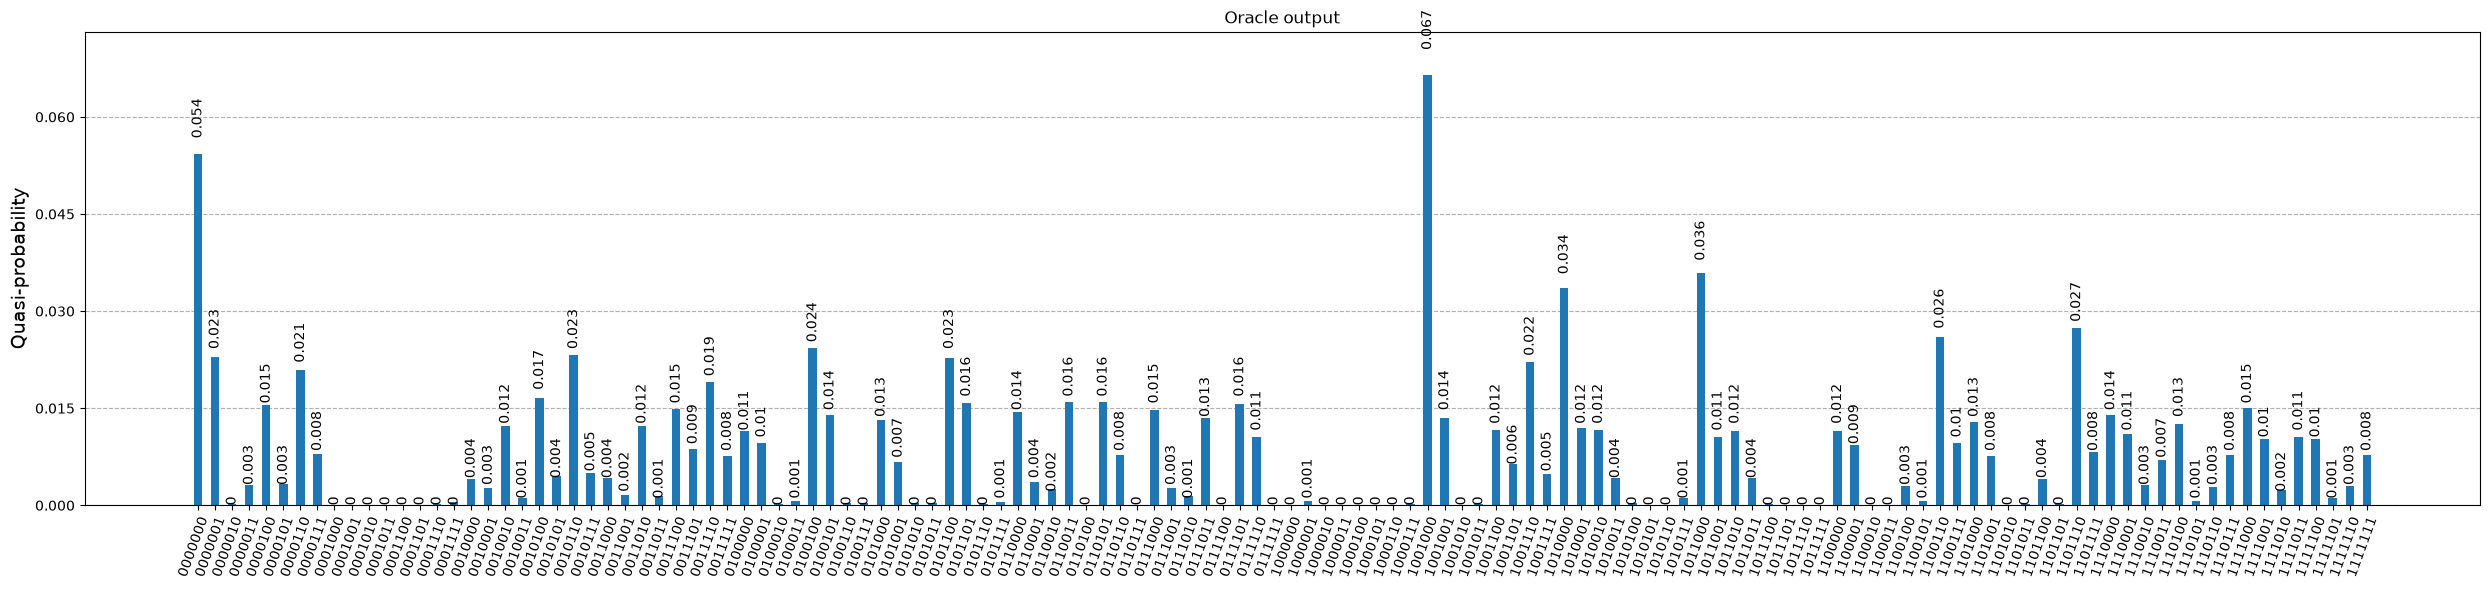

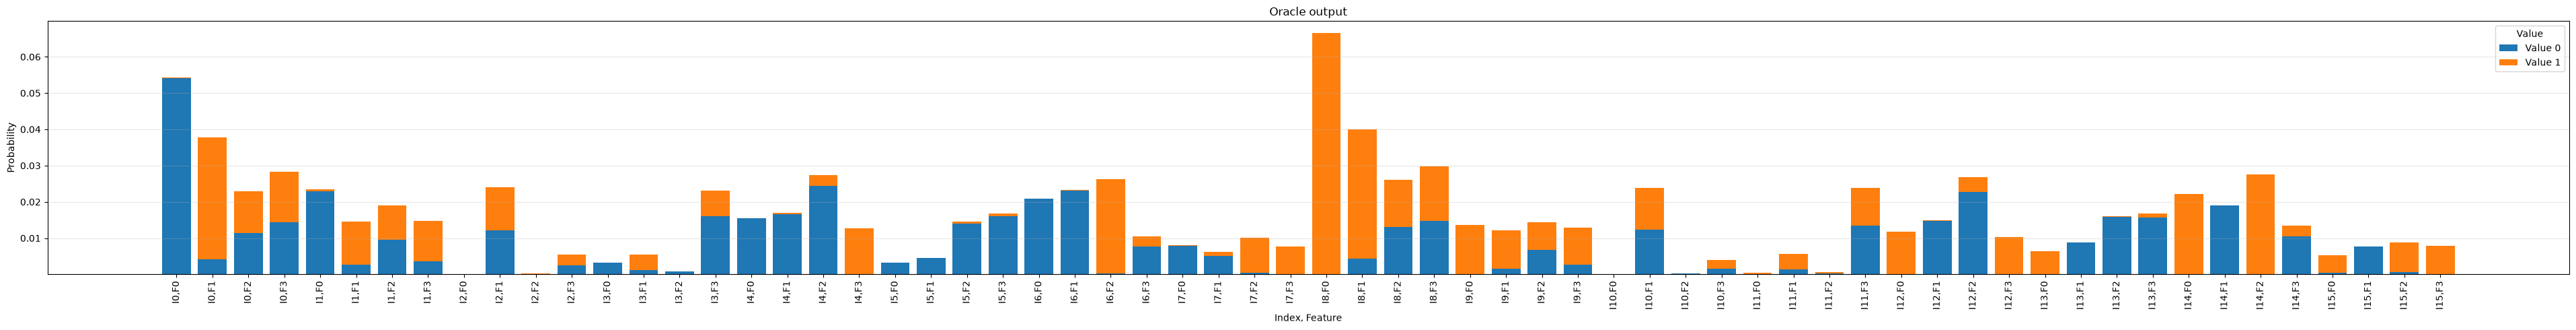


Oracle output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.233                   -0.011                   
0                        1                        -0.064                   -0.183                   
0                        2                        -0.107                   -0.107                   
0                        3                        -0.120                   -0.118                   
1                        0                        +0.151                   -0.025                   
1                        1                        +0.051                   +0.109                   
1                        2                        +0.098                   +0.097                   
1                        3                        +0.061                   +

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.26478557892444826+5.223626243435668e-16j)
|0000001> : (-0.14131120973753436-8.581540444708277e-17j)
|0000010> : (0.011732587715623324+4.7849616669185375e-17j)
|0000011> : (0.05263550079141199+2.362533196653867e-17j)
|0000100> : (-0.11608137384039069-9.402655455708199e-17j)
|0000101> : (0.053448159432583825+8.936831035895536e-17j)
|0000110> : (-0.13466658983789184-1.4862720562681753e-16j)
|0000111> : (0.08310707833856117+1.321714445855807e-16j)
|0001000> : (0.001199180857611061+9.765202921239722e-17j)
|0001001> : (0.009471524919850613+8.508900643192847e-17j)
|0001010> : (0.006170732833273399-4.2414475055607196e-19j)
|0001011> : (0.009692584531989262+8.9883207454851e-17j)
|0001100> : (-0.008078454968095224-1.778396396972776e-17j)
|0001101> : (-0.008604116840702626-3.734469438476851e-17j)
|0001110> : (0.011381486747146037-8.445068181608662e-17j)
|0001111> : (0.020493338985331004+1.5788555689724655e-17j)
|0010000> : (0.07298556426994837+1.975577

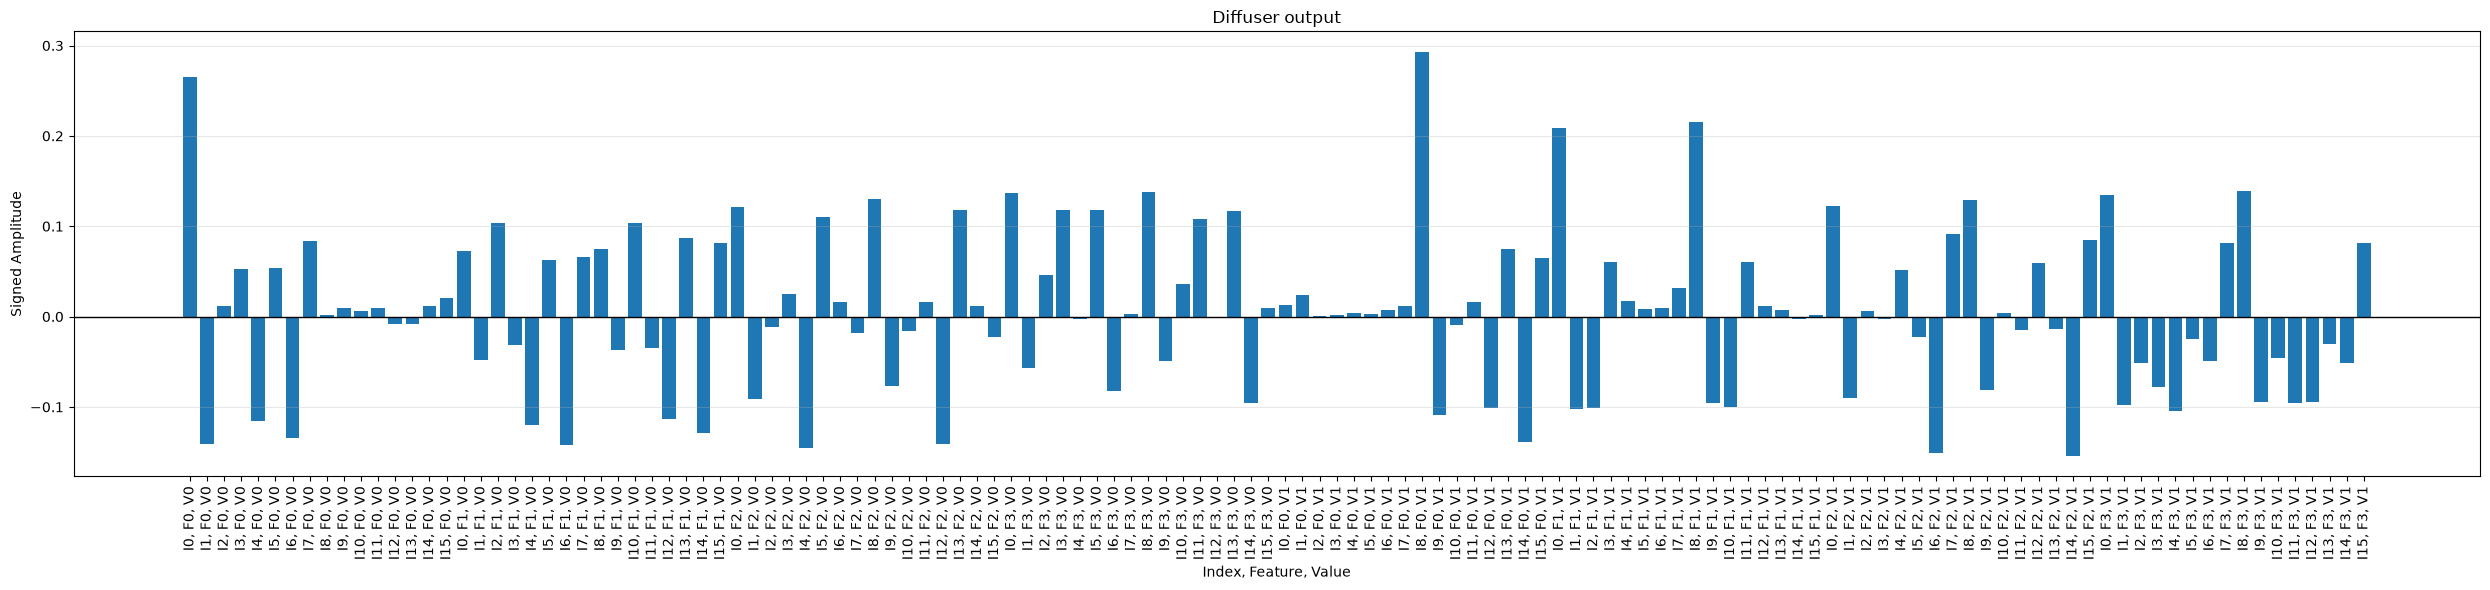


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


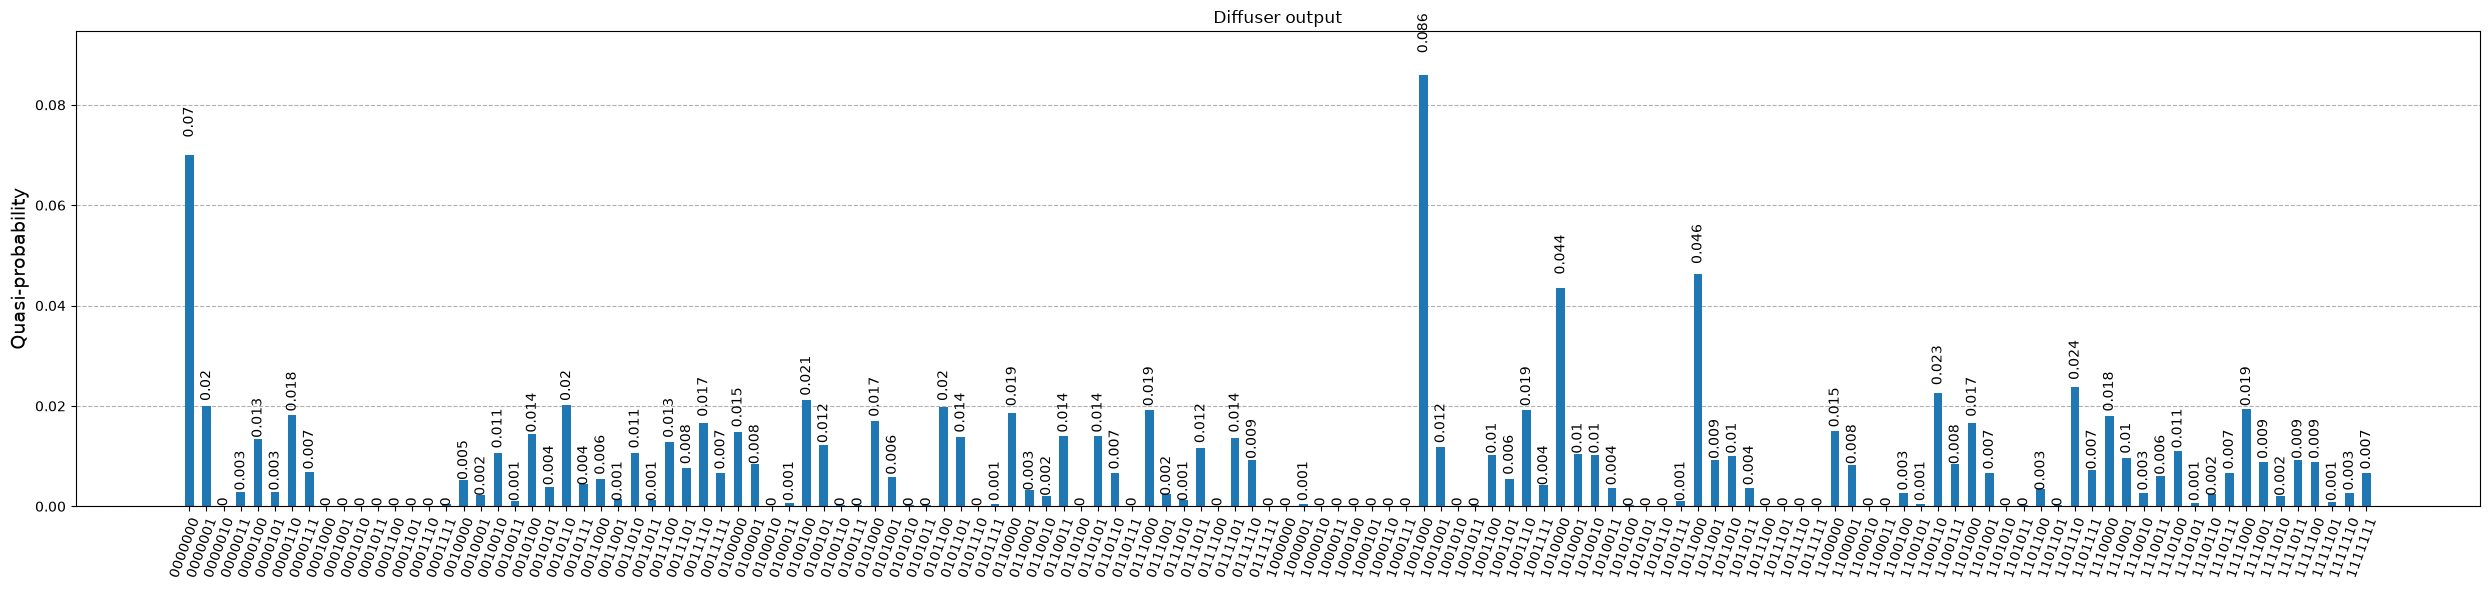

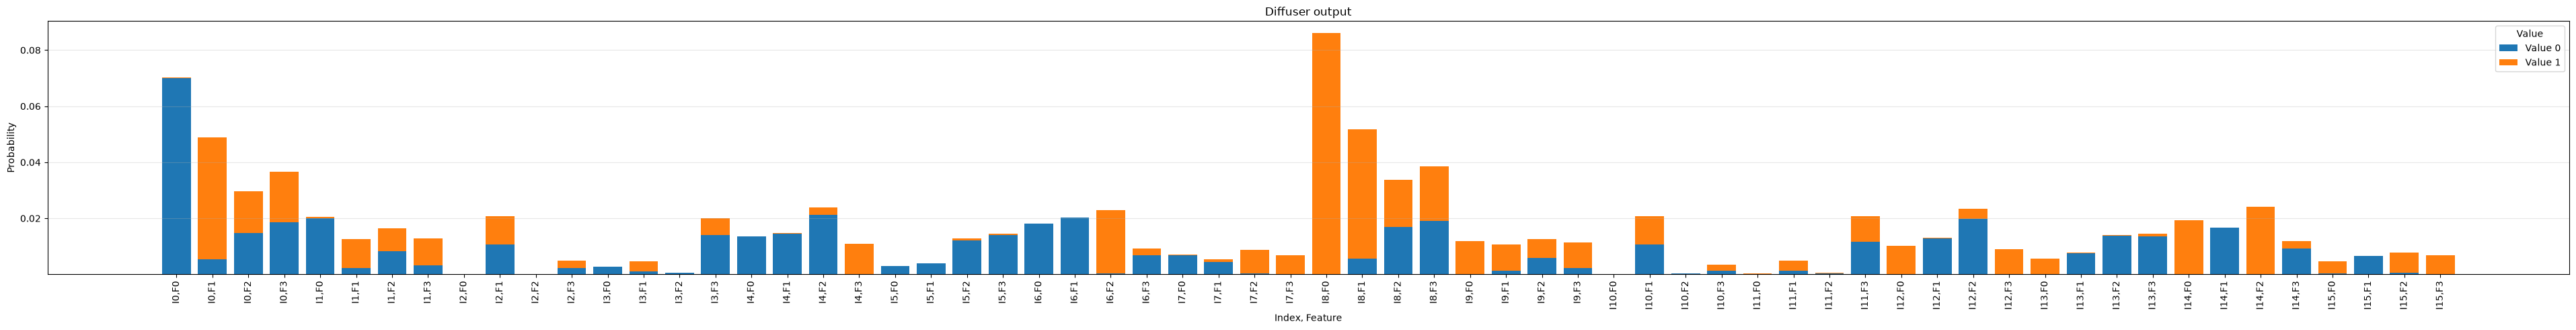


Diffuser output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.265                   +0.013                   
0                        1                        +0.073                   +0.209                   
0                        2                        +0.122                   +0.122                   
0                        3                        +0.136                   +0.134                   
1                        0                        -0.141                   +0.023                   
1                        1                        -0.048                   -0.102                   
1                        2                        -0.091                   -0.090                   
1                        3                        -0.057                  

In [29]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters_neqr_fidelity,
    depth_A=pqc_depth_for_dataset_encoder, depth_B=pqc_depth_for_query_encoder,
    num_of_iter=5
)



In [30]:
GS.draw_circuit()

In [31]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 2
Total qubits: 7
Classical bits: 4

CIRCUIT ANALYSIS
Circuit width: 11
Circuit size: 1355
Circuit depth/layers: 370

OPERATION COUNT
OrderedDict({'ry': 715, 'cx': 506, 'x': 100, 'barrier': 32, 'h': 20, 'ccx': 5, 'mcx': 5, 'measure': 4})
